# Progressive feature reduction using two datasets

This notebook examines how reducing input features affects overall detection and individual attack categories.

The study uses corrected CICIDS2017 and RT-IoT2022 separately. The first step is to download and inspect the source archives.

In [ ]:
from pathlib import Path
import subprocess
import zipfile
import hashlib

RAW_DIR = Path("/content/feature_reduction_two_datasets/data/raw")
RTIOT_ZIP = RAW_DIR / "rt_iot2022" / "rt-iot2022.zip"
CICIDS_ZIP = RAW_DIR / "cicids2017" / "CICIDS2017_improved.zip"

for path in [RTIOT_ZIP, CICIDS_ZIP]:
    path.parent.mkdir(parents=True, exist_ok=True)

print("Download folders are ready.")

Download folders are ready.


## Download RT-IoT2022

The official UCI archive is downloaded into the Colab runtime. The original file is preserved for inspection before cleaning or model training.

In [ ]:
RTIOT_URL = "https://archive.ics.uci.edu/static/public/942/rt-iot2022.zip"

subprocess.run(
    ["wget", "--timeout=60", "--tries=3",
     RTIOT_URL, "-O", str(RTIOT_ZIP)],
    check=True
)

assert zipfile.is_zipfile(RTIOT_ZIP), "The download is not a readable ZIP."
print("RT-IoT2022 ZIP downloaded.")

RT-IoT2022 ZIP downloaded.


Successful completion confirms that the downloaded file can be recognised as a ZIP archive. Its contents and data quality still need to be checked.

## Download corrected CICIDS2017

This study uses the corrected CNS2022 release from DistriNet, consistent with the original experiment. The archive will be inspected before its data are prepared.

In [ ]:
CICIDS_URL = (
    "https://intrusion-detection.distrinet-research.be/"
    "CNS2022/Datasets/CICIDS2017_improved.zip"
)

subprocess.run(
    ["wget", "--timeout=60", "--tries=3",
     CICIDS_URL, "-O", str(CICIDS_ZIP)],
    check=True
)

assert zipfile.is_zipfile(CICIDS_ZIP), "The download is not a readable ZIP."
print("CICIDS2017 ZIP downloaded.")

CICIDS2017 ZIP downloaded.


## Inspect the downloaded archives

The following cell displays archive sizes, file names and SHA-256 fingerprints. The fingerprints identify the downloaded versions; they are not checks against publisher-supplied checksums.

In [ ]:
for path in [RTIOT_ZIP, CICIDS_ZIP]:
    print("\nArchive:", path.name)
    print("Size (MiB):", round(path.stat().st_size / 1024**2, 2))

    with path.open("rb") as stream:
        print("SHA-256:", hashlib.file_digest(stream, "sha256").hexdigest())

    with zipfile.ZipFile(path) as archive:
        members = [item for item in archive.infolist() if not item.is_dir()]
        print("Files:", len(members))
        for item in members[:15]:
            print(item.filename, "| bytes:", item.file_size)


Archive: rt-iot2022.zip
Size (MiB): 3.29
SHA-256: bcaa24d62abbb1215be576d5cf9c02dfcb0bb7c4c2f5a00e03055afaa1ed109e
Files: 1
RT_IOT2022 | bytes: 54781794

Archive: CICIDS2017_improved.zip
Size (MiB): 327.63
SHA-256: 97fdb91d339e2d8cf5627f981b831e5e7e400b981c58181c451a38fd03c48883
Files: 5
friday.csv | bytes: 285188226
monday.csv | bytes: 207875155
thursday.csv | bytes: 189519159
tuesday.csv | bytes: 178397720
wednesday.csv | bytes: 291290505


### Download results

Both source archives were downloaded and their contents were listed successfully.

RT-IoT2022 contains one data file. Corrected CICIDS2017 contains five daily CSV files. The displayed SHA-256 fingerprints identify the downloaded archives.

The next step is to inspect their columns and structure. Data cleaning and model training have not started.

## Inspect the CICIDS2017 columns

I first read the column names from each daily file without loading the complete dataset. This allows me to check whether the files have the same structure before combining them.

In [ ]:
import pandas as pd

cicids_schemas = {}

with zipfile.ZipFile(CICIDS_ZIP) as archive:
    for filename in sorted(archive.namelist()):
        if filename.lower().endswith(".csv"):
            with archive.open(filename) as stream:
                columns = pd.read_csv(stream, nrows=0).columns
                columns = columns.str.strip().tolist()

            cicids_schemas[filename] = columns

print("CSV files inspected:", len(cicids_schemas))

CSV files inspected: 5


### Compare the daily file structures

The first file is used as a reference. I compare both the column names and their order across all five files.

Matching columns would allow consistent loading. This check does not establish that the values or labels are correct.

In [ ]:
reference_columns = next(iter(cicids_schemas.values()))
schema_rows = []

for filename, columns in cicids_schemas.items():
    schema_rows.append({
        "File": filename,
        "Number of columns": len(columns),
        "Same columns and order": columns == reference_columns
    })

display(pd.DataFrame(schema_rows))

print("CICIDS2017 column names:")
print(reference_columns)

,File,Number of columns,Same columns and order
0,friday.csv,91,True
1,monday.csv,91,True
2,thursday.csv,91,True
3,tuesday.csv,91,True
4,wednesday.csv,91,True


CICIDS2017 column names:
['id', 'Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN F

## Inspect the RT-IoT2022 structure

I read the first 1,000 rows to inspect column names, data types and example records.

This is a structural sample. It cannot establish the full class distribution or show whether the complete dataset contains missing values or duplicates.

In [ ]:
with zipfile.ZipFile(RTIOT_ZIP) as archive:
    rt_filename = next(
        name for name in archive.namelist()
        if Path(name).name == "RT_IOT2022"
    )

    with archive.open(rt_filename) as stream:
        rt_sample = pd.read_csv(stream, nrows=1_000)

rt_sample.columns = rt_sample.columns.str.strip()

print("Sample shape:", rt_sample.shape)
print("Column names:")
print(rt_sample.columns.tolist())

Sample shape: (1000, 85)
Column names:
['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'f

### Inspect example values and data types

I display a few records and count the data types found in the sample. This helps identify numeric fields, categorical fields and the label column.

The full dataset will be checked separately before preprocessing decisions are made.

In [ ]:
display(rt_sample.head(3))

print("Data types in the sample:")
display(rt_sample.dtypes.value_counts())

print("Non-numeric columns:")
print(rt_sample.select_dtypes(exclude="number").columns.tolist())

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish


Data types in the sample:


,count
float64,56
int64,26
object,3


Non-numeric columns:
['proto', 'service', 'Attack_type']


### Structure inspection findings

All five CICIDS2017 files have 91 columns with matching names and order.

The RT-IoT2022 sample has 85 columns: 82 numeric and three non-numeric. The non-numeric columns are proto, service and Attack_type. Attack_type is the target label.

These totals include labels and other fields that may be excluded from model inputs. The sample does not establish the full class distribution or data quality.

## Load the complete RT-IoT2022 table

I now load the complete table to count all records and traffic categories. The original columns and labels are retained.

In [ ]:
with zipfile.ZipFile(RTIOT_ZIP) as archive:
    with archive.open(rt_filename) as stream:
        rt_df = pd.read_csv(stream, low_memory=False)

rt_df.columns = rt_df.columns.str.strip()

assert not rt_df.columns.duplicated().any(), "Duplicate column names found."

print("Complete RT-IoT2022 shape:", rt_df.shape)

Complete RT-IoT2022 shape: (123117, 85)


### Count the provided traffic categories

I count every category in Attack_type across the complete dataset. I also check for missing or blank labels.

Whitespace is removed in a separate inspection Series; the original table is unchanged.

In [ ]:
rt_labels = rt_df["Attack_type"].astype("string").str.strip()

rt_label_counts = (
    rt_labels.value_counts(dropna=False)
    .rename_axis("Traffic category")
    .reset_index(name="Rows")
)

display(rt_label_counts)

print("Total counted rows:", rt_label_counts["Rows"].sum())
print("Missing labels:", rt_labels.isna().sum())
print("Blank labels:", rt_labels.eq("").sum())

,Traffic category,Rows
0,DOS_SYN_Hping,94659
1,Thing_Speak,8108
2,ARP_poisioning,7750
3,MQTT_Publish,4146
4,NMAP_UDP_SCAN,2590
5,NMAP_XMAS_TREE_SCAN,2010
6,NMAP_OS_DETECTION,2000
7,NMAP_TCP_scan,1002
8,DDOS_Slowloris,534
9,Wipro_bulb,253


Total counted rows: 123117
Missing labels: 0
Blank labels: 0


## Count CICIDS2017 records and provided labels

I read Label and Attempted Category from every daily file in chunks. This counts the complete dataset while limiting memory use.

The provided labels and attempted-category codes are counted separately. No labels are changed in this step.

In [ ]:
from collections import Counter

cicids_label_counts = Counter()
cicids_attempted_codes = Counter()
cicids_daily_counts = []

with zipfile.ZipFile(CICIDS_ZIP) as archive:
    for filename in cicids_schemas:
        file_rows = 0

        with archive.open(filename) as stream:
            reader = pd.read_csv(
                stream,
                usecols=lambda name: name.strip() in ["Label", "Attempted Category"],
                chunksize=200_000,
                low_memory=False
            )

            for chunk in reader:
                chunk.columns = chunk.columns.str.strip()
                labels = chunk["Label"].astype("string").str.strip()
                cicids_label_counts.update(labels.value_counts(dropna=False).to_dict())
                cicids_attempted_codes.update(
                    chunk["Attempted Category"].value_counts(dropna=False).to_dict()
                )
                file_rows += len(chunk)

        cicids_daily_counts.append({"File": filename, "Rows": file_rows})
        print(filename, "| rows:", file_rows)

friday.csv | rows: 547557
monday.csv | rows: 371624
thursday.csv | rows: 362076
tuesday.csv | rows: 322078
wednesday.csv | rows: 496641


### Review the complete CICIDS2017 label counts

The tables show records per day, provided label frequencies and attempted-category codes.

These are source-data counts before cleaning or label preparation. Attempted flows will be handled explicitly according to the corrected dataset documentation before modeling.

In [ ]:
cicids_daily_df = pd.DataFrame(cicids_daily_counts)

cicids_labels_df = (
    pd.Series(cicids_label_counts, name="Rows")
    .rename_axis("Provided label")
    .reset_index()
    .sort_values("Rows", ascending=False)
)

display(cicids_daily_df)
display(cicids_labels_df)

print("Total CICIDS2017 rows:", cicids_daily_df["Rows"].sum())

assert cicids_labels_df["Rows"].sum() == cicids_daily_df["Rows"].sum()

,File,Rows
0,friday.csv,547557
1,monday.csv,371624
2,thursday.csv,362076
3,tuesday.csv,322078
4,wednesday.csv,496641


,Provided label,Rows
0,BENIGN,1582566
2,Portscan,159066
18,DoS Hulk,158468
1,DDoS,95144
5,Infiltration - Portscan,71767
24,DoS GoldenEye,7567
3,Botnet - Attempted,4067
14,FTP-Patator,3972
19,DoS Slowloris,3859
20,DoS Slowhttptest - Attempted,3368


Total CICIDS2017 rows: 2099976


In [ ]:
cicids_attempted_df = (
    pd.Series(cicids_attempted_codes, name="Rows")
    .rename_axis("Attempted Category")
    .reset_index()
)

display(cicids_attempted_df)

assert cicids_attempted_df["Rows"].sum() == cicids_daily_df["Rows"].sum()

,Attempted Category,Rows
0,-1,2087997
1,1,4067
2,0,4845
3,4,75
4,2,23
5,3,27
6,6,2804
7,5,138


### Initial CICIDS2017 findings

The five files contain 2,099,976 records. Of these, 11,979 have an Attempted Category value other than -1.

The provided labels include attempted attacks and very small attack categories. For example, Heartbleed has 11 records and Web Attack - SQL Injection has 13 before further preparation.

Following the corrected dataset documentation, attempted flows will be treated as BENIGN for modeling. They will not be deleted. These counts describe the source data before duplicate and quality checks.

Source: https://intrusion-detection.distrinet-research.be/CNS2022/Dataset_Download.html

## Prepare the CICIDS2017 modeling labels

This function checks that labels and attempted-category codes are valid. It creates a separate label Series in which attempted flows are treated as BENIGN.

The original Label column is not overwritten. Other attack categories retain their names for later analysis.

In [ ]:
def prepare_cicids_labels(chunk):
    labels = chunk["Label"].astype("string").str.strip()
    codes = pd.to_numeric(chunk["Attempted Category"], errors="raise")

    assert labels.notna().all(), "Missing labels found."
    assert labels.ne("").all(), "Blank labels found."
    assert codes.isin([-1, 0, 1, 2, 3, 4, 5, 6]).all(), "Unexpected codes found."

    attempted_mask = codes.ne(-1)
    modeling_labels = labels.mask(attempted_mask, "BENIGN")

    return modeling_labels, attempted_mask

### Apply the label rule to every record

I process the two label columns in chunks and count the resulting modeling categories. This verifies the effect of the rule across the complete dataset without loading all predictors.

The counters are reset whenever this cell runs, preventing repeated execution from counting records twice.

In [ ]:
cicids_model_label_counts = Counter()
cicids_relabelled_rows = 0

with zipfile.ZipFile(CICIDS_ZIP) as archive:
    for filename in cicids_schemas:
        with archive.open(filename) as stream:
            reader = pd.read_csv(
                stream,
                usecols=lambda name: name.strip() in ["Label", "Attempted Category"],
                chunksize=200_000,
                low_memory=False
            )

            for chunk in reader:
                chunk.columns = chunk.columns.str.strip()
                modeling_labels, attempted_mask = prepare_cicids_labels(chunk)
                cicids_model_label_counts.update(modeling_labels.value_counts().to_dict())
                cicids_relabelled_rows += int(attempted_mask.sum())

        print("Processed:", filename)

Processed: friday.csv
Processed: monday.csv
Processed: thursday.csv
Processed: tuesday.csv
Processed: wednesday.csv


### Check the modeling-label distribution

The following table shows the categories after attempted flows are assigned to BENIGN.

For binary classification, BENIGN will be coded as 0 and the remaining attack categories as 1. Their individual names will also be retained for attack-level evaluation.

In [ ]:
cicids_model_distribution = (
    pd.Series(cicids_model_label_counts, name="Rows")
    .rename_axis("Modeling category")
    .reset_index()
    .sort_values("Rows", ascending=False)
)

display(cicids_model_distribution)

cicids_total_rows = int(cicids_model_distribution["Rows"].sum())
cicids_benign_rows = int(cicids_model_label_counts["BENIGN"])

print("Attempted flows assigned to BENIGN:", cicids_relabelled_rows)
print("BENIGN rows:", cicids_benign_rows)
print("Attack rows:", cicids_total_rows - cicids_benign_rows)

assert cicids_total_rows == cicids_daily_df["Rows"].sum()

,Modeling category,Rows
0,BENIGN,1594545
2,Portscan,159066
11,DoS Hulk,158468
1,DDoS,95144
4,Infiltration - Portscan,71767
14,DoS GoldenEye,7567
9,FTP-Patator,3972
12,DoS Slowloris,3859
10,SSH-Patator,2961
13,DoS Slowhttptest,1740


Attempted flows assigned to BENIGN: 11979
BENIGN rows: 1594545
Attack rows: 505431


### CICIDS2017 label-preparation findings

After assigning attempted flows to BENIGN, the dataset contains 1,594,545 benign and 505,431 attack records. All 2,099,976 records are retained.

The modeling categories consist of BENIGN and 15 attack categories. Their individual names remain available for attack-level analysis.

Some categories have very few observations, including Heartbleed with 11 and SQL Injection with 13. Their later detection results will require careful interpretation.

## Prepare the RT-IoT2022 labels

I first check the labels across the complete dataset. Missing or blank labels must be reviewed before creating the binary target.

The original Attack_type column is preserved.

In [ ]:
rt_diagnostic_labels = rt_df["Attack_type"].astype("string").str.strip()

assert rt_diagnostic_labels.notna().all(), "Missing labels found."
assert rt_diagnostic_labels.ne("").all(), "Blank labels found."

print("Total RT-IoT2022 rows:", len(rt_df))

display(
    rt_diagnostic_labels.value_counts()
    .rename_axis("Original category")
    .reset_index(name="Rows"))

Total RT-IoT2022 rows: 123117


,Original category,Rows
0,DOS_SYN_Hping,94659
1,Thing_Speak,8108
2,ARP_poisioning,7750
3,MQTT_Publish,4146
4,NMAP_UDP_SCAN,2590
5,NMAP_XMAS_TREE_SCAN,2010
6,NMAP_OS_DETECTION,2000
7,NMAP_TCP_scan,1002
8,DDOS_Slowloris,534
9,Wipro_bulb,253


### Define the binary label mapping

Thing_Speak, MQTT_Publish and Wipro_bulb represent normal traffic. The nine listed attack categories represent malicious traffic.

I explicitly check every observed category against these lists before creating the target.

In [ ]:
RT_BENIGN_LABELS = {"Thing_Speak", "MQTT_Publish", "Wipro_bulb"}

RT_ATTACK_LABELS = {
    "DOS_SYN_Hping", "ARP_poisioning", "NMAP_UDP_SCAN",
    "NMAP_XMAS_TREE_SCAN", "NMAP_OS_DETECTION", "NMAP_TCP_scan",
    "DDOS_Slowloris", "Metasploit_Brute_Force_SSH", "NMAP_FIN_SCAN"
}

observed_labels = set(rt_diagnostic_labels.unique())
expected_labels = RT_BENIGN_LABELS | RT_ATTACK_LABELS

print("Unexpected categories:", observed_labels - expected_labels)
print("Expected categories not found:", expected_labels - observed_labels)

assert observed_labels == expected_labels, "Review the category mapping."

Unexpected categories: set()
Expected categories not found: set()


### Create the RT-IoT2022 binary target

The binary target uses 0 for benign traffic and 1 for attack traffic. The original categories remain separate for later analysis.

This defines a binary detection task, not a model that predicts the individual attack type.

In [ ]:
rt_binary_target = (
    rt_diagnostic_labels.isin(RT_ATTACK_LABELS)
    .astype("int8")
)

rt_binary_counts = (
    rt_binary_target.value_counts()
    .sort_index()
    .rename_axis("Binary target")
    .reset_index(name="Rows")
)

display(rt_binary_counts)

assert rt_binary_counts["Rows"].sum() == len(rt_df)

,Binary target,Rows
0,0,12507
1,1,110610


The table reports the benign and attack counts under the declared mapping. No rows were removed or resampled.

The original traffic categories are retained so that strong overall binary performance can later be checked against detection within each attack category.

## Identify the RT-IoT2022 candidate predictors

Attack_type is the target label and must not be used as an input. Unnamed: 0 is a saved row-index field and is also excluded.

The network-port fields id.orig_p and id.resp_p are retained as candidate predictors. Their usefulness and possible shortcut effects can be examined later.

In [ ]:
rt_excluded_columns = ["Unnamed: 0", "Attack_type"]

rt_predictor_columns = [
    column for column in rt_df.columns
    if column not in rt_excluded_columns
]

rt_X_raw = rt_df[rt_predictor_columns].copy()

print("Excluded columns:", rt_excluded_columns)
print("Candidate predictors:", rt_X_raw.shape[1])
print("Non-numeric predictors:")
print(rt_X_raw.select_dtypes(exclude="number").columns.tolist())

assert "Attack_type" not in rt_X_raw.columns

Excluded columns: ['Unnamed: 0', 'Attack_type']
Candidate predictors: 83
Non-numeric predictors:
['proto', 'service']


This creates the candidate input table before training-derived preprocessing. Constant fields, missing values and repeated feature vectors still need to be checked.

No feature ranking, encoding, scaling or model fitting has been performed at this stage.

### RT-IoT2022 predictor findings

Excluding Attack_type and the saved row index leaves 83 candidate predictors. Two are categorical: proto and service.

These are candidate fields before training-derived preprocessing. Constant and duplicate columns have not yet been removed.

## Identify the CICIDS2017 candidate predictors

I exclude row and flow identifiers, IP addresses and timestamps from model inputs. Label and Attempted Category are also excluded because they describe the target.

Source and destination ports remain candidate predictors. The original archive is unchanged.

In [ ]:
cicids_identifier_columns = [
    "id", "Flow ID", "Src IP", "Dst IP", "Timestamp"
]

cicids_label_columns = ["Label", "Attempted Category"]
cicids_excluded_columns = cicids_identifier_columns + cicids_label_columns

cicids_predictor_columns = [
    column for column in reference_columns
    if column not in cicids_excluded_columns
]

print("Excluded columns:", cicids_excluded_columns)
print("Candidate predictors:", len(cicids_predictor_columns))

assert not set(cicids_label_columns) & set(cicids_predictor_columns)

Excluded columns: ['id', 'Flow ID', 'Src IP', 'Dst IP', 'Timestamp', 'Label', 'Attempted Category']
Candidate predictors: 84


## Load the CICIDS2017 predictors and prepared labels

I read the required columns in chunks of 100,000 rows. For each chunk, I prepare the modeling labels and collect the corresponding predictors in the same order.

Numeric conversion stops if unexpected text is found in a predictor. No rows are removed, and no imputation, scaling or feature selection is performed.

In [ ]:
cicids_predictor_parts = []
cicids_label_parts = []
cicids_read_columns = cicids_predictor_columns + cicids_label_columns

with zipfile.ZipFile(CICIDS_ZIP) as archive:
    for filename in cicids_schemas:
        with archive.open(filename) as stream:
            reader = pd.read_csv(
                stream,
                usecols=lambda name: name.strip() in cicids_read_columns,
                chunksize=100_000,
                low_memory=False
            )

            for chunk in reader:
                chunk.columns = chunk.columns.str.strip()
                modeling_labels, _ = prepare_cicids_labels(chunk)
                predictors = chunk[cicids_predictor_columns]
                predictors = predictors.apply(pd.to_numeric, errors="raise")
                cicids_predictor_parts.append(predictors)
                cicids_label_parts.append(modeling_labels)

        print("Loaded:", filename)

Loaded: friday.csv
Loaded: monday.csv
Loaded: thursday.csv
Loaded: tuesday.csv
Loaded: wednesday.csv


### Assemble the complete CICIDS2017 input table

I combine the predictor chunks and label chunks in the same order. I then create the binary target: 0 for BENIGN and 1 for attack.

The checks confirm matching row counts and agreement with the previously calculated modeling-label distribution.

In [ ]:
cicids_X_raw = pd.concat(cicids_predictor_parts, ignore_index=True)

cicids_diagnostic_labels = (
    pd.concat(cicids_label_parts, ignore_index=True)
    .astype("category")
)

cicids_binary_target = (
    cicids_diagnostic_labels.ne("BENIGN").astype("int8")
)

assert len(cicids_X_raw) == len(cicids_diagnostic_labels)
assert len(cicids_X_raw) == cicids_total_rows
assert (
    cicids_diagnostic_labels.value_counts().to_dict()
    == dict(cicids_model_label_counts)
)

print("CICIDS2017 predictor-table shape:", cicids_X_raw.shape)
print("Binary target counts:")
display(cicids_binary_target.value_counts().sort_index())

CICIDS2017 predictor-table shape: (2099976, 84)
Binary target counts:


,count
Label,
0,1594545
1,505431


### Summarise the two working datasets

The complete CICIDS2017 table is now assembled, so its temporary chunk lists can be released from memory.

The summary compares the current row counts, candidate predictors and binary targets for both datasets. These counts are before further quality checks.

In [ ]:
import gc

del cicids_predictor_parts, cicids_label_parts
gc.collect()

dataset_summary = pd.DataFrame([
    {
        "Dataset": "CICIDS2017",
        "Rows": len(cicids_X_raw),
        "Candidate predictors": cicids_X_raw.shape[1],
        "Benign": int(cicids_binary_target.eq(0).sum()),
        "Attack": int(cicids_binary_target.eq(1).sum())
    },
    {
        "Dataset": "RT-IoT2022",
        "Rows": len(rt_X_raw),
        "Candidate predictors": rt_X_raw.shape[1],
        "Benign": int(rt_binary_target.eq(0).sum()),
        "Attack": int(rt_binary_target.eq(1).sum())
    }
])

display(dataset_summary)

,Dataset,Rows,Candidate predictors,Benign,Attack
0,CICIDS2017,2099976,84,1594545,505431
1,RT-IoT2022,123117,83,12507,110610


### Dataset loading findings

CICIDS2017 contains 2,099,976 records and 84 candidate predictors. RT-IoT2022 contains 123,117 records and 83 candidate predictors.

Benign traffic is the majority in CICIDS2017, while attack traffic is the majority in RT-IoT2022. Their class distributions therefore differ substantially.

These are the working tables before further quality checks. No records have been removed.

## Inspect predictor quality

For each predictor, I count missing values, infinite numeric values, blank text values and distinct non-missing values.

A field with zero or one distinct value is flagged for inspection. Any later removal of constant fields will be determined using training data only.

In [ ]:
import numpy as np

def inspect_predictors(frame):
    records = []

    for column in frame.columns:
        values = frame[column]
        numeric = pd.api.types.is_numeric_dtype(values)

        infinite = int(np.isinf(values.to_numpy()).sum()) if numeric else 0
        blank = 0 if numeric else int(
            values.astype("string").str.strip().eq("").sum()
        )

        records.append({
            "Feature": column,
            "Data type": str(values.dtype),
            "Missing values": int(values.isna().sum()),
            "Infinite values": infinite,
            "Blank strings": blank,
            "Distinct values": int(values.nunique(dropna=True))
        })

    return pd.DataFrame(records)

### Run the quality checks

The same inspection is applied to both predictor tables. The resulting reports are separate from the original data.

Fields requiring review are flagged, but their values are not changed.

In [ ]:
print("Checking CICIDS2017...")
cicids_quality = inspect_predictors(cicids_X_raw)

print("Checking RT-IoT2022...")
rt_quality = inspect_predictors(rt_X_raw)

for report in [cicids_quality, rt_quality]:
    report["Potential constant"] = report["Distinct values"].le(1)
    problem_counts = report[
        ["Missing values", "Infinite values", "Blank strings"]
    ].sum(axis=1)

    report["Needs review"] = problem_counts.gt(0) | report["Potential constant"]

print("Quality checks completed.")

Checking CICIDS2017...
Checking RT-IoT2022...
Quality checks completed.


### Summarise the quality findings

The summary reports the total problematic cells and the number of potentially constant predictors in each dataset.

Missing and infinite counts refer to individual cells, not necessarily different rows.

In [ ]:
quality_summary_rows = []

for name, report in [
    ("CICIDS2017", cicids_quality),
    ("RT-IoT2022", rt_quality)
]:
    quality_summary_rows.append({
        "Dataset": name,
        "Missing cells": int(report["Missing values"].sum()),
        "Infinite cells": int(report["Infinite values"].sum()),
        "Blank text cells": int(report["Blank strings"].sum()),
        "Potential constant predictors": int(report["Potential constant"].sum())
    })

quality_summary = pd.DataFrame(quality_summary_rows)
display(quality_summary)

,Dataset,Missing cells,Infinite cells,Blank text cells,Potential constant predictors
0,CICIDS2017,0,10,0,0
1,RT-IoT2022,0,0,0,1


### Inspect the flagged predictors

The following tables identify the fields requiring review. An empty table means that none of the listed checks flagged a field.

Passing these checks does not establish that the dataset is free from label errors, repetitions or other benchmark limitations.

In [ ]:
print("CICIDS2017 predictors requiring review:")
display(cicids_quality.loc[cicids_quality["Needs review"]])

print("RT-IoT2022 predictors requiring review:")
display(rt_quality.loc[rt_quality["Needs review"]])

CICIDS2017 predictors requiring review:


,Feature,Data type,Missing values,Infinite values,Blank strings,Distinct values,Potential constant,Needs review
16,Flow Bytes/s,float64,0,5,0,1375061,False,True
17,Flow Packets/s,float64,0,5,0,1002315,False,True


RT-IoT2022 predictors requiring review:


,Feature,Data type,Missing values,Infinite values,Blank strings,Distinct values,Potential constant,Needs review
26,bwd_URG_flag_count,int64,0,0,0,1,True,True


## Count repeated predictor vectors

I count rows whose complete predictor vector has already appeared earlier in the dataset. The first occurrence is not counted as a repetition.

Identical vectors may represent repeated traffic or conflicting labels. They are not automatically deleted. Their effect on partition overlap will be examined before splitting.

In [ ]:
cicids_repeated_mask = cicids_X_raw.duplicated(keep="first")
rt_repeated_mask = rt_X_raw.duplicated(keep="first")

repetition_summary = pd.DataFrame([
    {
        "Dataset": "CICIDS2017",
        "Rows": len(cicids_X_raw),
        "Repeated predictor rows": int(cicids_repeated_mask.sum())
    },
    {
        "Dataset": "RT-IoT2022",
        "Rows": len(rt_X_raw),
        "Repeated predictor rows": int(rt_repeated_mask.sum())
    }
])

display(repetition_summary)

,Dataset,Rows,Repeated predictor rows
0,CICIDS2017,2099976,15256
1,RT-IoT2022,123117,5202


### Repeated-vector findings

CICIDS2017 contains 15,256 repeated predictor rows and RT-IoT2022 contains 5,202. These counts exclude the first occurrence of each vector.

A repeated vector does not necessarily represent an erroneous record. Identical inputs may also have different labels, which requires separate inspection.

The splitting rule will keep identical predictor vectors within the same partition.

### Review the quality results before preparation decisions

I review the missing-value, infinity, blank-value and constant-field checks alongside the repetition findings.

In [ ]:
display(quality_summary)

print("CICIDS2017 fields requiring review:")
display(cicids_quality.loc[cicids_quality["Needs review"]])

print("RT-IoT2022 fields requiring review:")
display(rt_quality.loc[rt_quality["Needs review"]])

,Dataset,Missing cells,Infinite cells,Blank text cells,Potential constant predictors
0,CICIDS2017,0,10,0,0
1,RT-IoT2022,0,0,0,1


CICIDS2017 fields requiring review:


,Feature,Data type,Missing values,Infinite values,Blank strings,Distinct values,Potential constant,Needs review
16,Flow Bytes/s,float64,0,5,0,1375061,False,True
17,Flow Packets/s,float64,0,5,0,1002315,False,True


RT-IoT2022 fields requiring review:


,Feature,Data type,Missing values,Infinite values,Blank strings,Distinct values,Potential constant,Needs review
26,bwd_URG_flag_count,int64,0,0,0,1,True,True


## Group identical predictor vectors

Rows with identical values across all candidate predictors receive the same group identifier. Labels are not used to define these groups.

This prepares the overlap control for splitting. It does not establish independence between different network flows.

In [ ]:
print("Creating CICIDS2017 feature-vector groups...")

cicids_group_ids = cicids_X_raw.groupby(
    list(cicids_X_raw.columns),
    sort=False,
    dropna=False,
    observed=True
).ngroup()

assert cicids_group_ids.notna().all()

assert (
    len(cicids_X_raw) - cicids_group_ids.nunique()
    == int(cicids_repeated_mask.sum())
)

print("CICIDS2017 groups:", cicids_group_ids.nunique())

Creating CICIDS2017 feature-vector groups...
CICIDS2017 groups: 2084720


### Apply the same grouping rule to RT-IoT2022

The same definition is used for the second dataset. The checks confirm that the group counts agree with the previous repetition counts.

In [ ]:
rt_group_ids = rt_X_raw.groupby(
    list(rt_X_raw.columns),
    sort=False,
    dropna=False,
    observed=True
).ngroup()

assert rt_group_ids.notna().all()

assert (
    len(rt_X_raw) - rt_group_ids.nunique()
    == int(rt_repeated_mask.sum())
)

print("RT-IoT2022 groups:", rt_group_ids.nunique())

RT-IoT2022 groups: 117915


## Check label agreement within identical-input groups

For each group, I count its rows, distinct category labels and distinct binary targets.

Category disagreement and benign-versus-attack disagreement are reported separately. No label is selected as the correct one at this stage.

In [ ]:
def inspect_group_labels(group_ids, categories, binary_target):
    table = pd.DataFrame({
        "Group": group_ids.to_numpy(),
        "Category": categories.to_numpy(),
        "Binary": binary_target.to_numpy()
    })

    return table.groupby("Group", sort=False).agg(
        Rows=("Category", "size"),
        Category_count=("Category", "nunique"),
        Binary_count=("Binary", "nunique"))

In [ ]:
cicids_group_details = inspect_group_labels(
    cicids_group_ids,
    cicids_diagnostic_labels,
    cicids_binary_target
)

rt_group_details = inspect_group_labels(
    rt_group_ids,
    rt_diagnostic_labels,
    rt_binary_target
)

print("Group-label checks completed.")

Group-label checks completed.


### Summarise label conflicts

The summary distinguishes the number of conflicting groups from the number of rows within those groups.

These results will inform the documented preparation and splitting policy.

In [ ]:
conflict_rows = []

for name, details in [
    ("CICIDS2017", cicids_group_details),
    ("RT-IoT2022", rt_group_details)
]:
    category_conflict = details["Category_count"].gt(1)
    binary_conflict = details["Binary_count"].gt(1)

    conflict_rows.append({
        "Dataset": name,
        "Groups": len(details),
        "Category-conflicting groups": int(category_conflict.sum()),
        "Rows in category-conflicting groups": int(
            details.loc[category_conflict, "Rows"].sum()
        ),
        "Binary-conflicting groups": int(binary_conflict.sum())
    })

conflict_summary = pd.DataFrame(conflict_rows)
display(conflict_summary)

,Dataset,Groups,Category-conflicting groups,Rows in category-conflicting groups,Binary-conflicting groups
0,CICIDS2017,2084720,1,2,0
1,RT-IoT2022,117915,6,128,4


### Data-quality findings and preparation policy

Neither dataset contains missing values or blank text values at this stage. CICIDS2017 contains 10 infinite numeric cells. RT-IoT2022 has one potentially constant predictor, bwd_URG_flag_count.

CICIDS2017 has one identical-input group containing two different category labels, but both have the same binary target. RT-IoT2022 has six category-conflicting groups containing 128 rows; four groups also disagree on the binary target.

These disagreements indicate ambiguity within the retained predictor representation. They do not establish which source label is incorrect.

Infinite values will be converted to missing values. Imputation and constant-field removal will be fitted using training data only. Repeated rows and current modeling labels will be retained, with identical inputs kept within one partition.

## Locate the infinite values

I identify the affected predictors and count rows containing at least one infinite value. This distinguishes the number of affected rows from the number of infinite cells.}

In [ ]:
cicids_inf_columns = cicids_quality.loc[
    cicids_quality["Infinite values"].gt(0), "Feature"
].tolist()

cicids_inf_rows = np.isinf(
    cicids_X_raw[cicids_inf_columns]
).any(axis=1)

print("Affected predictors:", cicids_inf_columns)
print("Rows containing infinity:", int(cicids_inf_rows.sum()))

Affected predictors: ['Flow Bytes/s', 'Flow Packets/s']
Rows containing infinity: 5


## Convert infinite values to missing values

I create working copies and replace positive and negative infinity with NaN in the affected CICIDS2017 predictors.

No rows are removed. RT-IoT2022 requires no infinity replacement. Missing values are not filled yet.

In [ ]:
cicids_X = cicids_X_raw.copy()
rt_X = rt_X_raw.copy()

for column in cicids_inf_columns:
    cicids_X[column] = cicids_X[column].replace(
        [np.inf, -np.inf], np.nan
    )

assert len(cicids_X) == len(cicids_X_raw)
assert len(rt_X) == len(rt_X_raw)

print("Working copies created; row counts are unchanged.")

Working copies created; row counts are unchanged.


### Verify infinity handling

I check that the affected predictors no longer contain infinity and report the resulting missing-value count.

The original predictor table remains available separately. No imputation statistics have been calculated.

In [ ]:
remaining_inf = sum(
    int(np.isinf(cicids_X[column]).sum())
    for column in cicids_inf_columns
)

print("Remaining infinite cells:", remaining_inf)
print("Missing cells after conversion:", int(cicids_X.isna().sum().sum()))

assert remaining_inf == 0

Remaining infinite cells: 0
Missing cells after conversion: 10


## Refresh groups after deterministic cleaning

Replacing infinity with NaN may change which predictor vectors are identical. I therefore rebuild the CICIDS2017 groups and repeat the label-conflict check.

RT-IoT2022 predictor values are unchanged, so its existing groups remain applicable.

In [ ]:
cicids_group_ids = cicids_X.groupby(
    list(cicids_X.columns),
    sort=False,
    dropna=False,
    observed=True
).ngroup()

assert cicids_group_ids.notna().all()

cicids_group_details = inspect_group_labels(
    cicids_group_ids,
    cicids_diagnostic_labels,
    cicids_binary_target
)

print("Groups after conversion:", len(cicids_group_details))
print("Category-conflicting groups:",
      int(cicids_group_details["Category_count"].gt(1).sum()))
print("Binary-conflicting groups:",
      int(cicids_group_details["Binary_count"].gt(1).sum()))

Groups after conversion: 2084720
Category-conflicting groups: 1
Binary-conflicting groups: 0


## Create the training, validation and test partitions

Training data will be used to fit preprocessing and models. Validation data
will be used to compare settings and select feature subsets. The test set
will be kept for the final evaluation.

The target allocation is 70% training, 15% validation and 15% test by
predictor-vector groups. Row percentages may differ because groups have
different sizes.

Identical predictor vectors must remain in the same partition. Repeated
rows and their existing labels are retained.

For stratification only, each group receives its most frequent category.
Alphabetical order resolves ties. This temporary group label does not
replace the labels of individual records.

In [ ]:
def make_group_table(group_ids, categories):
    rows = pd.DataFrame({
        "Group": group_ids.to_numpy(),
        "Category": categories.astype("string").to_numpy()
    })

    counts = (
        rows.groupby(["Group", "Category"], sort=False, observed=True)
        .size()
        .reset_index(name="Rows")
    )

    counts = counts.sort_values(
        ["Group", "Rows", "Category"],
        ascending=[True, False, True]
    )

    return counts.drop_duplicates("Group").reset_index(drop=True)

In [ ]:
cicids_group_table = make_group_table(
    cicids_group_ids, cicids_diagnostic_labels
)

rt_group_table = make_group_table(
    rt_group_ids, rt_diagnostic_labels
)

for name, table, labels in [
    ("CICIDS2017", cicids_group_table, cicids_diagnostic_labels),
    ("RT-IoT2022", rt_group_table, rt_diagnostic_labels)
]:
    assert set(table["Category"]) == set(labels.astype("string"))
    assert table["Category"].value_counts().min() >= 3

    print(name, "— groups per stratification category:")
    display(table["Category"].value_counts().rename("Groups").to_frame())

CICIDS2017 — groups per stratification category:


,Groups
Category,
BENIGN,1582444
Portscan,159058
DoS Hulk,158468
DDoS,95144
Infiltration - Portscan,68620
DoS GoldenEye,7567
FTP-Patator,3972
DoS Slowloris,3859
SSH-Patator,2961


RT-IoT2022 — groups per stratification category:


,Groups
Category,
DOS_SYN_Hping,90089
Thing_Speak,7653
ARP_poisioning,7622
MQTT_Publish,4142
NMAP_UDP_SCAN,2582
NMAP_XMAS_TREE_SCAN,2010
NMAP_OS_DETECTION,2000
NMAP_TCP_scan,1002
DDOS_Slowloris,532


### Split the groups

I use a fixed random seed and stratify by the temporary group categories.
The split is not selected based on model scores.

Within each dataset, all models and feature subsets will use these same
partitions. Later development experiments will keep the final test
partition fixed.

In [ ]:
from sklearn.model_selection import train_test_split

SPLIT_SEED = 42

def split_group_table(table):
    development, test = train_test_split(
        table,
        test_size=0.15,
        stratify=table["Category"],
        random_state=SPLIT_SEED
    )

    train, validation = train_test_split(
        development,
        test_size=0.15 / 0.85,
        stratify=development["Category"],
        random_state=SPLIT_SEED
    )

    return {
        "Train": train["Group"].to_numpy(),
        "Validation": validation["Group"].to_numpy(),
        "Test": test["Group"].to_numpy()}

In [ ]:
cicids_group_splits = split_group_table(cicids_group_table)
rt_group_splits = split_group_table(rt_group_table)

def groups_to_row_indices(group_ids, group_splits):
    return {
        name: np.flatnonzero(group_ids.isin(groups).to_numpy())
        for name, groups in group_splits.items()}

cicids_splits = groups_to_row_indices(
    cicids_group_ids, cicids_group_splits)

rt_splits = groups_to_row_indices(
    rt_group_ids, rt_group_splits)

### Verify partition integrity

I check that group identifiers do not overlap between partitions, every
row is assigned exactly once, and every original diagnostic category is
represented in each partition.

Category presence alone does not guarantee enough examples for a reliable
recall estimate. Category counts are therefore reported separately.

In [ ]:
def verify_split(group_ids, group_splits, row_splits, categories):
    for left, right in [
        ("Train", "Validation"),
        ("Train", "Test"),
        ("Validation", "Test")
    ]:
        overlap = np.intersect1d(
            group_splits[left], group_splits[right]
        )
        assert overlap.size == 0, f"Group overlap: {left}, {right}"

    assigned_rows = np.concatenate(list(row_splits.values()))
    assert np.array_equal(
        np.sort(assigned_rows), np.arange(len(group_ids))
    ), "Some rows are missing or assigned more than once."

    expected_categories = set(categories.astype("string"))

    for name, indices in row_splits.items():
        present_categories = set(
            categories.iloc[indices].astype("string")
        )
        assert present_categories == expected_categories, name

In [ ]:
split_summary_rows = []

for name, groups, group_splits, splits, labels, target in [
    ("CICIDS2017", cicids_group_ids, cicids_group_splits,
     cicids_splits, cicids_diagnostic_labels, cicids_binary_target),
    ("RT-IoT2022", rt_group_ids, rt_group_splits,
     rt_splits, rt_diagnostic_labels, rt_binary_target)
]:
    verify_split(groups, group_splits, splits, labels)

    for partition, indices in splits.items():
        split_summary_rows.append({
            "Dataset": name,
            "Partition": partition,
            "Groups": len(group_splits[partition]),
            "Rows": len(indices),
            "Rows (%)": round(100 * len(indices) / len(groups), 2),
            "Benign": int(target.iloc[indices].eq(0).sum()),
            "Attack": int(target.iloc[indices].eq(1).sum())
        })

print("All partition checks passed.")
split_summary = pd.DataFrame(split_summary_rows)
display(split_summary)

All partition checks passed.


,Dataset,Partition,Groups,Rows,Rows (%),Benign,Attack
0,CICIDS2017,Train,1459304,1470767,70.04,1116954,353813
1,CICIDS2017,Validation,312708,314636,14.98,238837,75799
2,CICIDS2017,Test,312708,314573,14.98,238754,75819
3,RT-IoT2022,Train,82539,86191,70.01,8784,77407
4,RT-IoT2022,Validation,17688,18465,15.00,1862,16603
5,RT-IoT2022,Test,17688,18461,14.99,1861,16600


In [ ]:
for name, labels, splits in [
    ("CICIDS2017", cicids_diagnostic_labels, cicids_splits),
    ("RT-IoT2022", rt_diagnostic_labels, rt_splits)
]:
    support = pd.DataFrame({
        partition: labels.iloc[indices].value_counts()
        for partition, indices in splits.items()
    }).fillna(0).astype(int)

    support.index.name = "Diagnostic category"

    print(name, "— category counts by partition:")
    display(support.sort_index())

CICIDS2017 — category counts by partition:


,Train,Validation,Test
Diagnostic category,,,
BENIGN,1116954,238837,238754
Botnet,516,110,110
DDoS,66601,14272,14271
DoS GoldenEye,5297,1135,1135
DoS Hulk,110928,23770,23770
DoS Slowhttptest,1218,261,261
DoS Slowloris,2701,579,579
FTP-Patator,2780,596,596
Heartbleed,7,2,2


RT-IoT2022 — category counts by partition:


,Train,Validation,Test
Diagnostic category,,,
ARP_poisioning,5429,1157,1164
DDOS_Slowloris,374,80,80
DOS_SYN_Hping,66238,14214,14207
MQTT_Publish,2904,621,621
Metasploit_Brute_Force_SSH,25,6,6
NMAP_FIN_SCAN,20,4,4
NMAP_OS_DETECTION,1400,300,300
NMAP_TCP_scan,702,150,150
NMAP_UDP_SCAN,1813,390,387


### Partition findings

All partition checks passed. Every row is assigned exactly once, and
identical complete predictor vectors do not cross partition boundaries.
Every diagnostic category is present in all three partitions.

CICIDS2017 contains 1,470,767 training rows, 314,636 validation rows and
314,573 test rows. RT-IoT2022 contains 86,191 training rows, 18,465
validation rows and 18,461 test rows.

Some attack categories remain very small. For example, the validation set
contains only two Heartbleed records, two SQL Injection records and six
Metasploit SSH brute-force records. Their recall estimates will therefore
be sensitive to individual errors. Repeated records are not necessarily
independent observations.

The models will predict benign versus attack. Attack-category recall
will measure whether records from each attack category are detected as
attacks, rather than whether their specific attack name is predicted.

These partitions control overlap of identical complete predictor vectors.
They do not establish independence between different network flows or
guarantee performance on future traffic.

## Inspect predictors using training data only

I check missing values and the number of distinct observed values in each
training predictor.

A predictor with no observed values or only one distinct observed value
will be excluded from the model inputs. This decision uses training data
only and will also apply to validation and test data.

No rows are removed. Missing values are not filled at this stage.

In [ ]:
def audit_training_predictors(frame, train_indices):
    records = []

    for column in frame.columns:
        values = frame[column].iloc[train_indices]
        distinct = int(values.nunique(dropna=True))

        records.append({
            "Feature": column,
            "Data type": str(values.dtype),
            "Missing cells": int(values.isna().sum()),
            "Distinct observed values": distinct,
            "Exclude constant or empty": distinct <= 1
        })

    return pd.DataFrame(records)

In [ ]:
cicids_train_audit = audit_training_predictors(
    cicids_X, cicids_splits["Train"]
)

rt_train_audit = audit_training_predictors(
    rt_X, rt_splits["Train"]
)

for name, audit in [
    ("CICIDS2017", cicids_train_audit),
    ("RT-IoT2022", rt_train_audit)
]:
    needs_attention = (
        audit["Missing cells"].gt(0)
        | audit["Exclude constant or empty"]
    )

    print(name, "— training predictors requiring attention:")
    display(audit.loc[needs_attention])

CICIDS2017 — training predictors requiring attention:


,Feature,Data type,Missing cells,Distinct observed values,Exclude constant or empty
16,Flow Bytes/s,float64,4,985074,False
17,Flow Packets/s,float64,4,728430,False
35,Bwd URG Flags,int64,0,1,True


RT-IoT2022 — training predictors requiring attention:


,Feature,Data type,Missing cells,Distinct observed values,Exclude constant or empty
26,bwd_URG_flag_count,int64,0,1,True


In [ ]:
cicids_nonconstant_columns = cicids_train_audit.loc[
    ~cicids_train_audit["Exclude constant or empty"], "Feature"
].tolist()

rt_nonconstant_columns = rt_train_audit.loc[
    ~rt_train_audit["Exclude constant or empty"], "Feature"
].tolist()

assert len(cicids_nonconstant_columns) > 0
assert len(rt_nonconstant_columns) > 0

In [ ]:
constant_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Candidate predictors": len(audit),
        "Excluded constant or empty": int(
            audit["Exclude constant or empty"].sum()),
        "Remaining predictors": len(columns),
        "Training missing cells": int(audit["Missing cells"].sum())}
    for name, audit, columns in [
        ("CICIDS2017", cicids_train_audit, cicids_nonconstant_columns),
        ("RT-IoT2022", rt_train_audit, rt_nonconstant_columns)]])

display(constant_summary)

,Dataset,Candidate predictors,Excluded constant or empty,Remaining predictors,Training missing cells
0,CICIDS2017,84,1,83,8
1,RT-IoT2022,83,1,82,0


### Training predictor findings

One predictor is constant in each training dataset: Bwd URG Flags in
CICIDS2017 and bwd_URG_flag_count in RT-IoT2022.

Excluding these predictors leaves 83 candidate fields for CICIDS2017 and
82 for RT-IoT2022.

CICIDS2017 has eight missing training cells: four in Flow Bytes/s and four
in Flow Packets/s. RT-IoT2022 has no missing training cells.

These decisions use training data only. No rows have been removed, and
missing values have not yet been imputed.

## Check for identical training columns

Two fields may contain exactly the same training values. Keeping both
would count the same information twice in the candidate feature set.

I retain the first field in the existing column order and exclude any
later exact copy. Equality requires matching values, missing-value
positions and data types.

A small training sample screens possible matches. Every possible match
must then pass a comparison using all training rows.

Validation and test values do not influence this decision. Equality in
training does not guarantee equality in unseen data.

In [ ]:
def same_training_values(frame, train_indices, left, right):
    left_values = frame[left].iloc[train_indices]
    right_values = frame[right].iloc[train_indices]

    return left_values.equals(right_values)

In [ ]:
def find_training_duplicate_columns(frame, train_indices, columns):
    sample = frame.iloc[train_indices[:1000]][columns]
    retained = []
    duplicate_of = {}

    for column in columns:
        matched = None

        for reference in retained:
            if not sample[column].equals(sample[reference]):
                continue

            if same_training_values(
                frame, train_indices, column, reference
            ):
                matched = reference
                break

        if matched is None:
            retained.append(column)
        else:
            duplicate_of[column] = matched

    return retained, duplicate_of

In [ ]:
cicids_model_columns, cicids_duplicate_columns = (
    find_training_duplicate_columns(
        cicids_X,
        cicids_splits["Train"],
        cicids_nonconstant_columns))

rt_model_columns, rt_duplicate_columns = (
    find_training_duplicate_columns(
        rt_X,
        rt_splits["Train"],
        rt_nonconstant_columns))

In [ ]:
for name, duplicates in [
    ("CICIDS2017", cicids_duplicate_columns),
    ("RT-IoT2022", rt_duplicate_columns)
]:
    report = pd.DataFrame(
        list(duplicates.items()),
        columns=["Excluded feature", "Retained feature"]
    )

    print(name, "— exact duplicate training columns:")
    display(report)
    print("Number excluded:", len(duplicates))

CICIDS2017 — exact duplicate training columns:


,Excluded feature,Retained feature
0,URG Flag Count,Fwd URG Flags


Number excluded: 1
RT-IoT2022 — exact duplicate training columns:


,Excluded feature,Retained feature


Number excluded: 0


In [ ]:
predictor_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Original candidates": frame.shape[1],
        "Constant or empty excluded": frame.shape[1] - len(nonconstant),
        "Duplicate columns excluded": len(duplicates),
        "Remaining predictors": len(retained)
    }
    for name, frame, nonconstant, duplicates, retained in [
        ("CICIDS2017", cicids_X, cicids_nonconstant_columns,
         cicids_duplicate_columns, cicids_model_columns),
        ("RT-IoT2022", rt_X, rt_nonconstant_columns,
         rt_duplicate_columns, rt_model_columns)
    ]
])

display(predictor_summary)

,Dataset,Original candidates,Constant or empty excluded,Duplicate columns excluded,Remaining predictors
0,CICIDS2017,84,1,1,82
1,RT-IoT2022,83,1,0,82


### Duplicate-column findings

In CICIDS2017, URG Flag Count exactly matches Fwd URG Flags across all
training rows. I retain Fwd URG Flags and exclude URG Flag Count.

No exact duplicate training columns were found in RT-IoT2022.

After the constant-field and duplicate-column checks, each dataset has
82 candidate predictors. These are dataset-specific fields, not a shared
set of interchangeable features.

No rows or labels have been changed.

## Impute missing numeric values

For each retained numeric predictor, I calculate its median using only
training rows. The same training median is used wherever that predictor
has missing values in training, validation or test.

The median provides a simple replacement that is less sensitive to
extreme values than the mean. It does not recover the original missing
measurement.

I create separate prepared tables, keeping the pre-imputation tables
available for comparison. Categorical fields remain unchanged and will
be encoded later.

In [ ]:
cicids_numeric_columns = [
    column for column in cicids_model_columns
    if pd.api.types.is_numeric_dtype(cicids_X[column])
]

rt_numeric_columns = [
    column for column in rt_model_columns
    if pd.api.types.is_numeric_dtype(rt_X[column])
]

rt_categorical_columns = [
    column for column in rt_model_columns
    if column not in rt_numeric_columns
]

assert len(cicids_numeric_columns) == len(cicids_model_columns)

print("CICIDS2017 numeric predictors:", len(cicids_numeric_columns))
print("RT-IoT2022 numeric predictors:", len(rt_numeric_columns))
print("RT-IoT2022 categorical predictors:", rt_categorical_columns)

CICIDS2017 numeric predictors: 82
RT-IoT2022 numeric predictors: 80
RT-IoT2022 categorical predictors: ['proto', 'service']


In [ ]:
def fit_training_medians(frame, train_indices, numeric_columns):
    medians = {}

    for column in numeric_columns:
        medians[column] = frame[column].iloc[train_indices].median()

    medians = pd.Series(medians, name="Training median")

    assert np.isfinite(medians.to_numpy()).all()
    return medians

In [ ]:
cicids_training_medians = fit_training_medians(
    cicids_X, cicids_splits["Train"], cicids_numeric_columns)

rt_training_medians = fit_training_medians(
    rt_X, rt_splits["Train"], rt_numeric_columns)

print("Training medians for the affected CICIDS2017 fields:")
display(
    cicids_training_medians.loc[cicids_inf_columns].to_frame())

Training medians for the affected CICIDS2017 fields:


,Training median
Flow Bytes/s,3870.941174
Flow Packets/s,73.873430


In [ ]:
def apply_numeric_imputation(frame, model_columns, medians):
    prepared = frame.loc[:, model_columns].copy()

    for column, median in medians.items():
        if prepared[column].isna().any():
            prepared[column] = prepared[column].fillna(median)

    return prepared

In [ ]:
cicids_X_ready = apply_numeric_imputation(
    cicids_X, cicids_model_columns, cicids_training_medians)

rt_X_ready = apply_numeric_imputation(
    rt_X, rt_model_columns, rt_training_medians)

In [ ]:
imputation_rows = []

for name, original, prepared, numeric in [
    ("CICIDS2017", cicids_X, cicids_X_ready, cicids_numeric_columns),
    ("RT-IoT2022", rt_X, rt_X_ready, rt_numeric_columns)
]:
    assert prepared.index.equals(original.index)

    before = sum(
        int(original[column].isna().sum())
        for column in prepared.columns)
    after = int(prepared.isna().sum().sum())

    assert after == 0
    assert all(
        np.isfinite(prepared[column].to_numpy()).all()
        for column in numeric)

    imputation_rows.append({
        "Dataset": name,
        "Rows retained": len(prepared),
        "Predictors": prepared.shape[1],
        "Missing cells before": before,
        "Missing cells after": after})

display(pd.DataFrame(imputation_rows))

,Dataset,Rows retained,Predictors,Missing cells before,Missing cells after
0,CICIDS2017,2099976,82,10,0
1,RT-IoT2022,123117,82,0,0


### Imputation findings

The ten missing numeric cells in CICIDS2017 were filled using medians
calculated from training data only. RT-IoT2022 required no replacements.

Both prepared tables contain 82 predictors, with no remaining missing
values or infinite numeric values. All rows and their order were retained.

CICIDS2017 contains 82 numeric predictors. RT-IoT2022 contains 80 numeric
predictors and two categorical predictors: proto and service.

In [ ]:
import gc

del cicids_X_raw, cicids_X
del rt_X_raw, rt_X, rt_df

gc.collect()

print("Prepared tables, labels and partitions remain available.")

Prepared tables, labels and partitions remain available.


## Prepare encoding and scaling

For Logistic Regression, numeric predictors are standardized using
training means and standard deviations.

For Random Forest and XGBoost, numeric predictors remain unscaled.

The RT-IoT2022 fields proto and service are one-hot encoded. Categories
are learned from training data only. A previously unseen category will
produce zeros in that field's encoded columns.

The fitted transformations will also be applied to validation and test
data without recalculating their parameters.

Feature-reduction budgets will count original predictors. All encoded
columns belonging to a selected categorical predictor will stay together.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [ ]:
def make_preprocessor(frame, columns, scale_numeric):
    numeric = [
        column for column in columns
        if pd.api.types.is_numeric_dtype(frame[column])]
    categorical = [
        column for column in columns if column not in numeric]

    numeric_transform = (
        StandardScaler() if scale_numeric else "passthrough")
    transformations = [("numeric", numeric_transform, numeric)]

    if categorical:
        encoder = OneHotEncoder(
            handle_unknown="ignore", sparse_output=False)
        transformations.append(("categorical", encoder, categorical))

    return ColumnTransformer(
        transformations,
        remainder="drop",
        sparse_threshold=0,
        verbose_feature_names_out=False)

In [ ]:
def fit_preprocessor_pair(frame, train_indices):
    training = frame.iloc[train_indices]
    fitted = {}

    for family, scale in [
        ("Logistic Regression", True),
        ("Tree models", False)
    ]:
        processor = make_preprocessor(
            frame, frame.columns.tolist(), scale_numeric=scale)
        processor.fit(training)

        probe = processor.transform(training.iloc[:5])
        assert np.isfinite(probe).all()

        fitted[family] = processor

    return fitted

In [ ]:
preprocessors = {}

preprocessors["CICIDS2017"] = fit_preprocessor_pair(
    cicids_X_ready, cicids_splits["Train"])

print("CICIDS2017 preprocessing fitted.")

preprocessors["RT-IoT2022"] = fit_preprocessor_pair(
    rt_X_ready, rt_splits["Train"])

print("RT-IoT2022 preprocessing fitted.")

CICIDS2017 preprocessing fitted.
RT-IoT2022 preprocessing fitted.


In [ ]:
preprocessing_rows = []

for dataset, families in preprocessors.items():
    for family, processor in families.items():
        preprocessing_rows.append({
            "Dataset": dataset,
            "Model family": family,
            "Original predictors": processor.n_features_in_,
            "Columns after preprocessing": len(
                processor.get_feature_names_out())})

display(pd.DataFrame(preprocessing_rows))

,Dataset,Model family,Original predictors,Columns after preprocessing
0,CICIDS2017,Logistic Regression,82,82
1,CICIDS2017,Tree models,82,82
2,RT-IoT2022,Logistic Regression,82,92
3,RT-IoT2022,Tree models,82,92


In [ ]:
rt_encoder = (
    preprocessors["RT-IoT2022"]["Tree models"]
    .named_transformers_["categorical"])

for column, categories in zip(
    rt_categorical_columns, rt_encoder.categories_
):
    print(column, ":", categories.tolist())

proto : ['icmp', 'tcp', 'udp']
service : ['-', 'dhcp', 'dns', 'http', 'irc', 'mqtt', 'ntp', 'ssh', 'ssl']


### Encoding and scaling findings

CICIDS2017 retains 82 numeric columns after preprocessing.

RT-IoT2022 produces 92 columns: 80 numeric columns and 12 one-hot columns
representing three protocol categories and nine service categories.
The original feature budget remains 82 predictors.

## First baseline: Logistic Regression on RT-IoT2022

I train Logistic Regression using all retained predictors and evaluate
it on the validation partition.

This initial run uses C=1.0, the lbfgs solver, a maximum of 2,000 iterations
and no class weighting or resampling. The attack-probability threshold
is fixed at 0.5.

These are preliminary baseline results, before hyperparameter tuning.
The test partition is not evaluated.

In [ ]:
import time
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

from sklearn.metrics import (
    confusion_matrix, f1_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score, average_precision_score)

In [ ]:
def binary_metrics(y_true, probabilities):
    predicted = (probabilities >= 0.5).astype("int8")

    tn, fp, fn, tp = confusion_matrix(
        y_true, predicted, labels=[0, 1]).ravel()

    return {
        "Macro-F1": f1_score(
            y_true, predicted, labels=[0, 1],
            average="macro", zero_division=0
        ),
        "Balanced accuracy": balanced_accuracy_score(y_true, predicted),
        "MCC": matthews_corrcoef(y_true, predicted),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average precision": average_precision_score(y_true, probabilities),
        "Attack recall": tp / (tp + fn),
        "False positive rate": fp / (tn + fp),
        "TN": int(tn), "FP": int(fp),
        "FN": int(fn), "TP": int(tp)}

In [ ]:
rt_lr_processor = preprocessors["RT-IoT2022"]["Logistic Regression"]

rt_lr_train = rt_lr_processor.transform(
    rt_X_ready.iloc[rt_splits["Train"]])

rt_lr_validation = rt_lr_processor.transform(
    rt_X_ready.iloc[rt_splits["Validation"]])

rt_y_train = rt_binary_target.iloc[rt_splits["Train"]]
rt_y_validation = rt_binary_target.iloc[rt_splits["Validation"]]

print("Training matrix:", rt_lr_train.shape)
print("Validation matrix:", rt_lr_validation.shape)

Training matrix: (86191, 92)
Validation matrix: (18465, 92)


In [ ]:
rt_lr_model = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=2000,
    tol=1e-4,
    class_weight=None)

print(rt_lr_model)

LogisticRegression(max_iter=2000)


In [ ]:
started = time.perf_counter()

with warnings.catch_warnings(record=True) as rt_lr_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    rt_lr_model.fit(rt_lr_train, rt_y_train)

rt_lr_fit_seconds = time.perf_counter() - started

rt_lr_converged = not any(
    issubclass(item.category, ConvergenceWarning)
    for item in rt_lr_warnings)

print("Fit time (seconds):", round(rt_lr_fit_seconds, 2))
print("Iterations:", rt_lr_model.n_iter_.tolist())
print("No convergence warning:", rt_lr_converged)

for item in rt_lr_warnings:
    print(item.category.__name__, ":", str(item.message))

Fit time (seconds): 12.14
Iterations: [225]
No convergence warning: True


### Evaluate the initial baseline

I report overall binary metrics, false alarms on benign traffic and
missed attacks.

I also report support, detected records, missed records and recall for
each attack category. This checks whether the overall score hides weak
detection of a particular attack.

Fit time excludes preprocessing. If a convergence warning appears, the
run will require review before it is used as a final reference.

In [ ]:
assert np.array_equal(rt_lr_model.classes_, [0, 1])

rt_lr_probabilities = rt_lr_model.predict_proba(
    rt_lr_validation)[:, 1]

rt_lr_predictions = (
    rt_lr_probabilities >= 0.5).astype("int8")

rt_lr_result = {
    "Dataset": "RT-IoT2022",
    "Model": "Logistic Regression — initial baseline",
    "Original predictors": len(rt_model_columns),
    "Encoded columns": rt_lr_train.shape[1],
    "Fit seconds": rt_lr_fit_seconds,
    "Converged": rt_lr_converged,
    **binary_metrics(rt_y_validation, rt_lr_probabilities)}

display(pd.Series(rt_lr_result, name="Validation result").to_frame())

,Validation result
Dataset,RT-IoT2022
Model,Logistic Regression — initial baseline
Original predictors,82
Encoded columns,92
Fit seconds,12.137748
Converged,True
Macro-F1,0.968046
Balanced accuracy,0.97463
MCC,0.936235
ROC-AUC,0.996848


In [ ]:
def attack_detection_report(y_true, predicted, categories):
    table = pd.DataFrame({
        "Category": categories.to_numpy(),
        "Attack": np.asarray(y_true),
        "Detected": np.asarray(predicted)})

    attacks = table.loc[table["Attack"].eq(1)]

    report = attacks.groupby("Category", observed=True).agg(
        Support=("Detected", "size"),
        Detected=("Detected", "sum"))

    report["Missed"] = report["Support"] - report["Detected"]
    report["Recall"] = report["Detected"] / report["Support"]

    return report

In [ ]:
rt_lr_attack_report = attack_detection_report(
    rt_y_validation,
    rt_lr_predictions,
    rt_diagnostic_labels.iloc[rt_splits["Validation"]])

display(rt_lr_attack_report.sort_values("Support"))

,Support,Detected,Missed,Recall
Category,,,,
NMAP_FIN_SCAN,4,4,0,1.000000
Metasploit_Brute_Force_SSH,6,6,0,1.000000
DDOS_Slowloris,80,77,3,0.962500
NMAP_TCP_scan,150,150,0,1.000000
NMAP_OS_DETECTION,300,300,0,1.000000
NMAP_XMAS_TREE_SCAN,302,302,0,1.000000
NMAP_UDP_SCAN,390,388,2,0.994872
ARP_poisioning,1157,1024,133,0.885048
DOS_SYN_Hping,14214,14214,0,1.000000


### Initial Logistic Regression findings

Logistic Regression finished in approximately 12.14 seconds without a
convergence warning.

Validation macro-F1 was 0.9680. Attack recall was 99.17%, while the false
positive rate was 4.24%: 79 benign records were flagged as attacks.

The model missed 138 attack records. ARP poisoning accounted for 133 of
these misses, with category recall of 88.50%.

SSH brute-force and FIN scan achieved perfect observed recall, but their
validation supports were only six and four records respectively.

These initial results demonstrate why overall metrics and attack-specific
results must be examined together. Feature reduction has not yet been
evaluated.

## Initial Random Forest baseline on RT-IoT2022

I train Random Forest using the same training rows and evaluate it on the
same validation rows as Logistic Regression.

The initial configuration uses 200 trees, unrestricted tree depth,
sqrt feature sampling at each split and bootstrap sampling.
No class weighting or resampling is applied.

Numeric predictors remain unscaled. Categorical predictors use the
training-fitted one-hot encoder. The probability threshold remains 0.5.

This run examines whether a different model family changes the overall
and attack-specific performance. Hyperparameter tuning will follow later.
The test partition remains reserved.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rt_tree_processor = preprocessors["RT-IoT2022"]["Tree models"]

rt_tree_train = rt_tree_processor.transform(
    rt_X_ready.iloc[rt_splits["Train"]])

rt_tree_validation = rt_tree_processor.transform(
    rt_X_ready.iloc[rt_splits["Validation"]])

assert rt_tree_train.shape == rt_lr_train.shape
assert rt_tree_validation.shape == rt_lr_validation.shape

print("Training matrix:", rt_tree_train.shape)
print("Validation matrix:", rt_tree_validation.shape)

Training matrix: (86191, 92)
Validation matrix: (18465, 92)


In [ ]:
MODEL_SEED = 42

rt_rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    class_weight=None,
    random_state=MODEL_SEED,
    n_jobs=-1)

In [ ]:
started = time.perf_counter()

rt_rf_model.fit(rt_tree_train, rt_y_train)

rt_rf_fit_seconds = time.perf_counter() - started

print("Fit time (seconds):", round(rt_rf_fit_seconds, 2))
print("Number of fitted trees:", len(rt_rf_model.estimators_))

Fit time (seconds): 34.19
Number of fitted trees: 200


In [ ]:
assert np.array_equal(rt_rf_model.classes_, [0, 1])

rt_rf_probabilities = rt_rf_model.predict_proba(
    rt_tree_validation)[:, 1]

rt_rf_predictions = (
    rt_rf_probabilities >= 0.5).astype("int8")

rt_rf_result = {
    "Dataset": "RT-IoT2022",
    "Model": "Random Forest — initial baseline",
    "Original predictors": len(rt_model_columns),
    "Encoded columns": rt_tree_train.shape[1],
    "Fit seconds": rt_rf_fit_seconds,
    **binary_metrics(rt_y_validation, rt_rf_probabilities)}

display(pd.Series(rt_rf_result, name="Validation result").to_frame())

,Validation result
Dataset,RT-IoT2022
Model,Random Forest — initial baseline
Original predictors,82
Encoded columns,92
Fit seconds,34.188374
Macro-F1,0.997761
Balanced accuracy,0.997879
MCC,0.995521
ROC-AUC,0.999988
Average precision,0.999999


In [ ]:
rt_rf_attack_report = attack_detection_report(
    rt_y_validation,
    rt_rf_predictions,
    rt_diagnostic_labels.iloc[rt_splits["Validation"]])

display(
    rt_rf_attack_report.sort_values(["Recall", "Support"]))

,Support,Detected,Missed,Recall
Category,,,,
ARP_poisioning,1157,1151,6,0.994814
NMAP_UDP_SCAN,390,388,2,0.994872
NMAP_FIN_SCAN,4,4,0,1.000000
Metasploit_Brute_Force_SSH,6,6,0,1.000000
DDOS_Slowloris,80,80,0,1.000000
NMAP_TCP_scan,150,150,0,1.000000
NMAP_OS_DETECTION,300,300,0,1.000000
NMAP_XMAS_TREE_SCAN,302,302,0,1.000000
DOS_SYN_Hping,14214,14214,0,1.000000


In [ ]:
rt_baseline_results = {
    "Logistic Regression": rt_lr_result,
    "Random Forest": rt_rf_result}

comparison_metrics = [
    "Macro-F1",
    "Balanced accuracy",
    "Attack recall",
    "False positive rate",
    "FP",
    "FN",
    "Fit seconds"]

display(
    pd.DataFrame(rt_baseline_results).loc[comparison_metrics])

,Logistic Regression,Random Forest
Macro-F1,0.968046,0.997761
Balanced accuracy,0.97463,0.997879
Attack recall,0.991688,0.999518
False positive rate,0.042427,0.003759
FP,79,7
FN,138,8
Fit seconds,12.137748,34.188374


### Initial Random Forest findings

Random Forest achieved validation macro-F1 of 0.9978, compared with
0.9680 for Logistic Regression.

False alarms decreased from 79 to seven, and missed attacks decreased
from 138 to eight. The remaining misses were six ARP poisoning records
and two UDP scan records.

ARP poisoning recall increased from 88.50% to 99.48%.

The observed fit time was approximately 34.19 seconds. These individual
Colab timings are descriptive and are not controlled speed benchmarks.

These results concern one validation split with all retained predictors.
They do not yet establish stability across splits or show whether this
performance can be maintained with fewer predictors.

## Initial XGBoost baseline on RT-IoT2022

I train XGBoost using the same unscaled, encoded training matrix used
for Random Forest.

The initial configuration uses 300 boosting rounds, maximum tree depth
six and learning rate 0.1. Row and column sampling fractions are both
1.0, with no additional class weighting.

The number of boosting rounds is fixed; early stopping is not used.
Validation data are used for evaluation after training. The classification
threshold remains 0.5, and the test partition remains reserved.

This completes the initial comparison of the three model families on
RT-IoT2022 before tuning and feature reduction.

In [ ]:
import xgboost
from xgboost import XGBClassifier

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [ ]:
rt_xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    min_child_weight=1,
    subsample=1.0,
    colsample_bytree=1.0,
    reg_lambda=1.0,
    reg_alpha=0.0,
    scale_pos_weight=1.0,
    random_state=MODEL_SEED,
    n_jobs=-1)

In [ ]:
started = time.perf_counter()

rt_xgb_model.fit(rt_tree_train, rt_y_train)

rt_xgb_fit_seconds = time.perf_counter() - started

print("Fit time (seconds):", round(rt_xgb_fit_seconds, 2))
print("Boosting rounds:",
    rt_xgb_model.get_booster().num_boosted_rounds())

Fit time (seconds): 25.98
Boosting rounds: 300


In [ ]:
assert np.array_equal(rt_xgb_model.classes_, [0, 1])

rt_xgb_probabilities = rt_xgb_model.predict_proba(
    rt_tree_validation)[:, 1]

rt_xgb_predictions = (
    rt_xgb_probabilities >= 0.5).astype("int8")

rt_xgb_result = {
    "Dataset": "RT-IoT2022",
    "Model": "XGBoost — initial baseline",
    "Original predictors": len(rt_model_columns),
    "Encoded columns": rt_tree_train.shape[1],
    "Fit seconds": rt_xgb_fit_seconds,
    **binary_metrics(rt_y_validation, rt_xgb_probabilities)}

display(pd.Series(rt_xgb_result, name="Validation result").to_frame())

,Validation result
Dataset,RT-IoT2022
Model,XGBoost — initial baseline
Original predictors,82
Encoded columns,92
Fit seconds,25.978845
Macro-F1,0.997613
Balanced accuracy,0.998088
MCC,0.995227
ROC-AUC,0.999989
Average precision,0.999999


In [ ]:
rt_xgb_attack_report = attack_detection_report(
    rt_y_validation,
    rt_xgb_predictions,
    rt_diagnostic_labels.iloc[rt_splits["Validation"]])

display(rt_xgb_attack_report.sort_values(["Recall", "Support"]))

,Support,Detected,Missed,Recall
Category,,,,
ARP_poisioning,1157,1149,8,0.993086
NMAP_UDP_SCAN,390,388,2,0.994872
NMAP_FIN_SCAN,4,4,0,1.000000
Metasploit_Brute_Force_SSH,6,6,0,1.000000
DDOS_Slowloris,80,80,0,1.000000
NMAP_TCP_scan,150,150,0,1.000000
NMAP_OS_DETECTION,300,300,0,1.000000
NMAP_XMAS_TREE_SCAN,302,302,0,1.000000
DOS_SYN_Hping,14214,14214,0,1.000000


In [ ]:
rt_baseline_results["XGBoost"] = rt_xgb_result

display(pd.DataFrame(rt_baseline_results).loc[comparison_metrics])

,Logistic Regression,Random Forest,XGBoost
Macro-F1,0.968046,0.997761,0.997613
Balanced accuracy,0.97463,0.997879,0.998088
Attack recall,0.991688,0.999518,0.999398
False positive rate,0.042427,0.003759,0.003222
FP,79,7,6
FN,138,8,10
Fit seconds,12.137748,34.188374,25.978845


In [ ]:
rt_recall_comparison = pd.DataFrame({
    "Support": rt_lr_attack_report["Support"],
    "LR recall": rt_lr_attack_report["Recall"],
    "RF recall": rt_rf_attack_report["Recall"],
    "XGB recall": rt_xgb_attack_report["Recall"]})

display(rt_recall_comparison.sort_values("Support"))

,Support,LR recall,RF recall,XGB recall
Category,,,,
NMAP_FIN_SCAN,4,1.000000,1.000000,1.000000
Metasploit_Brute_Force_SSH,6,1.000000,1.000000,1.000000
DDOS_Slowloris,80,0.962500,1.000000,1.000000
NMAP_TCP_scan,150,1.000000,1.000000,1.000000
NMAP_OS_DETECTION,300,1.000000,1.000000,1.000000
NMAP_XMAS_TREE_SCAN,302,1.000000,1.000000,1.000000
NMAP_UDP_SCAN,390,0.994872,0.994872,0.994872
ARP_poisioning,1157,0.885048,0.994814,0.993086
DOS_SYN_Hping,14214,1.000000,1.000000,1.000000


### Initial RT-IoT2022 baseline comparison

Validation macro-F1 was 0.9680 for Logistic Regression, 0.9978 for Random
Forest and 0.9976 for XGBoost.

Random Forest produced seven false alarms and missed eight attacks.
XGBoost produced six false alarms and missed ten attacks.

Both tree models improved ARP poisoning detection substantially compared
with Logistic Regression. Their remaining misses involved ARP poisoning
and UDP scans.

These are preliminary results from one split, before tuning or feature
reduction. The small difference between the tree models does not yet
establish a stable ranking.

Later comparisons will examine performance changes relative to each
model's own full-feature baseline within each dataset.

## Initial Logistic Regression baseline on CICIDS2017

I use all 82 retained predictors and the existing CICIDS2017 partitions.

The model uses the same initial settings as the RT-IoT2022 Logistic
Regression: C=1.0, lbfgs, a maximum of 2,000 iterations and no class
weighting or resampling. A fresh model is fitted on CICIDS2017.

Numeric inputs use the CICIDS2017 training-fitted scaler. The probability
threshold remains 0.5, and evaluation uses validation data only.

The transformed matrix is constructed in batches to limit temporary
memory use. Every training row is included; this is not subsampling.

In [ ]:
del rt_lr_train, rt_lr_validation
del rt_tree_train, rt_tree_validation

gc.collect()

print("RT-IoT2022 models and results remain available.")

RT-IoT2022 models and results remain available.


In [ ]:
def transform_in_batches(frame, indices, processor, batch_size=50000):
    n_columns = len(processor.get_feature_names_out())

    transformed = np.empty(
        (len(indices), n_columns),
        dtype=np.float64)

    for start in range(0, len(indices), batch_size):
        stop = min(start + batch_size, len(indices))
        batch_indices = indices[start:stop]

        transformed[start:stop] = processor.transform(
            frame.iloc[batch_indices])

    return transformed

In [ ]:
cicids_lr_processor = preprocessors["CICIDS2017"]["Logistic Regression"]

cicids_lr_train = transform_in_batches(
    cicids_X_ready, cicids_splits["Train"], cicids_lr_processor)

cicids_lr_validation = transform_in_batches(
    cicids_X_ready, cicids_splits["Validation"], cicids_lr_processor)

cicids_y_train = cicids_binary_target.iloc[cicids_splits["Train"]]
cicids_y_validation = cicids_binary_target.iloc[
    cicids_splits["Validation"]]

print("Training matrix:", cicids_lr_train.shape)
print("Validation matrix:", cicids_lr_validation.shape)

Training matrix: (1470767, 82)
Validation matrix: (314636, 82)


In [ ]:
from sklearn.base import clone

cicids_lr_model = clone(rt_lr_model)

print(cicids_lr_model)

LogisticRegression(max_iter=2000)


In [ ]:
started = time.perf_counter()

with warnings.catch_warnings(record=True) as cicids_lr_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    cicids_lr_model.fit(cicids_lr_train, cicids_y_train)

cicids_lr_fit_seconds = time.perf_counter() - started

cicids_lr_converged = not any(
    issubclass(item.category, ConvergenceWarning)
    for item in cicids_lr_warnings)

print("Fit time (seconds):", round(cicids_lr_fit_seconds, 2))
print("Iterations:", cicids_lr_model.n_iter_.tolist())
print("No convergence warning:", cicids_lr_converged)

for item in cicids_lr_warnings:
    print(item.category.__name__, ":", str(item.message))

Fit time (seconds): 170.27
Iterations: [281]
No convergence warning: True


### Evaluate the CICIDS2017 baseline

I apply the same binary metrics and attack-category report used for
RT-IoT2022.

Particular attention is given to small attack categories. Their support
and missed-record counts are reported alongside recall, because a single
error can produce a large percentage change.

Any convergence warning must be reviewed before this run is accepted
as a final reference.

In [ ]:
assert np.array_equal(cicids_lr_model.classes_, [0, 1])

cicids_lr_probabilities = cicids_lr_model.predict_proba(
    cicids_lr_validation)[:, 1]

cicids_lr_predictions = (cicids_lr_probabilities >= 0.5).astype("int8")

cicids_lr_result = {
    "Dataset": "CICIDS2017",
    "Model": "Logistic Regression — initial baseline",
    "Original predictors": len(cicids_model_columns),
    "Encoded columns": cicids_lr_train.shape[1],
    "Fit seconds": cicids_lr_fit_seconds,
    "Converged": cicids_lr_converged,
    **binary_metrics(cicids_y_validation, cicids_lr_probabilities)}

display(pd.Series(cicids_lr_result, name="Validation result").to_frame())

,Validation result
Dataset,CICIDS2017
Model,Logistic Regression — initial baseline
Original predictors,82
Encoded columns,82
Fit seconds,170.265261
Converged,True
Macro-F1,0.989053
Balanced accuracy,0.98972
MCC,0.978109
ROC-AUC,0.998807


In [ ]:
cicids_lr_attack_report = attack_detection_report(
    cicids_y_validation,
    cicids_lr_predictions,
    cicids_diagnostic_labels.iloc[cicids_splits["Validation"]])

assert (
    cicids_lr_attack_report["Missed"].sum()
    == cicids_lr_result["FN"])

display(cicids_lr_attack_report.sort_values("Support"))

,Support,Detected,Missed,Recall
Category,,,,
Heartbleed,2,0,2,0.000000
Web Attack - SQL Injection,2,0,2,0.000000
Web Attack - XSS,3,3,0,1.000000
Infiltration,5,2,3,0.400000
Web Attack - Brute Force,11,0,11,0.000000
Botnet,110,4,106,0.036364
DoS Slowhttptest,261,156,105,0.597701
SSH-Patator,444,96,348,0.216216
DoS Slowloris,579,551,28,0.951641


### Initial CICIDS2017 Logistic Regression findings

Logistic Regression finished in approximately 170.27 seconds without a
convergence warning. Validation binary macro-F1 was 0.9891, with attack
recall of 98.54%.

The model produced 1,413 false alarms and missed 1,110 attack records.

Despite the high overall score, recall was only 21.62% for SSH-Patator
and 3.64% for Botnet. All validation records for Heartbleed, SQL Injection
and Web Brute Force were missed.

Heartbleed and SQL Injection each have only two validation records, so
their observed recall estimates are highly uncertain.

These findings support examining attack-specific detection alongside
overall metrics. They do not yet demonstrate the effect of feature
reduction.

## Initial Random Forest baseline on CICIDS2017

I fit a fresh Random Forest using the same initial configuration as the
RT-IoT2022 experiment: 200 trees, unrestricted depth, sqrt feature sampling
and bootstrap sampling, with random seed 42.

All CICIDS2017 training rows and all 82 retained predictors are included.
Numeric predictors remain unscaled. No class weighting or resampling
is applied.

Evaluation uses the same validation partition and probability threshold
of 0.5. The test partition remains reserved.

The comparison will examine overall performance and whether the attack
categories missed by Logistic Regression are also difficult for
Random Forest.

In [ ]:
del cicids_lr_train, cicids_lr_validation

gc.collect()

print("Logistic Regression model and results remain available.")

Logistic Regression model and results remain available.


In [ ]:
cicids_tree_processor = preprocessors["CICIDS2017"]["Tree models"]

cicids_tree_train = transform_in_batches(
    cicids_X_ready,
    cicids_splits["Train"],
    cicids_tree_processor)

cicids_tree_validation = transform_in_batches(
    cicids_X_ready,
    cicids_splits["Validation"],
    cicids_tree_processor)

assert cicids_tree_train.shape[0] == len(cicids_y_train)
assert cicids_tree_validation.shape[0] == len(cicids_y_validation)

print("Training matrix:", cicids_tree_train.shape)
print("Validation matrix:", cicids_tree_validation.shape)

Training matrix: (1470767, 82)
Validation matrix: (314636, 82)


In [ ]:
cicids_rf_model = clone(rt_rf_model)

print(cicids_rf_model)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)


In [ ]:
print("Training Random Forest on CICIDS2017...")

started = time.perf_counter()

cicids_rf_model.fit(cicids_tree_train, cicids_y_train)

cicids_rf_fit_seconds = time.perf_counter() - started

print("Fit time (seconds):", round(cicids_rf_fit_seconds, 2))
print("Number of fitted trees:", len(cicids_rf_model.estimators_))

Training Random Forest on CICIDS2017...
Fit time (seconds): 2016.6
Number of fitted trees: 200


In [ ]:
assert np.array_equal(cicids_rf_model.classes_, [0, 1])

cicids_rf_probabilities = cicids_rf_model.predict_proba(
    cicids_tree_validation)[:, 1]

cicids_rf_predictions = (
    cicids_rf_probabilities >= 0.5).astype("int8")

cicids_rf_result = {
    "Dataset": "CICIDS2017",
    "Model": "Random Forest — initial baseline",
    "Original predictors": len(cicids_model_columns),
    "Encoded columns": cicids_tree_train.shape[1],
    "Fit seconds": cicids_rf_fit_seconds,
    **binary_metrics(cicids_y_validation, cicids_rf_probabilities)}

display(pd.Series(cicids_rf_result, name="Validation result").to_frame())

,Validation result
Dataset,CICIDS2017
Model,Random Forest — initial baseline
Original predictors,82
Encoded columns,82
Fit seconds,2016.603479
Macro-F1,0.99993
Balanced accuracy,0.999917
MCC,0.999861
ROC-AUC,1.0
Average precision,1.0


In [ ]:
cicids_rf_attack_report = attack_detection_report(
    cicids_y_validation,
    cicids_rf_predictions,
    cicids_diagnostic_labels.iloc[cicids_splits["Validation"]])

assert (cicids_rf_attack_report["Missed"].sum()
    == cicids_rf_result["FN"])

display(cicids_rf_attack_report.sort_values("Support"))

,Support,Detected,Missed,Recall
Category,,,,
Heartbleed,2,2,0,1.000000
Web Attack - SQL Injection,2,0,2,0.000000
Web Attack - XSS,3,3,0,1.000000
Infiltration,5,3,2,0.600000
Web Attack - Brute Force,11,10,1,0.909091
Botnet,110,110,0,1.000000
DoS Slowhttptest,261,261,0,1.000000
SSH-Patator,444,443,1,0.997748
DoS Slowloris,579,578,1,0.998273


In [ ]:
cicids_baseline_results = {
    "Logistic Regression": cicids_lr_result,
    "Random Forest": cicids_rf_result}

display(pd.DataFrame(cicids_baseline_results).loc[comparison_metrics])

,Logistic Regression,Random Forest
Macro-F1,0.989053,0.99993
Balanced accuracy,0.98972,0.999917
Attack recall,0.985356,0.999855
False positive rate,0.005916,0.000021
FP,1413,5
FN,1110,11
Fit seconds,170.265261,2016.603479


### Initial CICIDS2017 Random Forest findings

Random Forest completed training in approximately 33.6 minutes.

Validation binary macro-F1 was 0.99993, with five false alarms and
11 missed attacks, compared with 1,413 false alarms and 1,110 missed
attacks for Logistic Regression.

However, both SQL Injection validation records were missed. Infiltration
recall was 60% (three of five records), while Web Brute Force recall was
90.91% (ten of eleven records).

These results show that a near-perfect overall score can coexist with
weak detection of particular attack categories. The very small supports
limit the strength of conclusions about those categories.

Feature-reduction experiments will examine changes relative to these
full-feature results.

## Initial XGBoost baseline on CICIDS2017

I fit a fresh XGBoost model using the same initial configuration as the
RT-IoT2022 experiment: 300 boosting rounds, maximum depth six, learning
rate 0.1 and the histogram tree method.

The model uses all training rows and all 82 retained predictors.
The unscaled matrices prepared for Random Forest are reused.

Training logloss is displayed periodically to show progress. Early
stopping is not used, and all 300 boosting rounds are performed.

Validation performance is calculated after training at threshold 0.5.
The test partition remains reserved.

In [ ]:
cicids_xgb_model = clone(rt_xgb_model)

print("XGBoost version:", xgboost.__version__)
print("Boosting rounds:", cicids_xgb_model.n_estimators)
print("Maximum depth:", cicids_xgb_model.max_depth)
print("Learning rate:", cicids_xgb_model.learning_rate)

XGBoost version: 3.4.1
Boosting rounds: 300
Maximum depth: 6
Learning rate: 0.1


In [ ]:
print("Training XGBoost on CICIDS2017...")

started = time.perf_counter()

cicids_xgb_model.fit(
    cicids_tree_train,
    cicids_y_train,
    eval_set=[(cicids_tree_train, cicids_y_train)],
    verbose=50)

cicids_xgb_fit_seconds = time.perf_counter() - started

print("Fit time (seconds):", round(cicids_xgb_fit_seconds, 2))
print(
    "Completed boosting rounds:",
    cicids_xgb_model.get_booster().num_boosted_rounds())

Training XGBoost on CICIDS2017...
[0]	validation_0-logloss:0.45874
[50]	validation_0-logloss:0.00349
[100]	validation_0-logloss:0.00020
[150]	validation_0-logloss:0.00007
[200]	validation_0-logloss:0.00003
[250]	validation_0-logloss:0.00002
[299]	validation_0-logloss:0.00002
Fit time (seconds): 222.35
Completed boosting rounds: 300


In [ ]:
assert np.array_equal(cicids_xgb_model.classes_, [0, 1])

cicids_xgb_probabilities = cicids_xgb_model.predict_proba(
    cicids_tree_validation)[:, 1]

cicids_xgb_predictions = (
    cicids_xgb_probabilities >= 0.5).astype("int8")

cicids_xgb_result = {
    "Dataset": "CICIDS2017",
    "Model": "XGBoost — initial baseline",
    "Original predictors": len(cicids_model_columns),
    "Encoded columns": cicids_tree_train.shape[1],
    "Fit seconds": cicids_xgb_fit_seconds,
    **binary_metrics(cicids_y_validation, cicids_xgb_probabilities)}

display(pd.Series(cicids_xgb_result, name="Validation result").to_frame())

,Validation result
Dataset,CICIDS2017
Model,XGBoost — initial baseline
Original predictors,82
Encoded columns,82
Fit seconds,222.349091
Macro-F1,0.999961
Balanced accuracy,0.99995
MCC,0.999922
ROC-AUC,1.0
Average precision,1.0


In [ ]:
cicids_xgb_attack_report = attack_detection_report(
    cicids_y_validation,
    cicids_xgb_predictions,
    cicids_diagnostic_labels.iloc[cicids_splits["Validation"]])

assert (
    cicids_xgb_attack_report["Missed"].sum()
    == cicids_xgb_result["FN"])

display(cicids_xgb_attack_report.sort_values("Support"))

,Support,Detected,Missed,Recall
Category,,,,
Heartbleed,2,2,0,1.000000
Web Attack - SQL Injection,2,1,1,0.500000
Web Attack - XSS,3,3,0,1.000000
Infiltration,5,3,2,0.600000
Web Attack - Brute Force,11,11,0,1.000000
Botnet,110,110,0,1.000000
DoS Slowhttptest,261,261,0,1.000000
SSH-Patator,444,443,1,0.997748
DoS Slowloris,579,579,0,1.000000


In [ ]:
cicids_baseline_results["XGBoost"] = cicids_xgb_result

display(pd.DataFrame(cicids_baseline_results).loc[comparison_metrics])

,Logistic Regression,Random Forest,XGBoost
Macro-F1,0.989053,0.99993,0.999961
Balanced accuracy,0.98972,0.999917,0.99995
Attack recall,0.985356,0.999855,0.999908
False positive rate,0.005916,0.000021,0.000008
FP,1413,5,2
FN,1110,11,7
Fit seconds,170.265261,2016.603479,222.349091


In [ ]:
cicids_recall_comparison = pd.DataFrame({
    "Support": cicids_lr_attack_report["Support"],
    "LR recall": cicids_lr_attack_report["Recall"],
    "RF recall": cicids_rf_attack_report["Recall"],
    "XGB recall": cicids_xgb_attack_report["Recall"]})

display(cicids_recall_comparison.sort_values("Support"))

,Support,LR recall,RF recall,XGB recall
Category,,,,
Heartbleed,2,0.000000,1.000000,1.000000
Web Attack - SQL Injection,2,0.000000,0.000000,0.500000
Web Attack - XSS,3,1.000000,1.000000,1.000000
Infiltration,5,0.400000,0.600000,0.600000
Web Attack - Brute Force,11,0.000000,0.909091,1.000000
Botnet,110,0.036364,1.000000,1.000000
DoS Slowhttptest,261,0.597701,1.000000,1.000000
SSH-Patator,444,0.216216,0.997748,0.997748
DoS Slowloris,579,0.951641,0.998273,1.000000


### Initial baseline findings across both datasets

All six initial baseline experiments are complete.

On CICIDS2017, XGBoost achieved validation binary macro-F1 of approximately
0.99996, with two false alarms and seven missed attacks. However, it
detected only one of two SQL Injection records and three of five
Infiltration records.

On RT-IoT2022, Random Forest and XGBoost also achieved high overall scores,
while their remaining misses involved ARP poisoning and UDP scans.

These findings support reporting overall metrics together with
attack-category support, recall and missed-record counts.

The next stage selects model settings using validation data. Feature
reduction will then be evaluated against each model's tuned full-feature
reference. The test partitions remain reserved.

In [ ]:
initial_baselines = pd.DataFrame([
    *rt_baseline_results.values(),
    *cicids_baseline_results.values()])

display(initial_baselines[
    ["Dataset", "Model", "Macro-F1", "FP", "FN", "Fit seconds"]])

,Dataset,Model,Macro-F1,FP,FN,Fit seconds
0,RT-IoT2022,Logistic Regression — initial baseline,0.968046,79,138,12.137748
1,RT-IoT2022,Random Forest — initial baseline,0.997761,7,8,34.188374
2,RT-IoT2022,XGBoost — initial baseline,0.997613,6,10,25.978845
3,CICIDS2017,Logistic Regression — initial baseline,0.989053,1413,1110,170.265261
4,CICIDS2017,Random Forest — initial baseline,0.999930,5,11,2016.603479
5,CICIDS2017,XGBoost — initial baseline,0.999961,2,7,222.349091


## Limited hyperparameter search

Before running additional candidates, I fix three configurations per
model and dataset, including the initial baseline.

All candidates use the full retained predictor set. Other model settings,
training rows, preprocessing and the classification threshold remain
unchanged.

Selection uses the highest validation binary macro-F1. Exact ties follow
the listed candidate order, with the baseline first. Logistic Regression
candidates with convergence warnings are not eligible for selection.

This is a limited holdout search, not cross-validation or exhaustive
optimisation. Equal candidate counts do not imply equal computing costs.

The baseline results computed earlier in this same run are reused as
the first candidates. No saved checkpoints or previous-run results are
loaded.

Selected settings will be held fixed during the main feature-reduction
comparison.|

### Logistic Regression search on RT-IoT2022

I compare C values of 1.0, 0.1 and 10.0. Only regularization strength changes.

The C=1.0 model and its validation results are already available from
this run. Two additional models are fitted independently from scratch.

The original baseline model and results are preserved.

In [ ]:
LR_C_VALUES = [1.0, 0.1, 10.0]

rt_lr_train = transform_in_batches(
    rt_X_ready,
    rt_splits["Train"],
    preprocessors["RT-IoT2022"]["Logistic Regression"])

rt_lr_validation = transform_in_batches(
    rt_X_ready,
    rt_splits["Validation"],
    preprocessors["RT-IoT2022"]["Logistic Regression"])

In [ ]:
def fit_and_check(model, features, target):
    started = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(features, target)

    seconds = time.perf_counter() - started

    converged = not any(
        issubclass(item.category, ConvergenceWarning)
        for item in caught)

    for item in caught:
        print(item.category.__name__, ":", str(item.message))

    return seconds, converged

In [ ]:
rt_lr_candidates = {1.0: rt_lr_model}

rt_lr_tuning_rows = [{"C": 1.0, **rt_lr_result}]

In [ ]:
for C in LR_C_VALUES[1:]:
    print(f"Training RT-IoT2022 Logistic Regression: C={C}", flush=True)

    model = clone(rt_lr_model).set_params(C=C)
    seconds, converged = fit_and_check(model, rt_lr_train, rt_y_train)

    probabilities = model.predict_proba(rt_lr_validation)[:, 1]
    metrics = binary_metrics(rt_y_validation, probabilities)

    rt_lr_candidates[C] = model
    rt_lr_tuning_rows.append({
        "C": C,
        "Converged": converged,
        "Fit seconds": seconds,
        **metrics})

    print("Validation Macro-F1:", round(metrics["Macro-F1"], 6))

Training RT-IoT2022 Logistic Regression: C=0.1
Validation Macro-F1: 0.954702
Training RT-IoT2022 Logistic Regression: C=10.0
Validation Macro-F1: 0.977792


In [ ]:
rt_lr_tuning_table = pd.DataFrame(rt_lr_tuning_rows)

display(rt_lr_tuning_table[
    ["C", "Macro-F1", "FP", "FN", "Converged", "Fit seconds"]].sort_values("C"))

eligible = rt_lr_tuning_table.loc[rt_lr_tuning_table["Converged"]]
assert not eligible.empty

best_index = eligible["Macro-F1"].idxmax()
rt_lr_best_C = float(eligible.loc[best_index, "C"])
rt_lr_tuned_model = rt_lr_candidates[rt_lr_best_C]

print("Selected C within this limited search:", rt_lr_best_C)

,C,Macro-F1,FP,FN,Converged,Fit seconds
1,0.1,0.954702,96,216,True,9.797110
0,1.0,0.968046,79,138,True,12.137748
2,10.0,0.977792,57,93,True,36.686882


Selected C within this limited search: 10.0


### RT-IoT2022 Logistic Regression tuning findings

All three C candidates completed without convergence warnings.

C=10 achieved the highest validation binary macro-F1 within the tested
search space: 0.977792, compared with 0.968046 for the initial C=1 model.

False alarms decreased from 79 to 57, and missed attacks decreased from
138 to 93.

C=10 is retained for the main RT-IoT2022 Logistic Regression
feature-reduction experiments. This is a validation-based selection,
not a claim that C=10 is optimal beyond the tested candidates.

### Logistic Regression search on CICIDS2017

I examine the same C values: 1.0, 0.1 and 10.0.

All 82 retained predictors and the existing training and validation
partitions are used. Only C changes; preprocessing, other model settings
and threshold 0.5 remain fixed.

The C=1 baseline computed earlier in this run is reused. The two
additional candidates are fitted independently.

Selection follows the same validation macro-F1 and convergence rules.
Each dataset may select a different C from the same search space.
The test partition remains reserved.

In [ ]:
cicids_lr_train = transform_in_batches(
    cicids_X_ready,
    cicids_splits["Train"],
    preprocessors["CICIDS2017"]["Logistic Regression"])

cicids_lr_validation = transform_in_batches(
    cicids_X_ready,
    cicids_splits["Validation"],
    preprocessors["CICIDS2017"]["Logistic Regression"])

print("Training matrix:", cicids_lr_train.shape)
print("Validation matrix:", cicids_lr_validation.shape)

Training matrix: (1470767, 82)
Validation matrix: (314636, 82)


In [ ]:
cicids_lr_candidates = {1.0: cicids_lr_model}

cicids_lr_tuning_rows = [{"C": 1.0, **cicids_lr_result}]

In [ ]:
for C in LR_C_VALUES[1:]:
    print(f"Training CICIDS2017 Logistic Regression: C={C}", flush=True)

    model = clone(cicids_lr_model).set_params(C=C)
    seconds, converged = fit_and_check(
        model, cicids_lr_train, cicids_y_train)

    probabilities = model.predict_proba(cicids_lr_validation)[:, 1]
    metrics = binary_metrics(cicids_y_validation, probabilities)

    cicids_lr_candidates[C] = model
    cicids_lr_tuning_rows.append({
        "C": C,
        "Converged": converged,
        "Fit seconds": seconds,
        **metrics})

    print("Validation Macro-F1:", round(metrics["Macro-F1"], 6))

Training CICIDS2017 Logistic Regression: C=0.1
Validation Macro-F1: 0.987082
Training CICIDS2017 Logistic Regression: C=10.0
Validation Macro-F1: 0.991545


In [ ]:
cicids_lr_tuning_table = pd.DataFrame(cicids_lr_tuning_rows)

display(cicids_lr_tuning_table[
    ["C", "Macro-F1", "FP", "FN", "Converged", "Fit seconds"]].sort_values("C"))

eligible = cicids_lr_tuning_table.loc[
    cicids_lr_tuning_table["Converged"]]
assert not eligible.empty

best_index = eligible["Macro-F1"].idxmax()
cicids_lr_best_C = float(eligible.loc[best_index, "C"])
cicids_lr_tuned_model = cicids_lr_candidates[cicids_lr_best_C]

print("Selected C within this limited search:", cicids_lr_best_C)

,C,Macro-F1,FP,FN,Converged,Fit seconds
1,0.1,0.987082,1750,1230,True,88.185987
0,1.0,0.989053,1413,1110,True,170.265261
2,10.0,0.991545,1149,800,True,187.627509


Selected C within this limited search: 10.0


### CICIDS2017 Logistic Regression tuning findings

All three candidates completed without convergence warnings.

C=10 achieved the highest validation binary macro-F1 within the tested
search space: 0.991545, compared with 0.989053 for C=1.

False alarms decreased from 1,413 to 1,149, and missed attacks decreased
from 1,110 to 800.

Both datasets selected C=10 independently. This setting will remain fixed
during the main Logistic Regression feature-reduction experiments.
Attack-specific performance will also be reported for the selected models.

## Random Forest search on RT-IoT2022

I compare the three configurations defined before the additional search:

1. Baseline: unrestricted depth and minimum leaf size one.
2. Maximum depth 20, with minimum leaf size one.
3. Minimum leaf size two, with unrestricted depth.

Every candidate uses 200 trees, the same random seed, training rows,
predictors, preprocessing and threshold 0.5.

Each alternative is cloned independently from the baseline, so the
parameter changes are not cumulative.

Selection uses the highest validation binary macro-F1. Exact ties follow
the listed order, with the baseline first. The test partition remains
reserved.

In [ ]:
del cicids_lr_train, cicids_lr_validation
del rt_lr_train, rt_lr_validation

gc.collect()

835

In [ ]:
RF_OPTIONS = [
    ("Baseline", {}),
    ("Depth 20", {"max_depth": 20}),
    ("Min leaf 2", {"min_samples_leaf": 2})]

rt_tree_train = transform_in_batches(
    rt_X_ready,
    rt_splits["Train"],
    preprocessors["RT-IoT2022"]["Tree models"])

rt_tree_validation = transform_in_batches(
    rt_X_ready,
    rt_splits["Validation"],
    preprocessors["RT-IoT2022"]["Tree models"])

In [ ]:
rt_rf_candidates = {"Baseline": rt_rf_model}

rt_rf_tuning_rows = [{
    "Configuration": "Baseline",
    "Max depth": str(rt_rf_model.max_depth),
    "Min leaf": rt_rf_model.min_samples_leaf,
    **rt_rf_result}]

In [ ]:
for name, changes in RF_OPTIONS[1:]:
    print(f"Training RT-IoT2022 Random Forest: {name}", flush=True)

    model = clone(rt_rf_model).set_params(**changes, verbose=1)
    seconds, _ = fit_and_check(model, rt_tree_train, rt_y_train)

    probabilities = model.predict_proba(rt_tree_validation)[:, 1]
    metrics = binary_metrics(rt_y_validation, probabilities)

    rt_rf_candidates[name] = model
    rt_rf_tuning_rows.append({
        "Configuration": name,
        "Max depth": str(model.max_depth),
        "Min leaf": model.min_samples_leaf,
        "Fit seconds": seconds,
        **metrics})

    print("Validation Macro-F1:", round(metrics["Macro-F1"], 6))

Training RT-IoT2022 Random Forest: Depth 20


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    6.3s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:   39.7s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:   40.6s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s


Validation Macro-F1: 0.997761
Training RT-IoT2022 Random Forest: Min leaf 2


[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.5s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    7.1s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:   21.4s


Validation Macro-F1: 0.998057


[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:   21.7s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.1s finished


In [ ]:
rt_rf_tuning_table = pd.DataFrame(rt_rf_tuning_rows)

display(rt_rf_tuning_table[
    ["Configuration", "Max depth", "Min leaf",
     "Macro-F1", "FP", "FN", "Fit seconds"]])

best_index = rt_rf_tuning_table["Macro-F1"].idxmax()
rt_rf_best_name = rt_rf_tuning_table.loc[
    best_index, "Configuration"]

rt_rf_tuned_model = rt_rf_candidates[rt_rf_best_name]

print("Selected configuration:", rt_rf_best_name)

,Configuration,Max depth,Min leaf,Macro-F1,FP,FN,Fit seconds
0,Baseline,None,1,0.997761,7,8,34.188374
1,Depth 20,20,1,0.997761,7,8,40.725765
2,Min leaf 2,None,2,0.998057,9,4,21.894646


Selected configuration: Min leaf 2


### RT-IoT2022 Random Forest tuning findings

The minimum-leaf-size-two configuration achieved the highest validation
binary macro-F1 within the tested search space: 0.998057.

Compared with the baseline, missed attacks decreased from eight to four,
while false alarms increased from seven to nine.

The maximum-depth-20 candidate produced the same macro-F1 and error
counts as the baseline.

Minimum leaf size two is retained for the main RT-IoT2022 Random Forest
feature-reduction experiments. This selection follows the predefined
macro-F1 criterion; it does not improve every metric simultaneously.

## Random Forest search on CICIDS2017

I examine the same three configurations used for RT-IoT2022: the baseline,
maximum depth 20, and minimum leaf size two.

Each alternative starts independently from the original CICIDS2017
Random Forest configuration. All candidates use 200 trees, random seed
42, all training rows and all 82 retained predictors.

The existing full-feature baseline from this run is reused. Only the
two additional configurations require training.

Selection uses validation binary macro-F1, with the baseline first in
an exact tie. The test partition remains reserved.

In [ ]:
assert cicids_tree_train.shape == (
    len(cicids_y_train), len(cicids_model_columns))

assert cicids_tree_validation.shape == (
    len(cicids_y_validation), len(cicids_model_columns))

print("Training matrix:", cicids_tree_train.shape)
print("Validation matrix:", cicids_tree_validation.shape)

Training matrix: (1470767, 82)
Validation matrix: (314636, 82)


In [ ]:
cicids_rf_candidates = {"Baseline": cicids_rf_model}

cicids_rf_tuning_rows = [{
    "Configuration": "Baseline",
    "Max depth": str(cicids_rf_model.max_depth),
    "Min leaf": cicids_rf_model.min_samples_leaf,
    **cicids_rf_result}]

In [ ]:
for name, changes in RF_OPTIONS[1:]:
    print(f"Training CICIDS2017 Random Forest: {name}", flush=True)

    model = clone(cicids_rf_model).set_params(**changes, verbose=1)
    seconds, _ = fit_and_check(
        model, cicids_tree_train, cicids_y_train)

    probabilities = model.predict_proba(cicids_tree_validation)[:, 1]
    metrics = binary_metrics(cicids_y_validation, probabilities)

    cicids_rf_candidates[name] = model
    cicids_rf_tuning_rows.append({
        "Configuration": name,
        "Max depth": str(model.max_depth),
        "Min leaf": model.min_samples_leaf,
        "Fit seconds": seconds,
        **metrics})

    print("Validation Macro-F1:", round(metrics["Macro-F1"], 6))

Training CICIDS2017 Random Forest: Depth 20


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  7.8min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 33.3min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 34.0min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.8s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    3.2s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    3.3s finished


Validation Macro-F1: 0.999917
Training CICIDS2017 Random Forest: Min leaf 2


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  8.4min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 34.6min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 35.3min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.8s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    3.9s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    4.0s finished


Validation Macro-F1: 0.999935


In [ ]:
cicids_rf_tuning_table = pd.DataFrame(cicids_rf_tuning_rows)

display(cicids_rf_tuning_table[
    ["Configuration", "Max depth", "Min leaf",
     "Macro-F1", "FP", "FN", "Fit seconds"]])

best_index = cicids_rf_tuning_table["Macro-F1"].idxmax()
cicids_rf_best_name = cicids_rf_tuning_table.loc[
    best_index, "Configuration"]

cicids_rf_tuned_model = cicids_rf_candidates[cicids_rf_best_name]

print("Selected configuration:", cicids_rf_best_name)

,Configuration,Max depth,Min leaf,Macro-F1,FP,FN,Fit seconds
0,Baseline,None,1,0.999930,5,11,2016.603479
1,Depth 20,20,1,0.999917,4,15,2042.001554
2,Min leaf 2,None,2,0.999935,3,12,2121.226799


Selected configuration: Min leaf 2


## 1st Checkpoint

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

BACKUP_DIR = Path("/content/drive/MyDrive/Thesis_resume_2026_11_08")
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
import inspect
import types
import json
import platform
import joblib
from importlib.metadata import version

function_sources = {
    name: inspect.getsource(value)
    for name, value in list(globals().items())
    if isinstance(value, types.FunctionType)
    and value.__module__ == "__main__"
    and not name.startswith("_")
}

(BACKUP_DIR / "functions.py").write_text(
    "\n\n".join(function_sources.values()), encoding="utf-8"
)

packages = ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "joblib"]
environment = {
    "python": platform.python_version(),
    "packages": {name: version(name) for name in packages}
}

(BACKUP_DIR / "environment.json").write_text(
    json.dumps(environment, indent=2), encoding="utf-8"
)

189

In [ ]:
matrix_names = {
    "cicids_lr_train", "cicids_lr_validation",
    "cicids_tree_train", "cicids_tree_validation",
    "rt_lr_train", "rt_lr_validation",
    "rt_tree_train", "rt_tree_validation"
}

extra_names = {
    "preprocessors", "SPLIT_SEED", "MODEL_SEED",
    "RF_OPTIONS", "LR_C_VALUES", "comparison_metrics",
    "reference_columns", "RT_BENIGN_LABELS", "RT_ATTACK_LABELS",
    "dataset_summary", "quality_summary", "repetition_summary",
    "conflict_summary", "constant_summary", "predictor_summary",
    "initial_baselines", "split_summary", "preprocessing_rows"
}

resume_state = {
    name: value
    for name, value in list(globals().items())
    if (name.startswith(("cicids_", "rt_")) or name in extra_names)
    and name not in matrix_names
}

for name in matrix_names:
    globals().pop(name, None)

gc.collect()
print("Variables prepared for saving:", len(resume_state))

Variables prepared for saving: 150


In [ ]:
import shutil

partial_path = BACKUP_DIR / "session.partial.joblib"
backup_path = BACKUP_DIR / "session.joblib"

joblib.dump(resume_state, partial_path, compress=3)
partial_path.replace(backup_path)

archive_dir = BACKUP_DIR / "raw_archives"
archive_dir.mkdir(exist_ok=True)

for source in [RTIOT_ZIP, CICIDS_ZIP]:
    shutil.copyfile(source, archive_dir / source.name)

print("Backup written:", backup_path)
print("Session file size (MiB):", round(backup_path.stat().st_size / 1024**2, 2))

Backup written: /content/drive/MyDrive/Thesis_resume_2026_11_08/session.joblib
Session file size (MiB): 320.56


In [ ]:
restored_check = joblib.load(backup_path)

assert restored_check["cicids_X_ready"].shape == cicids_X_ready.shape
assert restored_check["rt_X_ready"].shape == rt_X_ready.shape

for name in [
    "cicids_lr_tuned_model", "rt_lr_tuned_model",
    "cicids_rf_tuned_model", "rt_rf_tuned_model",
    "cicids_xgb_model", "rt_xgb_model"
]:
    assert name in restored_check
    assert hasattr(restored_check[name], "classes_")

compile(
    (BACKUP_DIR / "functions.py").read_text(encoding="utf-8"),
    "functions.py", "exec"
)

del restored_check
gc.collect()

print("BACKUP CHECK PASSED")

BACKUP CHECK PASSED


## End of 1st checkpoint

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

BACKUP_DIR = Path("/content/drive/MyDrive/Thesis_resume_2026_11_08")

for filename in ["session.joblib", "functions.py", "environment.json"]:
    assert (BACKUP_DIR / filename).is_file(), f"Missing: {filename}"

print("All backup files found.")

Mounted at /content/drive
All backup files found.


In [ ]:
import json
import platform
from importlib.metadata import version, PackageNotFoundError

saved_environment = json.loads(
    (BACKUP_DIR / "environment.json").read_text(encoding="utf-8")
)

print("Saved Python:", saved_environment["python"])
print("Current Python:", platform.python_version())

for package, saved_version in saved_environment["packages"].items():
    try:
        current_version = version(package)
    except PackageNotFoundError:
        current_version = "NOT INSTALLED"

    print(f"{package}: saved={saved_version}, current={current_version}")

Saved Python: 3.13.18
Current Python: 3.13.18
numpy: saved=2.4.6, current=2.4.6
pandas: saved=2.2.3, current=2.2.3
scipy: saved=1.16.3, current=1.16.3
scikit-learn: saved=1.6.1, current=1.6.1
xgboost: saved=3.4.1, current=3.4.1
joblib: saved=1.6.0, current=1.6.0


In [ ]:
import gc
import time
import warnings
import zipfile
import hashlib
import subprocess
import joblib
import numpy as np
import pandas as pd
import xgboost

from collections import Counter
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBClassifier

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score)

In [ ]:
print("Loading saved data and models...", flush=True)

resume_state = joblib.load(BACKUP_DIR / "session.joblib")
globals().update(resume_state)

saved_functions = (BACKUP_DIR / "functions.py").read_text(
    encoding="utf-8"
)

exec(compile(saved_functions, "functions.py", "exec"), globals())

print("Restored variables:", len(resume_state))

Loading saved data and models...
Restored variables: 150


In [ ]:
assert cicids_X_ready.index.equals(cicids_binary_target.index)
assert rt_X_ready.index.equals(rt_binary_target.index)

assert cicids_X_ready.columns.tolist() == cicids_model_columns
assert rt_X_ready.columns.tolist() == rt_model_columns

for model_name in [
    "cicids_lr_tuned_model", "rt_lr_tuned_model",
    "cicids_rf_tuned_model", "rt_rf_tuned_model",
    "cicids_xgb_model", "rt_xgb_model"
]:
    assert hasattr(globals()[model_name], "classes_"), model_name

print("Data alignment and fitted-model checks passed.")

Data alignment and fitted-model checks passed.


In [ ]:
sample_indices = rt_splits["Validation"][:5]

sample_matrix = preprocessors["RT-IoT2022"]["Tree models"].transform(
    rt_X_ready.iloc[sample_indices]
)

restored_probabilities = rt_rf_model.predict_proba(sample_matrix)[:, 1]

assert np.allclose(
    restored_probabilities,
    rt_rf_probabilities[:5],
    rtol=1e-12,
    atol=1e-12
)

print("RESTORE CHECK PASSED — saved predictions reproduced.")
print("CICIDS2017 shape:", cicids_X_ready.shape)
print("RT-IoT2022 shape:", rt_X_ready.shape)
print("Selected LR C:", cicids_lr_best_C, rt_lr_best_C)
print("Selected RF:", cicids_rf_best_name, rt_rf_best_name)

RESTORE CHECK PASSED — saved predictions reproduced.
CICIDS2017 shape: (2099976, 82)
RT-IoT2022 shape: (123117, 82)
Selected LR C: 10.0 10.0
Selected RF: Min leaf 2 Min leaf 2


## Reconnect after Chackpoint END

### CICIDS2017 Random Forest tuning findings

Minimum leaf size two achieved the highest validation binary macro-F1
within the tested search space: approximately 0.999935.

Compared with the baseline, false alarms decreased from five to three,
while missed attacks increased from eleven to twelve.

This configuration is selected according to the predefined macro-F1
criterion. The difference is very small and requires stability checks
before being interpreted as a consistent improvement.

## XGBoost search on RT-IoT2022

I compare maximum tree depths of six, three and nine, as defined in the
limited search plan.

The depth-six baseline is already available from the previous session.
Only depths three and nine require additional training.

All other model settings remain unchanged, including 300 boosting rounds,
learning rate 0.1 and random seed 42. All retained predictors and the
existing training and validation partitions are used.

Training logloss is displayed for progress monitoring. Early stopping
is not used.

Selection uses validation binary macro-F1 at threshold 0.5. Exact ties
follow the listed order, with the baseline first. The test partition
remains reserved.

In [ ]:
XGB_OPTIONS = [
    ("Baseline", {}),
    ("Depth 3", {"max_depth": 3}),
    ("Depth 9", {"max_depth": 9})]

rt_tree_train = transform_in_batches(
    rt_X_ready,
    rt_splits["Train"],
    preprocessors["RT-IoT2022"]["Tree models"])

rt_tree_validation = transform_in_batches(
    rt_X_ready,
    rt_splits["Validation"],
    preprocessors["RT-IoT2022"]["Tree models"])

print("Training matrix:", rt_tree_train.shape)
print("Validation matrix:", rt_tree_validation.shape)

Training matrix: (86191, 92)
Validation matrix: (18465, 92)


In [ ]:
assert rt_xgb_model.max_depth == 6
assert rt_xgb_model.n_estimators == 300

rt_xgb_candidates = {"Baseline": rt_xgb_model}

rt_xgb_tuning_rows = [{
    "Configuration": "Baseline",
    "Max depth": rt_xgb_model.max_depth,
    **rt_xgb_result}]

In [ ]:
def fit_xgb_with_progress(model, features, target):
    started = time.perf_counter()

    model.fit(
        features,
        target,
        eval_set=[(features, target)],
        verbose=50)

    return time.perf_counter() - started

In [ ]:
for name, changes in XGB_OPTIONS[1:]:
    print(f"Training RT-IoT2022 XGBoost: {name}", flush=True)

    model = clone(rt_xgb_model).set_params(**changes)
    seconds = fit_xgb_with_progress(model, rt_tree_train, rt_y_train)

    probabilities = model.predict_proba(rt_tree_validation)[:, 1]
    metrics = binary_metrics(rt_y_validation, probabilities)

    rt_xgb_candidates[name] = model
    rt_xgb_tuning_rows.append({
        "Configuration": name,
        "Max depth": model.max_depth,
        "Fit seconds": seconds,
        **metrics})

    print("Validation Macro-F1:", round(metrics["Macro-F1"], 6))

Training RT-IoT2022 XGBoost: Depth 3
[0]	validation_0-logloss:0.23984
[50]	validation_0-logloss:0.00942
[100]	validation_0-logloss:0.00572
[150]	validation_0-logloss:0.00406
[200]	validation_0-logloss:0.00336
[250]	validation_0-logloss:0.00286
[299]	validation_0-logloss:0.00251
Validation Macro-F1: 0.997016
Training RT-IoT2022 XGBoost: Depth 9
[0]	validation_0-logloss:0.23792
[50]	validation_0-logloss:0.00306
[100]	validation_0-logloss:0.00150
[150]	validation_0-logloss:0.00120
[200]	validation_0-logloss:0.00107
[250]	validation_0-logloss:0.00100
[299]	validation_0-logloss:0.00096
Validation Macro-F1: 0.998209


In [ ]:
rt_xgb_tuning_table = pd.DataFrame(rt_xgb_tuning_rows)

display(rt_xgb_tuning_table[
    ["Configuration", "Max depth", "Macro-F1", "FP", "FN", "Fit seconds"]])

best_index = rt_xgb_tuning_table["Macro-F1"].idxmax()
rt_xgb_best_name = rt_xgb_tuning_table.loc[
    best_index, "Configuration"]

rt_xgb_tuned_model = rt_xgb_candidates[rt_xgb_best_name]

print("Selected configuration:", rt_xgb_best_name)

,Configuration,Max depth,Macro-F1,FP,FN,Fit seconds
0,Baseline,6,0.997613,6,10,25.978845
1,Depth 3,3,0.997016,8,12,20.679666
2,Depth 9,9,0.998209,5,7,26.282114


Selected configuration: Depth 9


### RT-IoT2022 XGBoost tuning findings

Maximum depth nine achieved the highest validation binary macro-F1
within the tested search space: 0.998209.

Compared with the depth-six baseline, false alarms decreased from six
to five, and missed attacks decreased from ten to seven.

Depth three achieved a lower macro-F1 of 0.997016.

Depth nine is retained for the main RT-IoT2022 XGBoost feature-reduction
experiments. This selection concerns the tested candidates and the
current validation split.

## XGBoost search on CICIDS2017

I examine the same maximum depths: six, three and nine.

The existing depth-six baseline is reused. The two alternatives are
cloned independently from the original CICIDS2017 XGBoost model.

All candidates use 300 boosting rounds, learning rate 0.1, random seed
42 and all 82 retained predictors. Other settings, preprocessing,
partitions and threshold 0.5 remain unchanged.

Training logloss is displayed for progress monitoring without early
stopping. Selection uses validation binary macro-F1, with the baseline
first in an exact tie. The test partition remains reserved.

In [ ]:
cicids_tree_train = transform_in_batches(
    cicids_X_ready,
    cicids_splits["Train"],
    preprocessors["CICIDS2017"]["Tree models"])

cicids_tree_validation = transform_in_batches(
    cicids_X_ready,
    cicids_splits["Validation"],
    preprocessors["CICIDS2017"]["Tree models"])

print("Training matrix:", cicids_tree_train.shape)
print("Validation matrix:", cicids_tree_validation.shape)

Training matrix: (1470767, 82)
Validation matrix: (314636, 82)


In [ ]:
assert cicids_xgb_model.max_depth == 6
assert cicids_xgb_model.n_estimators == 300

cicids_xgb_candidates = {"Baseline": cicids_xgb_model}

cicids_xgb_tuning_rows = [{
    "Configuration": "Baseline",
    "Max depth": cicids_xgb_model.max_depth,
    **cicids_xgb_result}]

In [ ]:
for name, changes in XGB_OPTIONS[1:]:
    print(f"Training CICIDS2017 XGBoost: {name}", flush=True)

    model = clone(cicids_xgb_model).set_params(**changes)
    seconds = fit_xgb_with_progress(
        model, cicids_tree_train, cicids_y_train)

    probabilities = model.predict_proba(cicids_tree_validation)[:, 1]
    metrics = binary_metrics(cicids_y_validation, probabilities)

    cicids_xgb_candidates[name] = model
    cicids_xgb_tuning_rows.append({
        "Configuration": name,
        "Max depth": model.max_depth,
        "Fit seconds": seconds,
        **metrics})

    print("Validation Macro-F1:", round(metrics["Macro-F1"], 6))

Training CICIDS2017 XGBoost: Depth 3
[0]	validation_0-logloss:0.46392
[50]	validation_0-logloss:0.01297
[100]	validation_0-logloss:0.00387
[150]	validation_0-logloss:0.00181
[200]	validation_0-logloss:0.00106
[250]	validation_0-logloss:0.00067
[299]	validation_0-logloss:0.00045
Validation Macro-F1: 0.999878
Training CICIDS2017 XGBoost: Depth 9
[0]	validation_0-logloss:0.45761
[50]	validation_0-logloss:0.00263
[100]	validation_0-logloss:0.00007
[150]	validation_0-logloss:0.00002
[200]	validation_0-logloss:0.00001
[250]	validation_0-logloss:0.00001
[299]	validation_0-logloss:0.00001
Validation Macro-F1: 0.999952


In [ ]:
cicids_xgb_tuning_table = pd.DataFrame(cicids_xgb_tuning_rows)

display(cicids_xgb_tuning_table[
    ["Configuration", "Max depth", "Macro-F1", "FP", "FN", "Fit seconds"]])

best_index = cicids_xgb_tuning_table["Macro-F1"].idxmax()
cicids_xgb_best_name = cicids_xgb_tuning_table.loc[
    best_index, "Configuration"]

cicids_xgb_tuned_model = cicids_xgb_candidates[cicids_xgb_best_name]

print("Selected configuration:", cicids_xgb_best_name)

,Configuration,Max depth,Macro-F1,FP,FN,Fit seconds
0,Baseline,6,0.999961,2,7,222.349091
1,Depth 3,3,0.999878,12,16,131.298898
2,Depth 9,9,0.999952,5,6,176.516281


Selected configuration: Baseline


### CICIDS2017 XGBoost tuning findings

The depth-six baseline achieved the highest validation binary macro-F1
within the tested search space: approximately 0.999961.

Depth nine missed six attacks rather than seven, but produced five false
alarms rather than two. Its macro-F1 was slightly lower, at approximately
0.999952. Depth three achieved macro-F1 of approximately 0.999878.

Depth six is therefore retained for CICIDS2017, while RT-IoT2022 selected
depth nine independently.

The limited hyperparameter search is complete for all six models.

## Establish the tuned full-feature references

I evaluate each selected model using all 82 retained original predictors.

These results will provide the references for feature reduction.
Each reduced model will be compared with its own dataset-specific and
model-specific full-feature reference.

I record overall binary metrics and attack-category support, detected
records, missed records and recall.

The existing fitted preprocessing and models are used without refitting.
All results in this section concern validation data. The test partitions
remain reserved for final evaluation.

In [ ]:
selected_models = {
    "CICIDS2017": {
        "Logistic Regression": cicids_lr_tuned_model,
        "Random Forest": cicids_rf_tuned_model,
        "XGBoost": cicids_xgb_tuned_model},
    "RT-IoT2022": {
        "Logistic Regression": rt_lr_tuned_model,
        "Random Forest": rt_rf_tuned_model,
        "XGBoost": rt_xgb_tuned_model}}

In [ ]:
dataset_inputs = {
    "CICIDS2017": (
        cicids_X_ready,
        cicids_binary_target,
        cicids_diagnostic_labels,
        cicids_splits),
    "RT-IoT2022": (
        rt_X_ready,
        rt_binary_target,
        rt_diagnostic_labels,
        rt_splits)}

In [ ]:
def predict_full_reference(dataset, model_name):
    frame, target, categories, splits = dataset_inputs[dataset]

    family = (
        "Logistic Regression"
        if model_name == "Logistic Regression"
        else "Tree models")

    matrix = transform_in_batches(
        frame, splits["Validation"], preprocessors[dataset][family])

    model = selected_models[dataset][model_name]
    assert np.array_equal(model.classes_, [0, 1])

    probabilities = model.predict_proba(matrix)[:, 1]
    predictions = (probabilities >= 0.5).astype("int8")

    return probabilities, predictions, matrix.shape[1]

In [ ]:
reference_rows = []
reference_predictions = {}
reference_attack_reports = {}

frozen_model_params = {
    (dataset, name): model.get_params(deep=True).copy()
    for dataset, models in selected_models.items()
    for name, model in models.items()}

In [ ]:
for dataset, (frame, target, categories, splits) in dataset_inputs.items():
    indices = splits["Validation"]
    y_validation = target.iloc[indices]

    for name in selected_models[dataset]:
        print(f"Evaluating {dataset}: {name}", flush=True)
        probabilities, predictions, encoded_count = (
            predict_full_reference(dataset, name))

        row = binary_metrics(y_validation, probabilities)
        row.update({
            "Dataset": dataset, "Model": name,
            "Original predictors": frame.shape[1],
            "Encoded columns": encoded_count})
        reference_rows.append(row)

        reference_predictions[(dataset, name)] = {
            "probabilities": probabilities, "predictions": predictions}
        reference_attack_reports[(dataset, name)] = attack_detection_report(
            y_validation, predictions, categories.iloc[indices])

Evaluating CICIDS2017: Logistic Regression
Evaluating CICIDS2017: Random Forest


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    2.2s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    6.2s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    6.2s finished


Evaluating CICIDS2017: XGBoost
Evaluating RT-IoT2022: Logistic Regression
Evaluating RT-IoT2022: Random Forest
Evaluating RT-IoT2022: XGBoost


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.1s finished


In [ ]:
full_reference_metrics = pd.DataFrame(reference_rows)

display(full_reference_metrics[
    ["Dataset", "Model", "Original predictors", "Macro-F1", "FP", "FN"]])

for _, row in full_reference_metrics.iterrows():
    report = reference_attack_reports[(row["Dataset"], row["Model"])]
    assert report["Missed"].sum() == row["FN"]

,Dataset,Model,Original predictors,Macro-F1,FP,FN
0,CICIDS2017,Logistic Regression,82,0.991545,1149,800
1,CICIDS2017,Random Forest,82,0.999935,3,12
2,CICIDS2017,XGBoost,82,0.999961,2,7
3,RT-IoT2022,Logistic Regression,82,0.977792,57,93
4,RT-IoT2022,Random Forest,82,0.998057,9,4
5,RT-IoT2022,XGBoost,82,0.998209,5,7


In [ ]:
for dataset in dataset_inputs:
    reports = {
        name: reference_attack_reports[(dataset, name)]
        for name in selected_models[dataset]}

    comparison = pd.DataFrame({
        "Support": reports["Logistic Regression"]["Support"],
        "LR recall": reports["Logistic Regression"]["Recall"],
        "RF recall": reports["Random Forest"]["Recall"],
        "XGB recall": reports["XGBoost"]["Recall"]})

    print(dataset, "— tuned full-feature validation recall:")
    display(comparison.sort_values("Support"))

CICIDS2017 — tuned full-feature validation recall:


,Support,LR recall,RF recall,XGB recall
Category,,,,
Heartbleed,2,0.000000,1.000000,1.000000
Web Attack - SQL Injection,2,0.000000,0.000000,0.500000
Web Attack - XSS,3,1.000000,1.000000,1.000000
Infiltration,5,0.400000,0.600000,0.600000
Web Attack - Brute Force,11,0.636364,0.909091,1.000000
Botnet,110,0.027273,1.000000,1.000000
DoS Slowhttptest,261,0.720307,1.000000,1.000000
SSH-Patator,444,0.864865,0.997748,0.997748
DoS Slowloris,579,0.955095,0.998273,1.000000


RT-IoT2022 — tuned full-feature validation recall:


,Support,LR recall,RF recall,XGB recall
Category,,,,
NMAP_FIN_SCAN,4,1.000000,1.000000,1.000000
Metasploit_Brute_Force_SSH,6,1.000000,1.000000,1.000000
DDOS_Slowloris,80,0.987500,1.000000,1.000000
NMAP_TCP_scan,150,1.000000,1.000000,1.000000
NMAP_OS_DETECTION,300,1.000000,1.000000,1.000000
NMAP_XMAS_TREE_SCAN,302,1.000000,1.000000,1.000000
NMAP_UDP_SCAN,390,0.994872,1.000000,0.994872
ARP_poisioning,1157,0.922213,0.996543,0.995678
DOS_SYN_Hping,14214,1.000000,1.000000,1.000000


### Full-feature reference findings

High overall scores do not mean that every attack category is detected well.

For CICIDS2017, tuned Logistic Regression detects only 3 of 110 Botnet
validation records. Random Forest misses both SQL Injection records,
while XGBoost detects one of them.

RT-IoT2022 shows stronger detection across the listed attack categories.
However, FIN Scan and SSH have only 4 and 6 validation records, respectively.
Perfect recall on these small samples provides limited evidence.

These full-feature results will serve as references for feature reduction.
Each reduced model will be compared with its own full-feature reference.

Retaining reference recall does not correct an existing weakness.
For example, preserving zero recall still means detecting no records
from that category.

### Define the feature-reduction comparison

I will compare two selection rules:

1. Overall rule: accept a reduced model when its validation Macro-F1
   falls by no more than 0.001 from its full-feature reference.

2. Combined rule: apply the same Macro-F1 limit and require recall
   for every attack category to fall by no more than 0.05.

These limits represent 0.1 percentage points for Macro-F1 and
5 percentage points for attack recall. They are experimental choices,
not guarantees of equivalent performance.

Both rules will assess the same candidate models. Each rule will select
the smallest tested feature set that meets its requirements.

Model settings and the classification threshold of 0.5 remain fixed.
The test set will not be used during selection.

In [ ]:
MACRO_F1_TOLERANCE = 0.001
ATTACK_RECALL_TOLERANCE = 0.05

FEATURE_FRACTIONS = np.arange(1, 11) / 10

feature_budgets = {}

for dataset, (frame, _, _, _) in dataset_inputs.items():
    total = frame.shape[1]

    budgets = sorted({
        int(np.ceil(fraction * total))
        for fraction in FEATURE_FRACTIONS})

    feature_budgets[dataset] = budgets

    print(dataset)
    print("Available original predictors:", total)
    print("Feature counts to examine:", budgets)
    print()

CICIDS2017
Available original predictors: 82
Feature counts to examine: [9, 17, 25, 33, 41, 50, 58, 66, 74, 82]

RT-IoT2022
Available original predictors: 82
Feature counts to examine: [9, 17, 25, 33, 41, 50, 58, 66, 74, 82]



[9, 17, 25, 33, 41, 50, 58, 66, 74, 82]

### Translate the recall limit into record counts

Recall changes in discrete steps because each category contains a fixed
number of validation records.

With a 5-percentage-point tolerance, categories containing fewer than
20 records cannot allow even one additional missed record.

The following table shows the permitted additional misses relative
to each full-feature reference. These are selection limits, not new results.

In [ ]:
recall_limit_rows = []

for (dataset, model_name), report in reference_attack_reports.items():
    for category, row in report.iterrows():
        support = int(row["Support"])
        baseline_missed = int(row["Missed"])

        extra_misses = int(np.floor(
            ATTACK_RECALL_TOLERANCE * support + 1e-12))

        extra_misses = min(
            extra_misses,
            support - baseline_missed)

        recall_limit_rows.append({
            "Dataset": dataset,
            "Model": model_name,
            "Category": category,
            "Support": support,
            "Reference missed": baseline_missed,
            "Allowed extra misses": extra_misses,
            "Maximum total misses": baseline_missed + extra_misses})

recall_limits = pd.DataFrame(recall_limit_rows)

display(
    recall_limits.loc[recall_limits["Support"] < 20]
    .sort_values(["Dataset", "Support", "Category", "Model"])
    .reset_index(drop=True))

,Dataset,Model,Category,Support,Reference missed,Allowed extra misses,Maximum total misses
0,CICIDS2017,Logistic Regression,Heartbleed,2,2,0,2
1,CICIDS2017,Random Forest,Heartbleed,2,0,0,0
2,CICIDS2017,XGBoost,Heartbleed,2,0,0,0
3,CICIDS2017,Logistic Regression,Web Attack - SQL Injection,2,2,0,2
4,CICIDS2017,Random Forest,Web Attack - SQL Injection,2,2,0,2
5,CICIDS2017,XGBoost,Web Attack - SQL Injection,2,1,0,1
6,CICIDS2017,Logistic Regression,Web Attack - XSS,3,0,0,0
7,CICIDS2017,Random Forest,Web Attack - XSS,3,0,0,0
8,CICIDS2017,XGBoost,Web Attack - XSS,3,0,0,0
9,CICIDS2017,Logistic Regression,Infiltration,5,3,0,3


### Rank the original predictors

I use each selected full-feature model to rank its predictors:

- Logistic Regression: absolute coefficient values.
- Random Forest: impurity-based feature importance.
- XGBoost: its built-in feature importance.

The models were fitted on training data. Their settings were selected
using validation results. No test data are used.

For categorical predictors, I add the importance scores of their
one-hot columns. This keeps each original predictor together.

Each ranking remains fixed throughout feature reduction. Both selection
rules will examine the same feature subsets for each model.

In [ ]:
def original_feature_mapping(processor):
    mapping = []

    for block, transformer, columns in processor.transformers_:
        if block == "remainder":
            continue

        if block == "numeric":
            mapping.extend(columns)

        elif block == "categorical":
            assert transformer.drop is None
            assert transformer.min_frequency is None
            assert transformer.max_categories is None

            for column, categories in zip(
                columns, transformer.categories_):
                mapping.extend([column] * len(categories))

        else:
            raise ValueError(f"Unexpected transformer: {block}")

    assert len(mapping) == len(processor.get_feature_names_out())

    return mapping

In [ ]:
def rank_original_features(model, model_name, mapping):
    if model_name == "Logistic Regression":
        assert model.coef_.shape[0] == 1
        scores = np.abs(model.coef_[0])
    else:
        scores = model.feature_importances_

    assert len(scores) == len(mapping)
    assert np.isfinite(scores).all()
    assert (scores >= 0).all()

    ranking = (
        pd.DataFrame({
            "Feature": mapping,
            "Importance": scores})
        .groupby("Feature", sort=False, as_index=False)["Importance"]
        .sum()
        .sort_values(
            ["Importance", "Feature"],
            ascending=[False, True])
        .reset_index(drop=True))

    ranking.insert(0, "Rank", np.arange(1, len(ranking) + 1))

    return ranking

In [ ]:
encoded_feature_maps = {}
feature_rankings = {}

for dataset, models in selected_models.items():
    frame = dataset_inputs[dataset][0]

    for model_name, model in models.items():
        family = (
            "Logistic Regression"
            if model_name == "Logistic Regression"
            else "Tree models")

        processor = preprocessors[dataset][family]
        mapping = original_feature_mapping(processor)

        ranking = rank_original_features(
            model, model_name, mapping)

        assert len(ranking) == frame.shape[1]
        assert set(ranking["Feature"]) == set(frame.columns)

        key = (dataset, model_name)
        encoded_feature_maps[key] = np.asarray(mapping)
        feature_rankings[key] = ranking

print("All six rankings created and checked.")

All six rankings created and checked.


In [ ]:
for (dataset, model_name), ranking in feature_rankings.items():
    print(f"\n{dataset} — {model_name}")
    display(ranking.head(10))


CICIDS2017 — Logistic Regression


,Rank,Feature,Importance
0,1,Flow IAT Min,90.439114
1,2,RST Flag Count,73.091368
2,3,Fwd RST Flags,68.672945
3,4,Flow IAT Mean,53.339194
4,5,Bwd Packet/Bulk Avg,39.033895
5,6,Flow IAT Std,38.784894
6,7,Bwd RST Flags,31.511966
7,8,Bwd Bytes/Bulk Avg,25.218063
8,9,Packet Length Max,22.471084
9,10,Packet Length Variance,22.027105



CICIDS2017 — Random Forest


,Rank,Feature,Importance
0,1,Packet Length Variance,0.072392
1,2,RST Flag Count,0.072318
2,3,Bwd Packet Length Std,0.060467
3,4,Flow Duration,0.057584
4,5,Packet Length Std,0.056262
5,6,Bwd Packet Length Mean,0.045907
6,7,Total Length of Fwd Packet,0.041349
7,8,Fwd Packet Length Mean,0.034797
8,9,Bwd Segment Size Avg,0.032061
9,10,Fwd Packets/s,0.031428



CICIDS2017 — XGBoost


,Rank,Feature,Importance
0,1,RST Flag Count,0.720530
1,2,Bwd PSH Flags,0.159215
2,3,Flow Duration,0.032115
3,4,Dst Port,0.008110
4,5,Bwd Packet Length Std,0.007323
5,6,Fwd Seg Size Min,0.005820
6,7,Fwd Packet Length Std,0.005660
7,8,Packet Length Mean,0.005535
8,9,Flow IAT Min,0.004827
9,10,Bwd Init Win Bytes,0.004045


... (2 outputs left out)


RT-IoT2022 — Random Forest


,Rank,Feature,Importance
0,1,flow_iat.min,0.112674
1,2,fwd_iat.min,0.098958
2,3,fwd_iat.max,0.067079
3,4,fwd_iat.avg,0.063834
4,5,active.max,0.056486
5,6,fwd_iat.tot,0.055035
6,7,active.min,0.053831
7,8,active.avg,0.042513
8,9,flow_iat.avg,0.037399
9,10,flow_iat.tot,0.033911



RT-IoT2022 — XGBoost


,Rank,Feature,Importance
0,1,flow_iat.min,0.735884
1,2,flow_RST_flag_count,0.070909
2,3,proto,0.023471
3,4,flow_iat.avg,0.020173
4,5,active.min,0.014027
5,6,service,0.011178
6,7,fwd_iat.min,0.010993
7,8,bwd_pkts_payload.std,0.010944
8,9,bwd_iat.tot,0.009936
9,10,fwd_header_size_tot,0.008981


### How the rankings will be used

Each feature budget retains the highest-ranked original predictors.
For example, the 9-feature experiment uses the first 9 predictors
in that model's ranking.

Importance scores are specific to each model and should not be compared
numerically across models. Correlated predictors can share importance,
and adding one-hot scores can favour predictors with more categories.

These rankings define the feature subsets to investigate.
They do not yet show how many features can be removed safely within
the chosen validation limits.

### Feature-ranking findings

The rankings differ between models and datasets.

For CICIDS2017, XGBoost ranks RST Flag Count first.
For RT-IoT2022, both tree models rank flow_iat.min first,
while Logistic Regression ranks service first.

A high importance score does not establish causality or prove that
a predictor alone is sufficient. I will now retrain models with
smaller feature sets and measure the resulting performance.

### First reduced-feature experiment

I train Logistic Regression using its 9 highest-ranked original
RT-IoT2022 predictors.

I retain the selected model settings and the preprocessing already
fitted on training data. All encoded columns belonging to a selected
categorical predictor remain together.

I compare validation results with the tuned full-feature reference.
The test set remains unused.

In [ ]:
rt_lr_reduced_features = (
    feature_rankings[("RT-IoT2022", "Logistic Regression")]
    .head(9)["Feature"]
    .tolist())

rt_lr_reduced_mask = np.isin(
    encoded_feature_maps[("RT-IoT2022", "Logistic Regression")],
    rt_lr_reduced_features)

print("Selected original predictors:")
for feature in rt_lr_reduced_features:
    print("-", feature)

print("Original predictors:", len(rt_lr_reduced_features))
print("Encoded columns:", int(rt_lr_reduced_mask.sum()))

Selected original predictors:
- service
- proto
- fwd_pkts_per_sec
- flow_pkts_per_sec
- bwd_pkts_per_sec
- active.tot
- idle.max
- payload_bytes_per_second
- flow_iat.max
Original predictors: 9
Encoded columns: 19


In [ ]:
rt_lr_processor = preprocessors["RT-IoT2022"]["Logistic Regression"]

rt_lr_reduced_train = transform_in_batches(
    rt_X_ready,
    rt_splits["Train"],
    rt_lr_processor)[:, rt_lr_reduced_mask]

rt_lr_reduced_validation = transform_in_batches(
    rt_X_ready,
    rt_splits["Validation"],
    rt_lr_processor)[:, rt_lr_reduced_mask]

print("Training matrix:", rt_lr_reduced_train.shape)
print("Validation matrix:", rt_lr_reduced_validation.shape)

Training matrix: (86191, 19)
Validation matrix: (18465, 19)


### Check overlap in the reduced representation

Removing predictors can make previously different records identical.

I count validation records whose complete reduced, transformed input
also appears in training. The original partitions remain fixed.

This check describes overlap after feature reduction. The original
group split prevents identical full candidate vectors from crossing
partitions, but does not guarantee independence between network flows.

In [ ]:
rt_lr_unique_train_vectors = (
    pd.DataFrame(rt_lr_reduced_train).drop_duplicates())

rt_lr_reduced_overlap = (
    pd.DataFrame(rt_lr_reduced_validation)
    .merge(
        rt_lr_unique_train_vectors,
        how="left",
        indicator=True,
        validate="many_to_one"
    )["_merge"]
    .eq("both"))

print(
    "Validation records matching a reduced training vector:",
    int(rt_lr_reduced_overlap.sum()))
print(
    "Percentage:",
    round(100 * rt_lr_reduced_overlap.mean(), 2))

del rt_lr_unique_train_vectors

Validation records matching a reduced training vector: 15720
Percentage: 85.13


### Fit the reduced model

I create a fresh model with the same settings as the selected
full-feature Logistic Regression model.

Only the number of input predictors changes. I also check convergence
before accepting its results for feature selection.

In [ ]:
rt_lr_reduced_model = clone(
    selected_models["RT-IoT2022"]["Logistic Regression"])

rt_lr_reduced_seconds, rt_lr_reduced_converged = fit_and_check(
    rt_lr_reduced_model,
    rt_lr_reduced_train,
    rt_y_train)

print("Fit seconds:", round(rt_lr_reduced_seconds, 2))
print("Converged:", rt_lr_reduced_converged)

Fit seconds: 2.24
Converged: True


In [ ]:
rt_lr_reduced_probabilities = (
    rt_lr_reduced_model.predict_proba(
        rt_lr_reduced_validation)[:, 1])

rt_lr_reduced_predictions = (
    rt_lr_reduced_probabilities >= 0.5).astype("int8")

rt_lr_reduced_metrics = binary_metrics(
    rt_y_validation,
    rt_lr_reduced_probabilities)

rt_lr_full_metrics = (
    full_reference_metrics
    .set_index(["Dataset", "Model"])
    .loc[("RT-IoT2022", "Logistic Regression")])

display(pd.DataFrame({
    "Full reference": rt_lr_full_metrics,
    "9 predictors": pd.Series(rt_lr_reduced_metrics)}).loc[
    ["Macro-F1", "Balanced accuracy", "Attack recall",
     "False positive rate", "FP", "FN"]])

,Full reference,9 predictors
Macro-F1,0.977792,0.860165
Balanced accuracy,0.981893,0.813872
Attack recall,0.994399,0.991869
False positive rate,0.030612,0.364125
FP,57.000000,678.000000
FN,93.000000,135.000000


In [ ]:
rt_lr_reduced_attack_report = attack_detection_report(
    rt_y_validation,
    rt_lr_reduced_predictions,
    rt_diagnostic_labels.iloc[rt_splits["Validation"]])

rt_lr_full_attack_report = reference_attack_reports[
    ("RT-IoT2022", "Logistic Regression")]

rt_lr_reduced_comparison = pd.DataFrame({
    "Support": rt_lr_full_attack_report["Support"],
    "Full recall": rt_lr_full_attack_report["Recall"],
    "Reduced recall": rt_lr_reduced_attack_report["Recall"],
    "Reduced missed": rt_lr_reduced_attack_report["Missed"]})

rt_lr_reduced_comparison["Recall loss"] = (
    rt_lr_reduced_comparison["Full recall"]
    - rt_lr_reduced_comparison["Reduced recall"])

display(rt_lr_reduced_comparison.sort_values("Support"))

,Support,Full recall,Reduced recall,Reduced missed,Recall loss
Category,,,,,
NMAP_FIN_SCAN,4,1.000000,1.000000,0,0.000000
Metasploit_Brute_Force_SSH,6,1.000000,1.000000,0,0.000000
DDOS_Slowloris,80,0.987500,0.512500,39,0.475000
NMAP_TCP_scan,150,1.000000,1.000000,0,0.000000
NMAP_OS_DETECTION,300,1.000000,1.000000,0,0.000000
NMAP_XMAS_TREE_SCAN,302,1.000000,1.000000,0,0.000000
NMAP_UDP_SCAN,390,0.994872,0.979487,8,0.015385
ARP_poisioning,1157,0.922213,0.923941,88,-0.001729
DOS_SYN_Hping,14214,1.000000,1.000000,0,0.000000


In [ ]:
rt_lr_reduced_f1_loss = (
    rt_lr_full_metrics["Macro-F1"]
    - rt_lr_reduced_metrics["Macro-F1"])

rt_lr_reduced_overall_pass = bool(
    rt_lr_reduced_converged
    and rt_lr_reduced_f1_loss <= MACRO_F1_TOLERANCE + 1e-12)

rt_lr_reduced_combined_pass = bool(
    rt_lr_reduced_overall_pass
    and (
        rt_lr_reduced_comparison["Recall loss"]
        <= ATTACK_RECALL_TOLERANCE + 1e-12).all())

print("Macro-F1 loss:", round(rt_lr_reduced_f1_loss, 6))
print("Overall rule passed:", rt_lr_reduced_overall_pass)
print("Combined rule passed:", rt_lr_reduced_combined_pass)

assert (
    rt_lr_reduced_attack_report["Missed"].sum()
    == rt_lr_reduced_metrics["FN"])

Macro-F1 loss: 0.117627
Overall rule passed: False
Combined rule passed: False


### Findings from the 9-feature experiment

Reducing RT-IoT2022 Logistic Regression from 82 to 9 predictors lowers
validation Macro-F1 from 0.977792 to 0.860165.

False positives increase from 57 to 678. Slowloris detection falls
from 79 of 80 records to 41 of 80 records.

The 9-feature model fails both selection rules. This result shows
that this feature subset is insufficient, but does not yet demonstrate
a difference between the two rules.

### Examine the remaining feature budgets

I now evaluate the remaining predefined feature counts for
RT-IoT2022 Logistic Regression.

The ranking, model settings, preprocessing and partitions remain fixed.
I reuse the completed 9-feature result and the 82-feature reference.

Every predefined budget is examined because performance may not improve
steadily as more predictors are added. Models with convergence warnings
are excluded from selection.

In [ ]:
def compare_with_reference(
    dataset, model_name, metrics, report, converged):
    reference = reference_attack_reports[(dataset, model_name)]

    assert report["Support"].equals(reference["Support"])

    reference_f1 = (
        full_reference_metrics
        .set_index(["Dataset", "Model"])
        .loc[(dataset, model_name), "Macro-F1"])

    f1_loss = reference_f1 - metrics["Macro-F1"]
    recall_loss = reference["Recall"] - report["Recall"]

    overall_pass = bool(
        converged
        and f1_loss <= MACRO_F1_TOLERANCE + 1e-12)

    combined_pass = bool(
        overall_pass
        and (recall_loss <= ATTACK_RECALL_TOLERANCE + 1e-12).all())

    return {
        "Macro-F1 loss": f1_loss,
        "Worst recall loss": recall_loss.max(),
        "Overall passed": overall_pass,
        "Combined passed": combined_pass}

In [ ]:
rt_lr_reduction_rows = {}
rt_lr_reduction_reports = {}
rt_lr_reduction_probabilities = {}

def record_rt_lr_run(k, probabilities, seconds, converged):
    predictions = (probabilities >= 0.5).astype("int8")

    metrics = binary_metrics(rt_y_validation, probabilities)

    report = attack_detection_report(
        rt_y_validation,
        predictions,
        rt_diagnostic_labels.iloc[rt_splits["Validation"]])

    assert report["Missed"].sum() == metrics["FN"]

    checks = compare_with_reference(
        "RT-IoT2022", "Logistic Regression",
        metrics, report, converged)

    rt_lr_reduction_rows[k] = {
        "Original predictors": k,
        "Fit seconds": seconds,
        "Converged": converged,
        **metrics,
        **checks}

    rt_lr_reduction_reports[k] = report
    rt_lr_reduction_probabilities[k] = probabilities.copy()

In [ ]:
record_rt_lr_run(
    9,
    rt_lr_reduced_probabilities,
    rt_lr_reduced_seconds,
    rt_lr_reduced_converged)

record_rt_lr_run(
    rt_X_ready.shape[1],
    reference_predictions[
        ("RT-IoT2022", "Logistic Regression")
    ]["probabilities"],
    np.nan,
    True)

print("Existing 9-feature and full-feature results recorded.")

Existing 9-feature and full-feature results recorded.


In [ ]:
rt_lr_sweep_train = transform_in_batches(
    rt_X_ready,
    rt_splits["Train"],
    preprocessors["RT-IoT2022"]["Logistic Regression"])

rt_lr_sweep_validation = transform_in_batches(
    rt_X_ready,
    rt_splits["Validation"],
    preprocessors["RT-IoT2022"]["Logistic Regression"])

print("Training matrix:", rt_lr_sweep_train.shape)
print("Validation matrix:", rt_lr_sweep_validation.shape)

Training matrix: (86191, 92)
Validation matrix: (18465, 92)


In [ ]:
for k in feature_budgets["RT-IoT2022"]:
    if k in rt_lr_reduction_rows:
        continue

    print(f"Training RT-IoT2022 LR: {k} predictors", flush=True)

    features = (
        feature_rankings[("RT-IoT2022", "Logistic Regression")]
        .head(k)["Feature"]
        .tolist())

    mask = np.isin(
        encoded_feature_maps[("RT-IoT2022", "Logistic Regression")],
        features)

    model = clone(
        selected_models["RT-IoT2022"]["Logistic Regression"])

    seconds, converged = fit_and_check(
        model, rt_lr_sweep_train[:, mask], rt_y_train)

    probabilities = model.predict_proba(
        rt_lr_sweep_validation[:, mask])[:, 1]

    record_rt_lr_run(k, probabilities, seconds, converged)

    result = rt_lr_reduction_rows[k]
    print(
        f"Macro-F1: {result['Macro-F1']:.6f} | "
        f"Overall: {result['Overall passed']} | "
        f"Combined: {result['Combined passed']}",
        flush=True)

Training RT-IoT2022 LR: 17 predictors
Macro-F1: 0.868023 | Overall: False | Combined: False
Training RT-IoT2022 LR: 25 predictors
Macro-F1: 0.960972 | Overall: False | Combined: False
Training RT-IoT2022 LR: 33 predictors
Macro-F1: 0.963757 | Overall: False | Combined: False
Training RT-IoT2022 LR: 41 predictors
Macro-F1: 0.964136 | Overall: False | Combined: False
Training RT-IoT2022 LR: 50 predictors
Macro-F1: 0.972514 | Overall: False | Combined: False
Training RT-IoT2022 LR: 58 predictors
Macro-F1: 0.974085 | Overall: False | Combined: False
Training RT-IoT2022 LR: 66 predictors
Macro-F1: 0.976169 | Overall: False | Combined: False
Training RT-IoT2022 LR: 74 predictors
Macro-F1: 0.978873 | Overall: True | Combined: True


In [ ]:
rt_lr_reduction_table = (
    pd.DataFrame(rt_lr_reduction_rows.values())
    .sort_values("Original predictors")
    .reset_index(drop=True))

display(rt_lr_reduction_table[
    [   "Original predictors", "Macro-F1", "Macro-F1 loss",
        "FP", "FN", "Worst recall loss",
        "Overall passed", "Combined passed",
        "Converged", "Fit seconds"]])

,Original predictors,Macro-F1,Macro-F1 loss,FP,FN,Worst recall loss,Overall passed,Combined passed,Converged,Fit seconds
0,9,0.860165,0.117627,678,135,0.475000,False,False,True,2.237441
1,17,0.868023,0.109769,670,89,0.262500,False,False,True,3.793320
2,25,0.960972,0.016820,73,196,0.085566,False,False,True,13.048762
3,33,0.963757,0.014035,70,179,0.070873,False,False,True,12.107712
4,41,0.964136,0.013656,72,174,0.068280,False,False,True,16.917025
5,50,0.972514,0.005278,71,115,0.018150,False,False,True,17.961531
6,58,0.974085,0.003707,70,105,0.011236,False,False,True,18.553524
7,66,0.976169,0.001623,62,99,0.006050,False,False,True,19.054757
8,74,0.978873,-0.001081,49,94,0.001729,True,True,True,21.962145
9,82,0.977792,0.000000,57,93,0.000000,True,True,True,NaN


### RT-IoT2022 Logistic Regression findings

Both selection rules choose 74 predictors as the smallest acceptable
feature set among the tested budgets. This removes 8 of 82 predictors.

Validation Macro-F1 is 0.978873, compared with 0.977792 for the
full-feature reference. False positives decrease from 57 to 49,
while false negatives increase from 93 to 94.

The largest attack-category recall loss is approximately
0.17 percentage points, within the 5-percentage-point limit.

The additional recall requirement does not change the selected budget
in this experiment. These findings describe one validation split;
they do not establish a reliable improvement on unseen data.

The original 82-feature reference remains fixed for subsequent comparisons.

In [ ]:
rt_lr_selected_budgets = {}

for rule in ["Overall passed", "Combined passed"]:
    eligible = rt_lr_reduction_table.loc[
        rt_lr_reduction_table[rule]]

    assert not eligible.empty

    selected_k = int(eligible["Original predictors"].min())
    rt_lr_selected_budgets[rule] = selected_k

    print(rule, "→", selected_k, "predictors")

Overall passed → 74 predictors
Combined passed → 74 predictors


### RT-IoT2022 Random Forest feature reduction

I apply the same feature budgets and selection limits to Random Forest,
using its own fixed ranking and full-feature reference.

The selected settings remain unchanged: 200 trees and a minimum
of 2 training records per leaf.

I reuse the full-feature result and train fresh models for the
9 smaller feature budgets. Selection uses validation data only.

In [ ]:
reduction_rows = {
    ("RT-IoT2022", "Logistic Regression", k): {
        "Dataset": "RT-IoT2022",
        "Model": "Logistic Regression",
        **row}
    for k, row in rt_lr_reduction_rows.items()}

reduction_reports = {
    ("RT-IoT2022", "Logistic Regression", k): report
    for k, report in rt_lr_reduction_reports.items()}

reduction_probabilities = {
    ("RT-IoT2022", "Logistic Regression", k): probabilities.copy()
    for k, probabilities in rt_lr_reduction_probabilities.items()}

print("Completed Logistic Regression results transferred.")

Completed Logistic Regression results transferred.


In [ ]:
def record_reduction_run(
    dataset, model_name, k, probabilities, seconds, fit_ok=True):
    _, target, categories, splits = dataset_inputs[dataset]
    indices = splits["Validation"]

    predictions = (probabilities >= 0.5).astype("int8")
    metrics = binary_metrics(target.iloc[indices], probabilities)

    report = attack_detection_report(
        target.iloc[indices],
        predictions,
        categories.iloc[indices])

    assert report["Missed"].sum() == metrics["FN"]

    checks = compare_with_reference(
        dataset, model_name, metrics, report, fit_ok)

    key = (dataset, model_name, k)

    reduction_rows[key] = {
        "Dataset": dataset,
        "Model": model_name,
        "Original predictors": k,
        "Fit seconds": seconds,
        "Fit accepted": fit_ok,
        **metrics,
        **checks}

    reduction_reports[key] = report
    reduction_probabilities[key] = probabilities.copy()

In [ ]:
record_reduction_run(
    "RT-IoT2022",
    "Random Forest",
    rt_X_ready.shape[1],
    reference_predictions[
        ("RT-IoT2022", "Random Forest")
    ]["probabilities"],
    np.nan)

assert rt_tree_train.shape[0] == len(rt_y_train)
assert rt_tree_validation.shape[0] == len(rt_y_validation)

assert rt_tree_train.shape[1] == len(
    encoded_feature_maps[("RT-IoT2022", "Random Forest")])

print("Full reference and training matrices are ready.")

Full reference and training matrices are ready.


In [ ]:
for k in feature_budgets["RT-IoT2022"]:
    key = ("RT-IoT2022", "Random Forest", k)

    if key in reduction_rows:
        continue

    print(f"Training RT-IoT2022 RF: {k} predictors", flush=True)

    features = (
        feature_rankings[("RT-IoT2022", "Random Forest")]
        .head(k)["Feature"]
        .tolist())

    mask = np.isin(
        encoded_feature_maps[("RT-IoT2022", "Random Forest")],
        features)

    model = clone(
        selected_models["RT-IoT2022"]["Random Forest"]).set_params(verbose=0)

    seconds, fit_ok = fit_and_check(
        model, rt_tree_train[:, mask], rt_y_train)

    probabilities = model.predict_proba(
        rt_tree_validation[:, mask])[:, 1]

    record_reduction_run(
        "RT-IoT2022", "Random Forest",
        k, probabilities, seconds, fit_ok)

    result = reduction_rows[key]
    print(
        f"Macro-F1: {result['Macro-F1']:.6f} | "
        f"Overall: {result['Overall passed']} | "
        f"Combined: {result['Combined passed']}",
        flush=True)

Training RT-IoT2022 RF: 9 predictors
Macro-F1: 0.992038 | Overall: False | Combined: False
Training RT-IoT2022 RF: 17 predictors
Macro-F1: 0.995965 | Overall: False | Combined: False
Training RT-IoT2022 RF: 25 predictors
Macro-F1: 0.996116 | Overall: False | Combined: False
Training RT-IoT2022 RF: 33 predictors
Macro-F1: 0.997460 | Overall: True | Combined: True
Training RT-IoT2022 RF: 41 predictors
Macro-F1: 0.997014 | Overall: False | Combined: False
Training RT-IoT2022 RF: 50 predictors
Macro-F1: 0.997610 | Overall: True | Combined: True
Training RT-IoT2022 RF: 58 predictors
Macro-F1: 0.998057 | Overall: True | Combined: True
Training RT-IoT2022 RF: 66 predictors
Macro-F1: 0.998057 | Overall: True | Combined: True
Training RT-IoT2022 RF: 74 predictors
Macro-F1: 0.998356 | Overall: True | Combined: True


In [ ]:
rt_rf_reduction_table = (
    pd.DataFrame([
        row
        for (dataset, model_name, _), row in reduction_rows.items()
        if dataset == "RT-IoT2022"
        and model_name == "Random Forest"])
    .sort_values("Original predictors")
    .reset_index(drop=True))

display(rt_rf_reduction_table[
    [
        "Original predictors", "Macro-F1", "Macro-F1 loss",
        "FP", "FN", "Worst recall loss",
        "Overall passed", "Combined passed", "Fit seconds"]])

,Original predictors,Macro-F1,Macro-F1 loss,FP,FN,Worst recall loss,Overall passed,Combined passed,Fit seconds
0,9,0.992038,0.006018,39,14,0.008643,False,False,13.325313
1,17,0.995965,0.002091,15,12,0.333333,False,False,17.299487
2,25,0.996116,0.001941,14,12,0.333333,False,False,11.765079
3,33,0.997460,0.000597,10,7,0.002564,True,True,12.083214
4,41,0.997014,0.001043,10,10,0.333333,False,False,15.759064
5,50,0.997610,0.000447,9,7,0.007692,True,True,13.702711
6,58,0.998057,0.000000,9,4,0.000000,True,True,13.466705
7,66,0.998057,0.000000,9,4,0.000000,True,True,13.146482
8,74,0.998356,-0.000300,7,4,0.000000,True,True,13.786662
9,82,0.998057,0.000000,9,4,0.000000,True,True,NaN


### RT-IoT2022 Random Forest findings

Both selection rules choose 33 predictors as the smallest acceptable
feature set among the tested budgets. This removes 49 of 82 predictors,
a reduction of approximately 59.8%.

Validation Macro-F1 decreases from 0.998057 to 0.997460.
False positives increase from 9 to 10, and false negatives from 4 to 7.
The largest attack-category recall loss is approximately
0.26 percentage points, within the specified limit.

Performance is not monotonic: 33 predictors pass both rules,
whereas 41 predictors fail both.

The additional recall requirement does not change the selected budget
for Random Forest on this validation split.

In [ ]:
rt_rf_selected_budgets = {}

for rule in ["Overall passed", "Combined passed"]:
    eligible = rt_rf_reduction_table.loc[
        rt_rf_reduction_table[rule]]

    assert not eligible.empty

    selected_k = int(eligible["Original predictors"].min())
    rt_rf_selected_budgets[rule] = selected_k

    print(rule, "→", selected_k, "predictors")

Overall passed → 33 predictors
Combined passed → 33 predictors


### RT-IoT2022 XGBoost feature reduction

I now examine the same feature budgets using XGBoost's own fixed ranking.

The selected settings remain unchanged, including maximum depth 9
and 300 boosting rounds. Preprocessing and partitions also remain fixed.

Each reduced model is compared with the tuned full-feature XGBoost
reference. Both selection rules assess the same candidate models.
The test set remains unused.

In [ ]:
record_reduction_run(
    "RT-IoT2022",
    "XGBoost",
    rt_X_ready.shape[1],
    reference_predictions[
        ("RT-IoT2022", "XGBoost")
    ]["probabilities"],
    np.nan)

assert rt_tree_train.shape[1] == len(
    encoded_feature_maps[("RT-IoT2022", "XGBoost")])

print("Full-feature XGBoost reference recorded.")

Full-feature XGBoost reference recorded.


In [ ]:
for k in feature_budgets["RT-IoT2022"]:
    key = ("RT-IoT2022", "XGBoost", k)

    if key in reduction_rows:
        continue

    print(f"Training RT-IoT2022 XGB: {k} predictors", flush=True)

    features = (
        feature_rankings[("RT-IoT2022", "XGBoost")]
        .head(k)["Feature"]
        .tolist())

    mask = np.isin(
        encoded_feature_maps[("RT-IoT2022", "XGBoost")],
        features)

    model = clone(
        selected_models["RT-IoT2022"]["XGBoost"])

    seconds, fit_ok = fit_and_check(
        model, rt_tree_train[:, mask], rt_y_train)

    assert np.array_equal(model.classes_, [0, 1])

    probabilities = model.predict_proba(
        rt_tree_validation[:, mask])[:, 1]

    record_reduction_run(
        "RT-IoT2022", "XGBoost",
        k, probabilities, seconds, fit_ok)

    result = reduction_rows[key]
    print(
        f"Macro-F1: {result['Macro-F1']:.6f} | "
        f"Overall: {result['Overall passed']} | "
        f"Combined: {result['Combined passed']}",
        flush=True)

Training RT-IoT2022 XGB: 9 predictors
Macro-F1: 0.994445 | Overall: False | Combined: False
Training RT-IoT2022 XGB: 17 predictors
Macro-F1: 0.996710 | Overall: False | Combined: False
Training RT-IoT2022 XGB: 25 predictors
Macro-F1: 0.997461 | Overall: True | Combined: True
Training RT-IoT2022 XGB: 33 predictors
Macro-F1: 0.997462 | Overall: True | Combined: True
Training RT-IoT2022 XGB: 41 predictors
Macro-F1: 0.997908 | Overall: True | Combined: True
Training RT-IoT2022 XGB: 50 predictors
Macro-F1: 0.997909 | Overall: True | Combined: True
Training RT-IoT2022 XGB: 58 predictors
Macro-F1: 0.998358 | Overall: True | Combined: True
Training RT-IoT2022 XGB: 66 predictors
Macro-F1: 0.998209 | Overall: True | Combined: True
Training RT-IoT2022 XGB: 74 predictors
Macro-F1: 0.998209 | Overall: True | Combined: True


In [ ]:
rt_xgb_reduction_table = (
    pd.DataFrame([
        row
        for (dataset, model_name, _), row in reduction_rows.items()
        if dataset == "RT-IoT2022"
        and model_name == "XGBoost"])
    .sort_values("Original predictors")
    .reset_index(drop=True))

display(rt_xgb_reduction_table[
    [
        "Original predictors", "Macro-F1", "Macro-F1 loss",
        "FP", "FN", "Worst recall loss",
        "Overall passed", "Combined passed", "Fit seconds"]])

,Original predictors,Macro-F1,Macro-F1 loss,FP,FN,Worst recall loss,Overall passed,Combined passed,Fit seconds
0,9,0.994445,0.003764,30,7,0.001729,False,False,8.269417
1,17,0.996710,0.001499,14,8,0.333333,False,False,9.663634
2,25,0.997461,0.000748,9,8,0.000864,True,True,8.401454
3,33,0.997462,0.000747,8,9,0.001729,True,True,11.862585
4,41,0.997908,0.000300,8,6,0.000000,True,True,8.280057
5,50,0.997909,0.000299,7,7,0.000000,True,True,5.887445
6,58,0.998358,-0.000149,5,6,0.000000,True,True,9.947786
7,66,0.998209,0.000000,5,7,0.000000,True,True,7.544619
8,74,0.998209,0.000000,5,7,0.000000,True,True,11.659711
9,82,0.998209,0.000000,5,7,0.000000,True,True,NaN


### RT-IoT2022 feature-reduction summary

The smallest acceptable tested budgets are 74 predictors for
Logistic Regression, 33 for Random Forest and 25 for XGBoost.

Both selection rules choose the same budget for each model.
Therefore, this validation experiment does not show an additional
selection benefit from the attack-recall constraint.

For XGBoost, 25 predictors reduce validation Macro-F1 from 0.998209
to 0.997461. False positives increase from 5 to 9, and false negatives
from 7 to 8. Both changes remain within the specified selection limits.

These results depend on the chosen rankings, settings and validation
split. I will now apply the same protocol to CICIDS2017.

### CICIDS2017 Logistic Regression feature reduction

I examine the same predefined feature budgets using the fixed
CICIDS2017 Logistic Regression ranking.

The selected setting C=10, training-fitted preprocessing,
classification threshold and partitions remain unchanged.

To limit memory use, I transform records in batches and retain only
the selected columns. Each model is compared with its own full-feature
reference. The test set remains unused.

In [ ]:
def transform_selected_in_batches(
    frame, indices, processor, mask, batch_size=50_000):
    mask = np.asarray(mask, dtype=bool)

    assert len(mask) == len(processor.get_feature_names_out())

    transformed = np.empty(
        (len(indices), int(mask.sum())),
        dtype=np.float64)

    for start in range(0, len(indices), batch_size):
        stop = min(start + batch_size, len(indices))

        batch = processor.transform(
            frame.iloc[indices[start:stop]])

        transformed[start:stop] = batch[:, mask]

    return transformed

In [ ]:
def prepare_cicids_lr_subset(k):
    features = (
        feature_rankings[("CICIDS2017", "Logistic Regression")]
        .head(k)["Feature"]
        .tolist())

    mask = np.isin(
        encoded_feature_maps[("CICIDS2017", "Logistic Regression")],
        features)

    processor = preprocessors["CICIDS2017"]["Logistic Regression"]

    train_matrix = transform_selected_in_batches(
        cicids_X_ready, cicids_splits["Train"], processor, mask)

    validation_matrix = transform_selected_in_batches(
        cicids_X_ready, cicids_splits["Validation"], processor, mask)

    return train_matrix, validation_matrix

In [ ]:
def run_cicids_lr_budget(k):
    train_matrix, validation_matrix = prepare_cicids_lr_subset(k)

    model = clone(
        selected_models["CICIDS2017"]["Logistic Regression"])

    seconds, converged = fit_and_check(
        model, train_matrix, cicids_y_train)

    assert np.array_equal(model.classes_, [0, 1])

    probabilities = model.predict_proba(validation_matrix)[:, 1]

    record_reduction_run(
        "CICIDS2017", "Logistic Regression",
        k, probabilities, seconds, converged)

    del train_matrix, validation_matrix, model
    gc.collect()

In [ ]:
record_reduction_run(
    "CICIDS2017",
    "Logistic Regression",
    cicids_X_ready.shape[1],
    reference_predictions[
        ("CICIDS2017", "Logistic Regression")
    ]["probabilities"],
    np.nan)

print("Full-feature CICIDS2017 LR reference recorded.")

Full-feature CICIDS2017 LR reference recorded.


In [ ]:
for k in feature_budgets["CICIDS2017"]:
    key = ("CICIDS2017", "Logistic Regression", k)

    if key in reduction_rows:
        continue

    print(f"Training CICIDS2017 LR: {k} predictors", flush=True)

    run_cicids_lr_budget(k)

    result = reduction_rows[key]

    print(
        f"Macro-F1: {result['Macro-F1']:.6f} | "
        f"Overall: {result['Overall passed']} | "
        f"Combined: {result['Combined passed']} | "
        f"Fit seconds: {result['Fit seconds']:.1f}",
        flush=True)

Training CICIDS2017 LR: 9 predictors
Macro-F1: 0.934280 | Overall: False | Combined: False | Fit seconds: 16.4
Training CICIDS2017 LR: 17 predictors
Macro-F1: 0.960062 | Overall: False | Combined: False | Fit seconds: 40.9
Training CICIDS2017 LR: 25 predictors
Macro-F1: 0.960576 | Overall: False | Combined: False | Fit seconds: 72.2
Training CICIDS2017 LR: 33 predictors
Macro-F1: 0.976988 | Overall: False | Combined: False | Fit seconds: 35.6
Training CICIDS2017 LR: 41 predictors
Macro-F1: 0.975288 | Overall: False | Combined: False | Fit seconds: 45.2
Training CICIDS2017 LR: 50 predictors
Macro-F1: 0.976638 | Overall: False | Combined: False | Fit seconds: 110.0
Training CICIDS2017 LR: 58 predictors
Macro-F1: 0.990570 | Overall: True | Combined: False | Fit seconds: 87.0
Training CICIDS2017 LR: 66 predictors
Macro-F1: 0.990498 | Overall: False | Combined: False | Fit seconds: 106.5
Training CICIDS2017 LR: 74 predictors
Macro-F1: 0.991076 | Overall: True | Combined: False | Fit seconds

In [ ]:
cicids_lr_reduction_table = (
    pd.DataFrame([
        row
        for (dataset, model_name, _), row in reduction_rows.items()
        if dataset == "CICIDS2017"
        and model_name == "Logistic Regression"])
    .sort_values("Original predictors")
    .reset_index(drop=True))

display(cicids_lr_reduction_table[
    [
        "Original predictors", "Macro-F1", "Macro-F1 loss",
        "FP", "FN", "Worst recall loss",
        "Overall passed", "Combined passed",
        "Fit accepted", "Fit seconds"]])

,Original predictors,Macro-F1,Macro-F1 loss,FP,FN,Worst recall loss,Overall passed,Combined passed,Fit accepted,Fit seconds
0,9,0.934280,0.057265,7573,7554,1.000000,False,False,True,16.435372
1,17,0.960062,0.031483,2533,6493,1.000000,False,False,True,40.925943
2,25,0.960576,0.030969,2365,6536,1.000000,False,False,True,72.151691
3,33,0.976988,0.014557,3833,1518,1.000000,False,False,True,35.612691
4,41,0.975288,0.016257,4305,1455,0.864865,False,False,True,45.152665
5,50,0.976638,0.014907,4033,1407,0.864865,False,False,True,109.998230
6,58,0.990570,0.000975,1327,848,0.141762,True,False,True,86.994661
7,66,0.990498,0.001047,1298,893,0.157658,False,False,True,106.547358
8,74,0.991076,0.000469,1203,854,0.636364,True,False,True,123.042952
9,82,0.991545,0.000000,1149,800,0.000000,True,True,True,NaN


### CICIDS2017 Logistic Regression findings

The overall Macro-F1 rule selects 58 predictors, removing 24 of 82
predictors, approximately 29.3%.

Macro-F1 decreases from 0.991545 to 0.990570, within the 0.001 tolerance.
However, the largest attack-category recall loss is approximately
14.18 percentage points, exceeding the 5-percentage-point limit.

The 74-feature model also passes the overall rule, despite a maximum
category recall loss of approximately 63.64 percentage points.

The combined rule rejects every tested reduced budget and retains
the 82-feature reference. This does not establish that all 82 predictors
are necessary: feature counts between the predefined budgets were not tested.

Unlike RT-IoT2022, this experiment shows that the additional recall
requirement changes the selected feature budget. The finding remains
specific to this model, ranking and validation split.

In [ ]:
cicids_lr_selected_budgets = {}

for rule in ["Overall passed", "Combined passed"]:
    eligible = cicids_lr_reduction_table.loc[
        cicids_lr_reduction_table[rule]]

    assert not eligible.empty

    selected_k = int(eligible["Original predictors"].min())
    cicids_lr_selected_budgets[rule] = selected_k

    print(rule, "→", selected_k, "predictors")

Overall passed → 58 predictors
Combined passed → 82 predictors


### Identify the affected attack categories

I compare category recall and missed-record counts with the
full-feature reference for the 58- and 74-feature models.

This identifies which categories violate the recall limit and
expresses the differences in actual record counts.

Category support is reported because a single additional miss can
produce a large recall change in a small category.

In [ ]:
def compare_attack_categories(dataset, model_name, k):
    reference = reference_attack_reports[(dataset, model_name)]
    reduced = reduction_reports[(dataset, model_name, k)]

    assert reduced["Support"].equals(reference["Support"])

    comparison = pd.DataFrame({
        "Support": reference["Support"],
        "Reference recall": reference["Recall"],
        "Reduced recall": reduced["Recall"],
        "Reference missed": reference["Missed"],
        "Reduced missed": reduced["Missed"]})

    comparison["Extra misses"] = (
        comparison["Reduced missed"]
        - comparison["Reference missed"])

    recall_loss = (
        comparison["Reference recall"]
        - comparison["Reduced recall"])

    comparison["Recall loss (pp)"] = 100 * recall_loss
    comparison["Recall limit failed"] = (
        recall_loss > ATTACK_RECALL_TOLERANCE + 1e-12)

    return comparison.sort_values(
        "Recall loss (pp)", ascending=False)

In [ ]:
cicids_lr_category_comparisons = {}

for k in [58, 74]:
    comparison = compare_attack_categories(
        "CICIDS2017", "Logistic Regression", k)

    cicids_lr_category_comparisons[k] = comparison

    print(f"\nCICIDS2017 Logistic Regression — {k} predictors")
    print("Categories exceeding the recall-loss limit:")

    display(comparison.loc[comparison["Recall limit failed"]])


CICIDS2017 Logistic Regression — 58 predictors
Categories exceeding the recall-loss limit:


,Support,Reference recall,Reduced recall,Reference missed,Reduced missed,Extra misses,Recall loss (pp),Recall limit failed
Category,,,,,,,,
DoS Slowhttptest,261,0.720307,0.578544,73,110,37,14.176245,True



CICIDS2017 Logistic Regression — 74 predictors
Categories exceeding the recall-loss limit:


,Support,Reference recall,Reduced recall,Reference missed,Reduced missed,Extra misses,Recall loss (pp),Recall limit failed
Category,,,,,,,,
Web Attack - Brute Force,11,0.636364,0.000000,4,11,7,63.636364,True
DoS Slowhttptest,261,0.720307,0.582375,73,109,36,13.793103,True


### Which attacks are affected?

With 58 predictors, Logistic Regression detects 151 of 261
DoS Slowhttptest records, compared with 188 using all 82 predictors.
This means 37 additional missed records and a recall loss of
14.18 percentage points, despite passing the overall Macro-F1 rule.

With 74 predictors, Slowhttptest detection is 152 of 261.
Web Attack – Brute Force detection also falls from 7 of 11 to 0 of 11.

The combined rule rejects these feature sets because their category
recall losses exceed the specified limit.

The Brute Force result has only 11 validation records and needs
cautious interpretation. Retaining full-feature recall also does not
correct weaknesses already present in the reference model.

### CICIDS2017 Random Forest feature reduction

I apply the same protocol using Random Forest's own fixed ranking
and full-feature reference.

The selected settings remain unchanged: 200 trees, unrestricted
maximum depth and a minimum of 2 training records per leaf.

I begin with 9 predictors. The same procedure will then be applied
to the remaining predefined budgets. Validation data determine
selection; the test set remains unused.

In [ ]:
record_reduction_run(
    "CICIDS2017",
    "Random Forest",
    cicids_X_ready.shape[1],
    reference_predictions[
        ("CICIDS2017", "Random Forest")
    ]["probabilities"],
    np.nan)

assert cicids_tree_train.shape[0] == len(cicids_y_train)
assert cicids_tree_validation.shape[0] == len(cicids_y_validation)

assert cicids_tree_train.shape[1] == len(
    encoded_feature_maps[("CICIDS2017", "Random Forest")])

print("Full reference and tree-model matrices are ready.")

Full reference and tree-model matrices are ready.


In [ ]:
def cicids_tree_feature_mask(model_name, k):
    features = (
        feature_rankings[("CICIDS2017", model_name)]
        .head(k)["Feature"]
        .tolist())

    return np.isin(
        encoded_feature_maps[("CICIDS2017", model_name)],
        features)

In [ ]:
def run_cicids_tree_budget(model_name, k):
    mask = cicids_tree_feature_mask(model_name, k)

    model = clone(
        selected_models["CICIDS2017"][model_name])

    if model_name == "Random Forest":
        model.set_params(verbose=1)

    seconds, fit_ok = fit_and_check(
        model,
        cicids_tree_train[:, mask],
        cicids_y_train)

    assert np.array_equal(model.classes_, [0, 1])

    probabilities = model.predict_proba(
        cicids_tree_validation[:, mask])[:, 1]

    record_reduction_run(
        "CICIDS2017", model_name,
        k, probabilities, seconds, fit_ok)

    del model
    gc.collect()

In [ ]:
key = ("CICIDS2017", "Random Forest", 9)

if key not in reduction_rows:
    print("Training CICIDS2017 RF: 9 predictors", flush=True)
    run_cicids_tree_budget("Random Forest", 9)
else:
    print("This result is already available.")

display(
    pd.Series(reduction_rows[key]).loc[
        [
            "Original predictors", "Macro-F1", "Macro-F1 loss",
            "FP", "FN", "Worst recall loss",
            "Overall passed", "Combined passed", "Fit seconds"]].to_frame("Validation result"))

Training CICIDS2017 RF: 9 predictors


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.9min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 11.5min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 11.7min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    1.3s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    5.0s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    5.1s finished


,Validation result
Original predictors,9
Macro-F1,0.998075
Macro-F1 loss,0.00186
FP,218
FN,225
Worst recall loss,0.015766
Overall passed,False
Combined passed,False
Fit seconds,701.12872


### CICIDS2017 Random Forest: 9-feature findings

The 9-feature model achieves validation Macro-F1 of 0.998075.
Its Macro-F1 loss of approximately 0.001860 exceeds the 0.001 limit.

The largest attack-category recall loss is approximately
1.58 percentage points, within the 5-percentage-point limit.

Both selection rules therefore reject this budget because of the
overall performance loss. Training takes approximately 11.7 minutes.

### Save completed validation outputs

I save metrics, category reports, predictions and experiment settings
to Google Drive after each completed feature budget.

This preserves experimental outputs if the runtime disconnects.
It is not a complete backup of the runtime or fitted models.

In [ ]:
RESULTS_DIR = Path(
    "/content/drive/MyDrive/Thesis_feature_reduction_results")

assert Path("/content/drive/MyDrive").is_dir()

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Results folder:", RESULTS_DIR)

Results folder: /content/drive/MyDrive/Thesis_feature_reduction_results


In [ ]:
def save_reduction_outputs():
    outputs = {
        "reduction_rows": reduction_rows,
        "reduction_reports": reduction_reports,
        "reduction_probabilities": reduction_probabilities,
        "feature_rankings": feature_rankings,
        "feature_budgets": feature_budgets,
        "full_reference_metrics": full_reference_metrics,
        "reference_attack_reports": reference_attack_reports,
        "reference_predictions": reference_predictions,
        "frozen_model_params": frozen_model_params,
        "macro_f1_tolerance": MACRO_F1_TOLERANCE,
        "attack_recall_tolerance": ATTACK_RECALL_TOLERANCE}

    temporary = RESULTS_DIR / "validation_outputs.partial.joblib"
    destination = RESULTS_DIR / "validation_outputs.joblib"

    joblib.dump(outputs, temporary, compress=3)
    temporary.replace(destination)

    pd.DataFrame(reduction_rows.values()).to_csv(
        RESULTS_DIR / "validation_metrics.csv",
        index=False)

    print("Completed validation outputs saved.", flush=True)

In [ ]:
save_reduction_outputs()

assert (RESULTS_DIR / "validation_outputs.joblib").is_file()
assert (RESULTS_DIR / "validation_metrics.csv").is_file()

Completed validation outputs saved.


### Evaluate the remaining Random Forest budgets

I examine all remaining predefined budgets using the same ranking,
model settings, preprocessing and partitions.

The completed 9-feature result and the full-feature reference are reused.
Outputs are saved after each completed experiment.

All budgets are evaluated because performance is not necessarily
monotonic as predictors are added.

In [ ]:
for k in feature_budgets["CICIDS2017"]:
    key = ("CICIDS2017", "Random Forest", k)

    if key in reduction_rows:
        continue

    print(
        f"\nTraining CICIDS2017 RF: {k} predictors",
        flush=True)

    run_cicids_tree_budget("Random Forest", k)

    save_reduction_outputs()

    result = reduction_rows[key]

    print(
        f"Macro-F1: {result['Macro-F1']:.6f} | "
        f"Overall: {result['Overall passed']} | "
        f"Combined: {result['Combined passed']} | "
        f"Fit minutes: {result['Fit seconds'] / 60:.1f}",
        flush=True)


Training CICIDS2017 RF: 33 predictors


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  4.4min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 17.2min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 17.5min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    1.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    4.0s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    4.1s finished


Completed validation outputs saved.
Macro-F1: 0.999909 | Overall: True | Combined: True | Fit minutes: 17.6

Training CICIDS2017 RF: 41 predictors


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  4.5min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 19.2min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 19.6min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    1.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    4.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    4.2s finished


Completed validation outputs saved.
Macro-F1: 0.999917 | Overall: True | Combined: True | Fit minutes: 19.6

Training CICIDS2017 RF: 50 predictors


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  5.9min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 25.1min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 25.6min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    1.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    4.3s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    4.3s finished


... (3 outputs left out)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  7.7min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 32.7min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 33.3min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    1.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    5.7s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    5.9s finished


Completed validation outputs saved.
Macro-F1: 0.999926 | Overall: True | Combined: True | Fit minutes: 33.3

Training CICIDS2017 RF: 74 predictors


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  7.0min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 30.3min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 30.9min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    1.3s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    4.9s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    4.9s finished


Completed validation outputs saved.
Macro-F1: 0.999926 | Overall: True | Combined: True | Fit minutes: 30.9


In [ ]:
cicids_rf_reduction_table = (
    pd.DataFrame([
        row
        for (dataset, model_name, _), row in reduction_rows.items()
        if dataset == "CICIDS2017"
        and model_name == "Random Forest"])
    .sort_values("Original predictors")
    .reset_index(drop=True))

display(cicids_rf_reduction_table[
    [
        "Original predictors", "Macro-F1", "Macro-F1 loss",
        "FP", "FN", "Worst recall loss",
        "Overall passed", "Combined passed", "Fit seconds"]])

,Original predictors,Macro-F1,Macro-F1 loss,FP,FN,Worst recall loss,Overall passed,Combined passed,Fit seconds
0,9,0.998075,0.001860,218,225,0.015766,False,False,701.128720
1,17,0.999618,0.000317,48,40,0.001116,True,True,901.092252
2,25,0.999631,0.000304,45,40,0.000796,True,True,1276.764852
3,33,0.999909,0.000026,6,15,0.000279,True,True,1053.298584
4,41,0.999917,0.000017,7,12,0.000093,True,True,1174.953275
5,50,0.999926,0.000009,6,11,0.000000,True,True,1534.853095
6,58,0.999926,0.000009,6,11,0.000000,True,True,1583.626647
7,66,0.999926,0.000009,6,11,0.000000,True,True,1997.827472
8,74,0.999926,0.000009,6,11,0.000000,True,True,1851.708887
9,82,0.999935,0.000000,3,12,0.000000,True,True,NaN


### CICIDS2017 Random Forest findings

Both selection rules choose 17 predictors as the smallest acceptable
tested budget. This removes 65 of 82 predictors, approximately 79.3%.

Validation Macro-F1 decreases from 0.999935 to 0.999618.
The largest attack-category recall loss is approximately
0.11 percentage points, within the specified limit.

However, false positives increase from 3 to 48 and false negatives
from 12 to 40. Total classification errors therefore increase
from 15 to 88.

Passing the selection limits does not mean identical performance.
The additional recall requirement does not change the selected
Random Forest budget on this validation split.

In [ ]:
cicids_rf_selected_budgets = {}

for rule in ["Overall passed", "Combined passed"]:
    eligible = cicids_rf_reduction_table.loc[
        cicids_rf_reduction_table[rule]]

    assert not eligible.empty

    selected_k = int(eligible["Original predictors"].min())
    cicids_rf_selected_budgets[rule] = selected_k

    print(rule, "→", selected_k, "predictors")

Overall passed → 17 predictors
Combined passed → 17 predictors


### CICIDS2017 XGBoost feature reduction

I evaluate the same predefined feature budgets using XGBoost's
own fixed ranking.

The selected settings remain unchanged, including maximum depth 6
and 300 boosting rounds. The full-feature result is reused.

Both selection rules assess the same reduced models against the
full-feature XGBoost reference. Preprocessing and partitions remain
fixed, and the test set remains unused.

Completed validation outputs are saved after each experiment.

In [ ]:
record_reduction_run(
    "CICIDS2017",
    "XGBoost",
    cicids_X_ready.shape[1],
    reference_predictions[
        ("CICIDS2017", "XGBoost")
    ]["probabilities"],
    np.nan)

assert cicids_tree_train.shape[1] == len(
    encoded_feature_maps[("CICIDS2017", "XGBoost")])

print(
    "Selected maximum depth:",
    selected_models["CICIDS2017"]["XGBoost"].max_depth)

save_reduction_outputs()

Selected maximum depth: 6
Completed validation outputs saved.


In [ ]:
for k in feature_budgets["CICIDS2017"]:
    key = ("CICIDS2017", "XGBoost", k)

    if key in reduction_rows:
        continue

    print(
        f"\nTraining CICIDS2017 XGB: {k} predictors",
        flush=True)

    run_cicids_tree_budget("XGBoost", k)

    save_reduction_outputs()

    result = reduction_rows[key]

    print(
        f"Macro-F1: {result['Macro-F1']:.6f} | "
        f"Overall: {result['Overall passed']} | "
        f"Combined: {result['Combined passed']} | "
        f"Fit minutes: {result['Fit seconds'] / 60:.1f}",
        flush=True)


Training CICIDS2017 XGB: 9 predictors
Completed validation outputs saved.
Macro-F1: 0.999883 | Overall: True | Combined: True | Fit minutes: 1.0

Training CICIDS2017 XGB: 17 predictors
Completed validation outputs saved.
Macro-F1: 0.999930 | Overall: True | Combined: True | Fit minutes: 0.7

Training CICIDS2017 XGB: 25 predictors
Completed validation outputs saved.
Macro-F1: 0.999930 | Overall: True | Combined: True | Fit minutes: 0.9

Training CICIDS2017 XGB: 33 predictors
Completed validation outputs saved.
Macro-F1: 0.999930 | Overall: True | Combined: True | Fit minutes: 1.1

Training CICIDS2017 XGB: 41 predictors
Completed validation outputs saved.
Macro-F1: 0.999930 | Overall: True | Combined: True | Fit minutes: 1.3

Training CICIDS2017 XGB: 50 predictors
Completed validation outputs saved.
Macro-F1: 0.999961 | Overall: True | Combined: True | Fit minutes: 1.5

Training CICIDS2017 XGB: 58 predictors
Completed validation outputs saved.
Macro-F1: 0.999957 | Overall: True | Combin

In [ ]:
cicids_xgb_reduction_table = (
    pd.DataFrame([
        row
        for (dataset, model_name, _), row in reduction_rows.items()
        if dataset == "CICIDS2017"
        and model_name == "XGBoost"])
    .sort_values("Original predictors")
    .reset_index(drop=True))

display(cicids_xgb_reduction_table[
    [
        "Original predictors", "Macro-F1", "Macro-F1 loss",
        "FP", "FN", "Worst recall loss",
        "Overall passed", "Combined passed", "Fit seconds"]])

,Original predictors,Macro-F1,Macro-F1 loss,FP,FN,Worst recall loss,Overall passed,Combined passed,Fit seconds
0,9,0.999883,7.821060e-05,11,16,0.003454,True,True,57.633381
1,17,0.999930,3.041429e-05,7,9,0.000279,True,True,43.327853
2,25,0.999930,3.041367e-05,8,8,0.000186,True,True,54.750531
3,33,0.999930,3.041367e-05,8,8,0.000186,True,True,66.874862
4,41,0.999930,3.041429e-05,7,9,0.000186,True,True,77.092469
5,50,0.999961,3.521997e-10,1,8,0.000093,True,True,92.646744
6,58,0.999957,4.345229e-06,2,8,0.000093,True,True,100.741566
7,66,0.999961,0.000000e+00,2,7,0.000000,True,True,121.618727
8,74,0.999961,0.000000e+00,2,7,0.000000,True,True,130.802122
9,82,0.999961,0.000000e+00,2,7,0.000000,True,True,NaN


### Initial comparison across both datasets

For CICIDS2017 XGBoost, both rules accept 9 predictors, the smallest
tested budget. This removes approximately 89% of the original predictors.

Macro-F1 decreases from 0.999961 to 0.999883, while classification
errors increase from 9 to 27. The largest category recall loss is
approximately 0.35 percentage points.

Across the six dataset–model combinations, the additional recall
requirement changes the selected budget only for CICIDS2017
Logistic Regression: from 58 to 82 predictors.

This provides a specific example of overall performance concealing
category-level losses. It does not establish that the combined rule
always provides a different or better selection.

The findings currently describe one split and one fitted configuration
per dataset and model. The test set remains unused.

In [ ]:
expected_keys = {
    (dataset, model_name, k)
    for dataset, models in selected_models.items()
    for model_name in models
    for k in feature_budgets[dataset]}

assert set(reduction_rows) == expected_keys

all_reduction_results = pd.DataFrame([
    {
        **row,
        "Fit accepted": bool(
            row.get("Fit accepted", row.get("Converged", False)))}
    for row in reduction_rows.values()])

print("Completed dataset–model–budget combinations:",
      len(all_reduction_results))

Completed dataset–model–budget combinations: 60


In [ ]:
def select_feature_budget(table, macro_tolerance, recall_tolerance=None):
    accepted = (
        table["Fit accepted"]
        & table["Macro-F1 loss"].le(macro_tolerance + 1e-12))

    if recall_tolerance is not None:
        accepted &= table["Worst recall loss"].le(
            recall_tolerance + 1e-12)

    eligible = table.loc[accepted]
    assert not eligible.empty

    return int(eligible["Original predictors"].min())

In [ ]:
selection_rows = []
primary_feature_choices = {}
selected_feature_sets = {}

for (dataset, model_name), table in all_reduction_results.groupby(
    ["Dataset", "Model"], sort=False):
    overall_k = select_feature_budget(
        table, MACRO_F1_TOLERANCE)

    combined_k = select_feature_budget(
        table, MACRO_F1_TOLERANCE, ATTACK_RECALL_TOLERANCE)

    assert combined_k >= overall_k

    for rule, k in [("Overall", overall_k), ("Combined", combined_k)]:
        key = (dataset, model_name, rule)
        primary_feature_choices[key] = k
        selected_feature_sets[key] = tuple(
            feature_rankings[(dataset, model_name)]
            .head(k)["Feature"])

    selection_rows.append({
        "Dataset": dataset,
        "Model": model_name,
        "Overall predictors": overall_k,
        "Combined predictors": combined_k,
        "Extra predictors for recall": combined_k - overall_k})

selection_summary = pd.DataFrame(selection_rows)
display(selection_summary)

,Dataset,Model,Overall predictors,Combined predictors,Extra predictors for recall
0,RT-IoT2022,Logistic Regression,74,74,0
1,RT-IoT2022,Random Forest,33,33,0
2,RT-IoT2022,XGBoost,25,25,0
3,CICIDS2017,Logistic Regression,58,82,24
4,CICIDS2017,Random Forest,17,17,0
5,CICIDS2017,XGBoost,9,9,0


### Sensitivity to the selection limits

The primary analysis retains Macro-F1 tolerance 0.001 and
attack-category recall tolerance 0.05.

I additionally examine Macro-F1 tolerances of 0.0005, 0.001 and 0.002,
and recall tolerances of 0.02, 0.05 and 0.10.

I reuse the existing validation results to select feature budgets
under each combination. No models are retrained.

This checks whether the difference between the rules depends strongly
on the chosen limits. It does not measure variation across data splits
or model seeds.

In [ ]:
MACRO_TOLERANCES = [0.0005, 0.001, 0.002]
RECALL_TOLERANCES = [0.02, 0.05, 0.10]

sensitivity_rows = []

for (dataset, model_name), table in all_reduction_results.groupby(
    ["Dataset", "Model"], sort=False):
    for macro_tolerance in MACRO_TOLERANCES:
        overall_k = select_feature_budget(table, macro_tolerance)

        for recall_tolerance in RECALL_TOLERANCES:
            combined_k = select_feature_budget(
                table, macro_tolerance, recall_tolerance)

            sensitivity_rows.append({
                "Dataset": dataset,
                "Model": model_name,
                "Macro-F1 tolerance": macro_tolerance,
                "Recall tolerance": recall_tolerance,
                "Overall predictors": overall_k,
                "Combined predictors": combined_k,
                "Extra predictors for recall": combined_k - overall_k})

tolerance_sensitivity = pd.DataFrame(sensitivity_rows)

In [ ]:
display(
    tolerance_sensitivity.pivot(
        index=["Macro-F1 tolerance", "Recall tolerance"],
        columns=["Dataset", "Model"],
        values="Extra predictors for recall"))

Dataset                                      RT-IoT2022                        \
Model                               Logistic Regression Random Forest XGBoost   
Macro-F1 tolerance Recall tolerance                                             
0.0005             0.02                               0             0       0   
                   0.05                               0             0       0   
                   0.10                               0             0       0   
0.0010             0.02                               0             0       0   
                   0.05                               0             0       0   
                   0.10                               0             0       0   
0.0020             0.02                               0             8       8   
                   0.05                               0             8       8   
                   0.10                               0             8       8   

Dataset                                      CICIDS2017                        
Model                               Logistic Regression Random Forest XGBoost  
Macro-F1 tolerance Recall tolerance                                            
0.0005             0.02                               8             0       0  
                   0.05                               8             0       0  
                   0.10                               8             0       0  
0.0010             0.02                              24             0       0  
                   0.05                              24             0       0  
                   0.10                              24             0       0  
0.0020             0.02                              24             0       0  
                   0.05                              24             0       0  
                   0.10                              24             0       0

In [ ]:
selection_summary.to_csv(
    RESULTS_DIR / "primary_feature_selection.csv", index=False)

tolerance_sensitivity.to_csv(
    RESULTS_DIR / "tolerance_sensitivity.csv", index=False)

joblib.dump(
    {
        "budgets": primary_feature_choices,
        "features": selected_feature_sets,
        "macro_f1_tolerance": MACRO_F1_TOLERANCE,
        "attack_recall_tolerance": ATTACK_RECALL_TOLERANCE},
    RESULTS_DIR / "primary_feature_selection.joblib",
    compress=3)

save_reduction_outputs()

Completed validation outputs saved.


### Findings from the tolerance sensitivity analysis

The recall requirement changes the selected CICIDS2017 Logistic
Regression budget under all nine tested tolerance combinations.
It requires 8 additional predictors at Macro-F1 tolerance 0.0005
and 24 additional predictors at tolerances 0.001 and 0.002.

For RT-IoT2022 Random Forest and XGBoost, it requires 8 additional
predictors when Macro-F1 tolerance is 0.002.

Changing recall tolerance between 0.02, 0.05 and 0.10 does not change
the selections within each fixed Macro-F1 tolerance in this experiment.

The primary limits remain 0.001 and 0.05. This analysis shows sensitivity
to selection criteria, not stability across different samples or seeds.

### Audit overlap after preparation and feature reduction

The original split keeps identical full candidate vectors together.
However, removing columns or imputing values can make previously
different records identical.

I check whether validation records match training records using
the prepared original predictors, before encoding and scaling.

I examine the full prepared feature sets and the subsets selected
by both primary rules. The test set remains unused.

Fingerprints identify possible matches efficiently. Candidate matches
are then checked using the actual predictor values.

In [ ]:
def hash_predictors_in_batches(
    frame, indices, columns, batch_size=50_000):
    hashes = np.empty(len(indices), dtype=np.uint64)

    for start in range(0, len(indices), batch_size):
        stop = min(start + batch_size, len(indices))

        block = frame.iloc[indices[start:stop]][columns].copy()
        assert not block.isna().any().any()

        numeric = block.select_dtypes(include="number").columns

        # Treat positive and negative zero as equal.
        block[numeric] = block[numeric].mask(
            block[numeric].eq(0), 0)

        hashes[start:stop] = pd.util.hash_pandas_object(
            block, index=False).to_numpy()

    return hashes

In [ ]:
def find_overlap_candidates(frame, splits, columns):
    train_indices = np.asarray(splits["Train"])
    validation_indices = np.asarray(splits["Validation"])

    train_hashes = hash_predictors_in_batches(
        frame, train_indices, columns)

    validation_hashes = hash_predictors_in_batches(
        frame, validation_indices, columns)

    validation_candidates = np.isin(
        validation_hashes, train_hashes)

    training_candidates = np.isin(
        train_hashes,
        validation_hashes[validation_candidates])

    return (
        train_indices[training_candidates],
        validation_indices[validation_candidates])

In [ ]:
def audit_prepared_overlap(
    frame, splits, columns, batch_size=10_000):
    train_indices, validation_indices = find_overlap_candidates(
        frame, splits, columns)

    if len(validation_indices) == 0:
        return 0

    training_values = (
        frame.iloc[train_indices][columns]
        .drop_duplicates())

    matched_rows = 0

    for start in range(0, len(validation_indices), batch_size):
        batch_indices = validation_indices[
            start:start + batch_size]

        batch = frame.iloc[batch_indices][columns]

        matches = batch.merge(
            training_values,
            on=columns,
            how="left",
            indicator=True,
            validate="many_to_one")

        matched_rows += int(matches["_merge"].eq("both").sum())

    return matched_rows

In [ ]:
overlap_cases = {
    (dataset, tuple(sorted(frame.columns)))
    for dataset, (frame, _, _, _) in dataset_inputs.items()}

overlap_cases.update(
    (dataset, tuple(sorted(features)))
    for (dataset, _, _), features in selected_feature_sets.items())

print("Distinct feature sets to audit:", len(overlap_cases))

Distinct feature sets to audit: 8


In [ ]:
overlap_rows = []

for dataset, columns in sorted(
    overlap_cases, key=lambda item: (item[0], len(item[1]))):
    frame, _, _, splits = dataset_inputs[dataset]

    print(
        f"Checking {dataset}: {len(columns)} predictors",
        flush=True)

    matching_rows = audit_prepared_overlap(
        frame, splits, list(columns))

    validation_rows = len(splits["Validation"])

    overlap_rows.append({
        "Dataset": dataset,
        "Predictors": len(columns),
        "Validation rows": validation_rows,
        "Matching validation rows": matching_rows,
        "Matching (%)": 100 * matching_rows / validation_rows})

prepared_overlap_summary = pd.DataFrame(overlap_rows)

display(prepared_overlap_summary)

prepared_overlap_summary.to_csv(
    RESULTS_DIR / "prepared_predictor_overlap.csv",
    index=False)

Checking CICIDS2017: 9 predictors
Checking CICIDS2017: 17 predictors
Checking CICIDS2017: 58 predictors
Checking CICIDS2017: 82 predictors
Checking RT-IoT2022: 25 predictors
Checking RT-IoT2022: 33 predictors
Checking RT-IoT2022: 74 predictors
Checking RT-IoT2022: 82 predictors


,Dataset,Predictors,Validation rows,Matching validation rows,Matching (%)
0,CICIDS2017,9,314636,71440,22.705603
1,CICIDS2017,17,314636,56615,17.993809
2,CICIDS2017,58,314636,61868,19.663357
3,CICIDS2017,82,314636,0,0.000000
4,RT-IoT2022,25,18465,924,5.004062
5,RT-IoT2022,33,18465,926,5.014893
6,RT-IoT2022,74,18465,15703,85.041971
7,RT-IoT2022,82,18465,0,0.000000


### Overlap findings and conditional evaluation

Neither full prepared dataset has identical predictor vectors crossing
the training–validation boundary.

After feature reduction, overlap appears. In RT-IoT2022 Logistic
Regression with 74 predictors, 85.04% of validation records match
a training input. The selected reduced CICIDS2017 feature sets
show approximately 18–23% overlap.

These subsets use different model-specific rankings.

I now examine the two Logistic Regression cases separately for
records with and without a matching training input. Within each group,
I compare the reduced model and full-feature reference on exactly
the same validation records.

These are descriptive subgroup comparisons. They do not establish
independence between network flows or replace final test evaluation.

In [ ]:
def get_prepared_overlap_mask(
    frame, splits, columns, batch_size=10_000):
    validation_indices = np.asarray(splits["Validation"])

    train_candidates, validation_candidates = find_overlap_candidates(
        frame, splits, columns)

    if len(validation_candidates) == 0:
        return np.zeros(len(validation_indices), dtype=bool)

    training_values = (
        frame.iloc[train_candidates][columns].drop_duplicates())

    matched_indices = []

    for start in range(0, len(validation_candidates), batch_size):
        batch_indices = validation_candidates[start:start + batch_size]

        batch = frame.iloc[batch_indices][columns].copy()
        batch["_row_position"] = batch_indices

        matches = batch.merge(
            training_values, on=columns, how="left",
            indicator=True, validate="many_to_one")

        matched_indices.extend(
            matches.loc[
                matches["_merge"].eq("both"), "_row_position"
            ].tolist())

    return np.isin(validation_indices, matched_indices)

In [ ]:
OVERLAP_REVIEW_CASES = [
    ("RT-IoT2022", "Logistic Regression", 74),
    ("CICIDS2017", "Logistic Regression", 58)]

overlap_review_masks = {}

for dataset, model_name, k in OVERLAP_REVIEW_CASES:
    frame, _, _, splits = dataset_inputs[dataset]

    features = (
        feature_rankings[(dataset, model_name)]
        .head(k)["Feature"].tolist())

    mask = get_prepared_overlap_mask(
        frame, splits, sorted(features))

    expected_matches = prepared_overlap_summary.loc[
        prepared_overlap_summary["Dataset"].eq(dataset)
        & prepared_overlap_summary["Predictors"].eq(k),
        "Matching validation rows"].item()

    assert int(mask.sum()) == int(expected_matches)

    overlap_review_masks[(dataset, model_name, k)] = mask

    print(dataset, "— confirmed matching rows:", int(mask.sum()))

RT-IoT2022 — confirmed matching rows: 15703
CICIDS2017 — confirmed matching rows: 61868


### Compare models within the same validation groups

For each group, I report its size, benign and attack counts,
Macro-F1, false positives and false negatives.

Both models are evaluated on the same records within each group.
This matters because the groups may have different class distributions.

Macro-F1 is left undefined here if a group contains only one
binary class. Classification error counts are still reported.

In [ ]:
overlap_group_rows = []
overlap_group_attack_reports = {}

def record_overlap_group(
    dataset, model_name, k, group_name, mask, version, probabilities):
    _, target, categories, splits = dataset_inputs[dataset]
    positions = np.flatnonzero(mask)
    indices = splits["Validation"][positions]

    y_group = target.iloc[indices]
    p_group = probabilities[positions]
    predicted = (p_group >= 0.5).astype("int8")

    metrics = {
        "Macro-F1": np.nan,
        "FP": int(((predicted == 1) & (y_group.to_numpy() == 0)).sum()),
        "FN": int(((predicted == 0) & (y_group.to_numpy() == 1)).sum())}

    if y_group.nunique() == 2:
        metrics.update(binary_metrics(y_group, p_group))

    overlap_group_rows.append({
        "Dataset": dataset, "Predictors": k,
        "Group": group_name, "Version": version,
        "Rows": len(y_group),
        "Benign": int(y_group.eq(0).sum()),
        "Attack": int(y_group.eq(1).sum()),
        **metrics})

    key = (dataset, model_name, k, group_name, version)
    overlap_group_attack_reports[key] = attack_detection_report(
        y_group, predicted, categories.iloc[indices])

In [ ]:
for dataset, model_name, k in OVERLAP_REVIEW_CASES:
    matching = overlap_review_masks[(dataset, model_name, k)]

    sources = {
        "Full reference": reference_predictions[
            (dataset, model_name)
        ]["probabilities"],
        "Reduced": reduction_probabilities[(dataset, model_name, k)]}

    for group_name, mask in [
        ("Matches training", matching),
        ("No training match", ~matching)]:
        for version, probabilities in sources.items():
            record_overlap_group(
                dataset, model_name, k,
                group_name, mask, version, probabilities)

overlap_group_results = pd.DataFrame(overlap_group_rows)

display(overlap_group_results[
    [
        "Dataset", "Predictors", "Group", "Version",
        "Rows", "Benign", "Attack", "Macro-F1", "FP", "FN"]])

,Dataset,Predictors,Group,Version,Rows,Benign,Attack,Macro-F1,FP,FN
0,RT-IoT2022,74,Matches training,Full reference,15703,9,15694,0.681707,7,0
1,RT-IoT2022,74,Matches training,Reduced,15703,9,15694,0.749904,6,0
2,RT-IoT2022,74,No training match,Full reference,2762,1853,909,0.940647,50,93
3,RT-IoT2022,74,No training match,Reduced,2762,1853,909,0.943001,43,94
4,CICIDS2017,58,Matches training,Full reference,61868,27987,33881,0.990703,540,29
5,CICIDS2017,58,Matches training,Reduced,61868,27987,33881,0.990605,545,30
6,CICIDS2017,58,No training match,Full reference,252768,210850,41918,0.990118,609,771
7,CICIDS2017,58,No training match,Reduced,252768,210850,41918,0.988557,782,818


In [ ]:
overlap_group_results.to_csv(
    RESULTS_DIR / "overlap_group_validation_metrics.csv",
    index=False)

joblib.dump(
    {
        "masks": overlap_review_masks,
        "attack_reports": overlap_group_attack_reports,
        "validation_indices": {
            dataset: dataset_inputs[dataset][3]["Validation"]
            for dataset in dataset_inputs}},
    RESULTS_DIR / "overlap_group_details.joblib",
    compress=3)

print("Overlap subgroup results saved.")

Overlap subgroup results saved.


### Findings from the Logistic Regression subgroup analysis

For RT-IoT2022 records without a matching training input, reduced-model
Macro-F1 is 0.943001, compared with 0.940647 for the full reference.

For CICIDS2017 records without a matching training input, Macro-F1
decreases from 0.990118 to 0.988557. This group accounts for 220
of the 226 net additional classification errors after reduction.

The RT-IoT2022 matching group contains 15,694 attack records and
only 9 benign records. Scores across groups therefore need to be
interpreted alongside their class counts.

These conditional comparisons do not establish generalisation to
independent traffic. I extend the same audit to all primary reduced
feature selections while keeping the original selection results fixed.

In [ ]:
OVERLAP_REVIEW_CASES = sorted({
    (dataset, model_name, k)
    for (dataset, model_name, rule), k
    in primary_feature_choices.items()
    if k < dataset_inputs[dataset][0].shape[1]})

for case in OVERLAP_REVIEW_CASES:
    print(case)

('CICIDS2017', 'Logistic Regression', 58)
('CICIDS2017', 'Random Forest', 17)
('CICIDS2017', 'XGBoost', 9)
('RT-IoT2022', 'Logistic Regression', 74)
('RT-IoT2022', 'Random Forest', 33)
('RT-IoT2022', 'XGBoost', 25)


In [ ]:
for dataset, model_name, k in OVERLAP_REVIEW_CASES:
    key = (dataset, model_name, k)

    if key in overlap_review_masks:
        continue

    print(f"Checking {dataset} — {model_name}: {k}", flush=True)

    frame, _, _, splits = dataset_inputs[dataset]

    features = (
        feature_rankings[(dataset, model_name)]
        .head(k)["Feature"].tolist())

    mask = get_prepared_overlap_mask(
        frame, splits, sorted(features))

    expected_matches = prepared_overlap_summary.loc[
        prepared_overlap_summary["Dataset"].eq(dataset)
        & prepared_overlap_summary["Predictors"].eq(k),
        "Matching validation rows"].item()

    assert int(mask.sum()) == int(expected_matches)

    overlap_review_masks[key] = mask

Checking CICIDS2017 — Random Forest: 17
Checking CICIDS2017 — XGBoost: 9
Checking RT-IoT2022 — Random Forest: 33
Checking RT-IoT2022 — XGBoost: 25


In [ ]:
overlap_group_rows = []
overlap_group_attack_reports = {}

for dataset, model_name, k in OVERLAP_REVIEW_CASES:
    matching = overlap_review_masks[(dataset, model_name, k)]

    sources = {
        "Full reference": reference_predictions[
            (dataset, model_name)
        ]["probabilities"],
        "Reduced": reduction_probabilities[(dataset, model_name, k)]}

    for group_name, mask in [
        ("Matches training", matching),
        ("No training match", ~matching)]:
        for version, probabilities in sources.items():
            record_overlap_group(
                dataset, model_name, k,
                group_name, mask, version, probabilities)

overlap_group_results = pd.DataFrame(overlap_group_rows)

assert len(overlap_group_results) == 24

In [ ]:
display(
    overlap_group_results.loc[
        overlap_group_results["Group"].eq("No training match"),
        [
            "Dataset", "Predictors", "Version",
            "Rows", "Benign", "Attack", "Macro-F1", "FP", "FN"]])

,Dataset,Predictors,Version,Rows,Benign,Attack,Macro-F1,FP,FN
2,CICIDS2017,58,Full reference,252768,210850,41918,0.990118,609,771
3,CICIDS2017,58,Reduced,252768,210850,41918,0.988557,782,818
6,CICIDS2017,17,Full reference,258021,206337,51684,0.999921,1,12
7,CICIDS2017,17,Reduced,258021,206337,51684,0.999498,44,39
10,CICIDS2017,9,Full reference,243196,187240,55956,0.999954,1,7
11,CICIDS2017,9,Reduced,243196,187240,55956,0.999855,9,16
14,RT-IoT2022,74,Full reference,2762,1853,909,0.940647,50,93
15,RT-IoT2022,74,Reduced,2762,1853,909,0.943001,43,94
18,RT-IoT2022,33,Full reference,17539,1862,15677,0.998045,9,4
19,RT-IoT2022,33,Reduced,17539,1862,15677,0.997445,10,7


In [ ]:
slowhttptest_rows = []

for group_name in ["Matches training", "No training match"]:
    for version in ["Full reference", "Reduced"]:
        key = (
            "CICIDS2017", "Logistic Regression", 58,
            group_name, version)

        report = overlap_group_attack_reports[key]
        category = "DoS Slowhttptest"

        values = (
            report.loc[category].to_dict()
            if category in report.index
            else {
                "Support": 0, "Detected": 0,
                "Missed": 0, "Recall": np.nan})

        slowhttptest_rows.append({
            "Group": group_name,
            "Version": version,
            **values})

slowhttptest_overlap_results = pd.DataFrame(slowhttptest_rows)

display(slowhttptest_overlap_results)

,Group,Version,Support,Detected,Missed,Recall
0,Matches training,Full reference,2.0,2.0,0.0,1.000000
1,Matches training,Reduced,2.0,2.0,0.0,1.000000
2,No training match,Full reference,259.0,186.0,73.0,0.718147
3,No training match,Reduced,259.0,149.0,110.0,0.575290


In [ ]:
overlap_group_results.to_csv(
    RESULTS_DIR / "overlap_group_validation_metrics.csv",
    index=False)

slowhttptest_overlap_results.to_csv(
    RESULTS_DIR / "slowhttptest_overlap_results.csv",
    index=False)

joblib.dump(
    {
        "masks": overlap_review_masks,
        "attack_reports": overlap_group_attack_reports,
        "validation_indices": {
            dataset: dataset_inputs[dataset][3]["Validation"]
            for dataset in dataset_inputs}},
    RESULTS_DIR / "overlap_group_details.joblib",
    compress=3)

print("Updated subgroup results saved.")

Updated subgroup results saved.


### Slowhttptest losses and uncertainty analysis

All 37 additional missed Slowhttptest records occur among validation
records without a matching training input: detection falls from
186 of 259 to 149 of 259. Both models detect the other 2 records.

I now estimate variability in the full-versus-reduced differences
using 2,000 paired bootstrap resamples of the original validation groups.

The statistics are Macro-F1 loss and Slowhttptest recall loss.
Positive values mean worse performance after feature reduction.

These are descriptive, conditional bootstrap intervals. The models
and feature set were selected using this validation set, and the
intervals do not account for that selection process.

The resampling units are exact-vector groups. Dependence between
different network flows may remain. The test set remains unused.

In [ ]:
BOOTSTRAP_SEED = 2026
N_BOOTSTRAP = 2_000

bootstrap_indices = cicids_splits["Validation"]

bootstrap_y = cicids_binary_target.iloc[
    bootstrap_indices].to_numpy(dtype=np.int64)

bootstrap_codes, bootstrap_group_names = pd.factorize(
    cicids_group_ids.iloc[bootstrap_indices],
    sort=False)

bootstrap_n_groups = len(bootstrap_group_names)

bootstrap_full_predictions = (
    reference_predictions[
        ("CICIDS2017", "Logistic Regression")]["probabilities"] >= 0.5).astype("int8")

bootstrap_reduced_predictions = (
    reduction_probabilities[
        ("CICIDS2017", "Logistic Regression", 58)] >= 0.5).astype("int8")

print("Validation rows:", len(bootstrap_y))
print("Validation groups:", bootstrap_n_groups)

Validation rows: 314636
Validation groups: 312708


### Prepare group-level counts

For each original validation group, I count TN, FP, FN and TP
for both models.

I also count Slowhttptest records and how many each model detects.
Keeping these counts together preserves the pairing between models
when groups are sampled with replacement.

In [ ]:
def confusion_by_group(y, predicted, codes, n_groups):
    # Cell order: TN=0, FP=1, FN=2, TP=3.
    cells = (
        2 * y.astype(np.int64)
        + predicted.astype(np.int64))

    return np.bincount(
        4 * codes + cells,
        minlength=4 * n_groups).reshape(n_groups, 4)


bootstrap_full_counts = confusion_by_group(
    bootstrap_y, bootstrap_full_predictions,
    bootstrap_codes, bootstrap_n_groups)

bootstrap_reduced_counts = confusion_by_group(
    bootstrap_y, bootstrap_reduced_predictions,
    bootstrap_codes, bootstrap_n_groups)

In [ ]:
bootstrap_slow_mask = (
    cicids_diagnostic_labels.iloc[bootstrap_indices]
    .eq("DoS Slowhttptest")
    .to_numpy())

assert bootstrap_slow_mask.sum() > 0
assert (bootstrap_y[bootstrap_slow_mask] == 1).all()

bootstrap_slow_counts = []

for values in [
    bootstrap_slow_mask,
    bootstrap_slow_mask & (bootstrap_full_predictions == 1),
    bootstrap_slow_mask & (bootstrap_reduced_predictions == 1)]:
    bootstrap_slow_counts.append(
        np.bincount(
            bootstrap_codes,
            weights=values,
            minlength=bootstrap_n_groups))

bootstrap_group_counts = np.column_stack([
    bootstrap_full_counts,
    bootstrap_reduced_counts,
    *bootstrap_slow_counts]).astype(np.int64)

assert bootstrap_full_counts.sum() == len(bootstrap_y)
assert bootstrap_reduced_counts.sum() == len(bootstrap_y)

In [ ]:
def macro_f1_from_counts(counts):
    tn, fp, fn, tp = counts

    benign_denominator = 2 * tn + fp + fn
    attack_denominator = 2 * tp + fp + fn

    benign_f1 = (
        2 * tn / benign_denominator
        if benign_denominator else 0.0)

    attack_f1 = (
        2 * tp / attack_denominator
        if attack_denominator else 0.0)

    return (benign_f1 + attack_f1) / 2

In [ ]:
def losses_from_totals(totals):
    f1_loss = (
        macro_f1_from_counts(totals[:4])
        - macro_f1_from_counts(totals[4:8]))

    slow_support = totals[8]
    full_detected = totals[9]
    reduced_detected = totals[10]

    recall_loss = (
        (full_detected - reduced_detected) / slow_support
        if slow_support else np.nan)

    return f1_loss, recall_loss


bootstrap_observed_losses = np.asarray(
    losses_from_totals(bootstrap_group_counts.sum(axis=0)))

assert np.isclose(
    bootstrap_observed_losses[0],
    reduction_rows[
        ("CICIDS2017", "Logistic Regression", 58)
    ]["Macro-F1 loss"])

assert np.isclose(bootstrap_observed_losses[1], 37 / 261)

In [ ]:
bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_losses = np.empty((N_BOOTSTRAP, 2))

for repetition in range(N_BOOTSTRAP):
    sampled_groups = bootstrap_rng.integers(
        0, bootstrap_n_groups,
        size=bootstrap_n_groups)

    totals = bootstrap_group_counts[sampled_groups].sum(axis=0)

    bootstrap_losses[repetition] = losses_from_totals(totals)

    if (repetition + 1) % 500 == 0:
        print(
            f"Completed {repetition + 1}/{N_BOOTSTRAP}",
            flush=True)

Completed 500/2000
Completed 1000/2000
Completed 1500/2000
Completed 2000/2000


In [ ]:
bootstrap_summary_rows = []

for column, metric, tolerance in [
    (0, "Macro-F1 loss", MACRO_F1_TOLERANCE),
    (1, "Slowhttptest recall loss", ATTACK_RECALL_TOLERANCE)]:
    values = bootstrap_losses[:, column]
    values = values[np.isfinite(values)]

    lower, upper = np.quantile(values, [0.025, 0.975])

    bootstrap_summary_rows.append({
        "Metric": metric,
        "Observed loss": bootstrap_observed_losses[column],
        "Bootstrap 2.5%": lower,
        "Bootstrap 97.5%": upper,
        "Primary tolerance": tolerance,
        "Valid resamples": len(values)})

bootstrap_summary = pd.DataFrame(bootstrap_summary_rows)
display(bootstrap_summary)

,Metric,Observed loss,Bootstrap 2.5%,Bootstrap 97.5%,Primary tolerance,Valid resamples
0,Macro-F1 loss,0.000975,0.000793,0.001144,0.001,2000
1,Slowhttptest recall loss,0.141762,0.099616,0.183206,0.050,2000


In [ ]:
bootstrap_summary.to_csv(
    RESULTS_DIR / "cicids_lr58_bootstrap_summary.csv",
    index=False)

joblib.dump(
    {
        "losses": bootstrap_losses,
        "summary": bootstrap_summary,
        "seed": BOOTSTRAP_SEED,
        "resamples": N_BOOTSTRAP,
        "case": ("CICIDS2017", "Logistic Regression", 58),
        "category": "DoS Slowhttptest",
        "unit": "Original exact-vector validation group"},
    RESULTS_DIR / "cicids_lr58_bootstrap.joblib",
    compress=3)

['/content/drive/MyDrive/Thesis_feature_reduction_results/cicids_lr58_bootstrap.joblib']

### Bootstrap findings

For CICIDS2017 Logistic Regression with 58 predictors, observed
Macro-F1 loss is approximately 0.000975. Its descriptive 95% percentile
bootstrap interval is approximately 0.000793–0.001144.

The interval crosses the 0.001 tolerance. The point-estimate acceptance
therefore should not be interpreted as evidence of equivalent performance.

Slowhttptest recall loss is approximately 14.18 percentage points,
with a descriptive interval of 9.96–18.32 percentage points.
This interval remains above the 5-percentage-point limit.

These intervals remain conditional on the selected models, feature set,
validation data and resampling assumptions. Primary selections are unchanged.

### Compare ranking with random feature subsets

I compare the ranked 58-feature Logistic Regression model with
five randomly selected subsets of 58 original CICIDS2017 predictors.

Each subset is sampled without replacement. Preprocessing, model settings,
training rows, validation rows and classification threshold remain fixed.

The draw seeds control feature selection. They do not represent new
data splits or additional attack observations.

All five outcomes will be reported. This is a small random-subset
control experiment, not an optimisation search.

In [ ]:
FEATURE_DRAW_SEEDS = [42, 123, 456, 789, 2024]

random_feature_runs = {}

print("Random subsets per case:", len(FEATURE_DRAW_SEEDS))

Random subsets per case: 5


In [ ]:
def prepare_random_feature_subset(dataset, model_name, k, draw_seed):
    frame, _, _, splits = dataset_inputs[dataset]

    rng = np.random.default_rng(draw_seed)

    features = rng.choice(
        frame.columns.to_numpy(),
        size=k,
        replace=False).tolist()

    family = (
        "Logistic Regression"
        if model_name == "Logistic Regression"
        else "Tree models")

    processor = preprocessors[dataset][family]

    mask = np.isin(
        encoded_feature_maps[(dataset, model_name)],
        features)

    train_matrix = transform_selected_in_batches(
        frame, splits["Train"], processor, mask)

    validation_matrix = transform_selected_in_batches(
        frame, splits["Validation"], processor, mask)

    return features, train_matrix, validation_matrix

In [ ]:
def run_random_feature_control(dataset, model_name, k, draw_seed):
    features, train_matrix, validation_matrix = (
        prepare_random_feature_subset(
            dataset, model_name, k, draw_seed))

    _, target, categories, splits = dataset_inputs[dataset]

    model = clone(selected_models[dataset][model_name])

    seconds, fit_ok = fit_and_check(
        model, train_matrix, target.iloc[splits["Train"]])

    assert np.array_equal(model.classes_, [0, 1])

    probabilities = model.predict_proba(validation_matrix)[:, 1]
    predictions = (probabilities >= 0.5).astype("int8")

    y_validation = target.iloc[splits["Validation"]]
    metrics = binary_metrics(y_validation, probabilities)

    report = attack_detection_report(
        y_validation,
        predictions,
        categories.iloc[splits["Validation"]])

    assert report["Missed"].sum() == metrics["FN"]

    checks = compare_with_reference(
        dataset, model_name, metrics, report, fit_ok)

    return {
        "features": tuple(features),
        "probabilities": probabilities,
        "attack_report": report,
        "result": {
            "Dataset": dataset,
            "Model": model_name,
            "Original predictors": k,
            "Feature draw seed": draw_seed,
            "Fit seconds": seconds,
            "Fit accepted": fit_ok,
            **metrics,
            **checks}}

In [ ]:
def save_random_feature_runs():
    temporary = RESULTS_DIR / "random_feature_controls.partial.joblib"
    destination = RESULTS_DIR / "random_feature_controls.joblib"

    joblib.dump(
        {
            "runs": random_feature_runs,
            "draw_seeds": FEATURE_DRAW_SEEDS,
            "macro_f1_tolerance": MACRO_F1_TOLERANCE,
            "attack_recall_tolerance": ATTACK_RECALL_TOLERANCE},
        temporary,
        compress=3)

    temporary.replace(destination)

In [ ]:
for draw_seed in FEATURE_DRAW_SEEDS:
    key = ("CICIDS2017", "Logistic Regression", 58, draw_seed)

    if key in random_feature_runs:
        continue

    print(
        f"Training random 58-feature subset: seed {draw_seed}",
        flush=True)

    random_feature_runs[key] = run_random_feature_control(*key)

    save_random_feature_runs()
    gc.collect()

    result = random_feature_runs[key]["result"]

    print(
        f"Macro-F1: {result['Macro-F1']:.6f} | "
        f"Overall: {result['Overall passed']} | "
        f"Combined: {result['Combined passed']} | "
        f"Fit accepted: {result['Fit accepted']}",
        flush=True)

Training random 58-feature subset: seed 42
Macro-F1: 0.988958 | Overall: False | Combined: False | Fit accepted: True
Training random 58-feature subset: seed 123
Macro-F1: 0.986711 | Overall: False | Combined: False | Fit accepted: True
Training random 58-feature subset: seed 456
Macro-F1: 0.984519 | Overall: False | Combined: False | Fit accepted: True
Training random 58-feature subset: seed 789
Macro-F1: 0.985999 | Overall: False | Combined: False | Fit accepted: True
Training random 58-feature subset: seed 2024
Macro-F1: 0.987759 | Overall: False | Combined: False | Fit accepted: True


In [ ]:
random_comparison_rows = [{
    "Selection": "Ranked",
    **reduction_rows[("CICIDS2017", "Logistic Regression", 58)]}]

for key, run in random_feature_runs.items():
    if key[:3] == ("CICIDS2017", "Logistic Regression", 58):
        random_comparison_rows.append({
            "Selection": f"Random seed {key[3]}",
            **run["result"]})

random_control_comparison = pd.DataFrame(random_comparison_rows)

display(random_control_comparison[
    [
        "Selection", "Macro-F1", "FP", "FN",
        "Worst recall loss", "Overall passed", "Combined passed"]])

random_control_comparison.to_csv(
    RESULTS_DIR / "cicids_lr58_random_feature_comparison.csv",
    index=False)

,Selection,Macro-F1,FP,FN,Worst recall loss,Overall passed,Combined passed
0,Ranked,0.990570,1327,848,0.141762,True,False
1,Random seed 42,0.988958,1432,1113,1.000000,False,False
2,Random seed 123,0.986711,1805,1261,1.000000,False,False
3,Random seed 456,0.984519,1626,1932,0.996644,False,False
4,Random seed 789,0.985999,1948,1284,0.860360,False,False
5,Random seed 2024,0.987759,1634,1189,0.864865,False,False


### CICIDS2017 Logistic Regression random-subset findings

The ranked 58-feature subset achieves higher validation Macro-F1
than all five random subsets of the same size.

All random fits complete without convergence warnings.
None passes either selection rule.

The ranked subset passes the overall rule but fails the combined
rule because of its Slowhttptest recall loss.

This supports the usefulness of the chosen ranking relative to these
five random draws. It does not establish superiority over random
selection in general or over other feature-selection methods.

### Random-subset controls for RT-IoT2022

I repeat the control experiment for each RT-IoT2022 model at its
primary selected budget: 74 predictors for Logistic Regression,
33 for Random Forest and 25 for XGBoost.

Each model receives five random subsets of the corresponding size.
Model settings, preprocessing, partitions and selection limits remain fixed.

Every outcome is retained. Completed results are saved after each fit.
The test set remains unused.

In [ ]:
RT_RANDOM_CASES = [
    (dataset, model_name, k)
    for (dataset, model_name, rule), k
    in primary_feature_choices.items()
    if dataset == "RT-IoT2022"
    and rule == "Overall"]

assert len(RT_RANDOM_CASES) == 3

for case in RT_RANDOM_CASES:
    print(case)

('RT-IoT2022', 'Logistic Regression', 74)
('RT-IoT2022', 'Random Forest', 33)
('RT-IoT2022', 'XGBoost', 25)


In [ ]:
for dataset, model_name, k in RT_RANDOM_CASES:
    for draw_seed in FEATURE_DRAW_SEEDS:
        key = (dataset, model_name, k, draw_seed)

        if key in random_feature_runs:
            continue

        print(
            f"\n{dataset} — {model_name}: "
            f"{k} predictors, draw seed {draw_seed}",
            flush=True)

        random_feature_runs[key] = run_random_feature_control(*key)

        save_random_feature_runs()
        gc.collect()

        result = random_feature_runs[key]["result"]

        print(
            f"Macro-F1: {result['Macro-F1']:.6f} | "
            f"Overall: {result['Overall passed']} | "
            f"Combined: {result['Combined passed']} | "
            f"Fit accepted: {result['Fit accepted']}",
            flush=True)


RT-IoT2022 — Logistic Regression: 74 predictors, draw seed 42
Macro-F1: 0.977268 | Overall: True | Combined: True | Fit accepted: True

RT-IoT2022 — Logistic Regression: 74 predictors, draw seed 123
Macro-F1: 0.976169 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — Logistic Regression: 74 predictors, draw seed 456
Macro-F1: 0.976135 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — Logistic Regression: 74 predictors, draw seed 789
Macro-F1: 0.973813 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — Logistic Regression: 74 predictors, draw seed 2024
Macro-F1: 0.971366 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — Random Forest: 33 predictors, draw seed 42


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    1.6s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:    8.8s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    9.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.2s finished


Macro-F1: 0.997162 | Overall: True | Combined: False | Fit accepted: True

RT-IoT2022 — Random Forest: 33 predictors, draw seed 123


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    2.1s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:    9.0s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    9.2s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.1s finished


Macro-F1: 0.995203 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — Random Forest: 33 predictors, draw seed 456


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    3.0s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:    9.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    9.3s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.2s finished


Macro-F1: 0.995507 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — Random Forest: 33 predictors, draw seed 789


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    2.1s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:   11.3s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:   11.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.1s finished


Macro-F1: 0.996562 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — Random Forest: 33 predictors, draw seed 2024


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:   10.8s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:   11.1s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.2s finished


Macro-F1: 0.997312 | Overall: True | Combined: True | Fit accepted: True

RT-IoT2022 — XGBoost: 25 predictors, draw seed 42
Macro-F1: 0.996718 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — XGBoost: 25 predictors, draw seed 123
Macro-F1: 0.996713 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — XGBoost: 25 predictors, draw seed 456
Macro-F1: 0.996123 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — XGBoost: 25 predictors, draw seed 789
Macro-F1: 0.996416 | Overall: False | Combined: False | Fit accepted: True

RT-IoT2022 — XGBoost: 25 predictors, draw seed 2024
Macro-F1: 0.995217 | Overall: False | Combined: False | Fit accepted: True


In [ ]:
rt_random_control_results = pd.DataFrame([
    run["result"]
    for key, run in random_feature_runs.items()
    if key[0] == "RT-IoT2022"])

assert len(rt_random_control_results) == 15

rt_random_summary_rows = []

for (model_name, k), table in rt_random_control_results.groupby(
    ["Model", "Original predictors"], sort=False):
    valid = table.loc[table["Fit accepted"]]
    ranked = reduction_rows[("RT-IoT2022", model_name, int(k))]

    rt_random_summary_rows.append({
        "Model": model_name,
        "Predictors": int(k),
        "Ranked Macro-F1": ranked["Macro-F1"],
        "Random minimum Macro-F1": valid["Macro-F1"].min(),
        "Random maximum Macro-F1": valid["Macro-F1"].max(),
        "Accepted random fits": len(valid),
        "Random overall passes": int(table["Overall passed"].sum()),
        "Random combined passes": int(table["Combined passed"].sum())})

rt_random_control_summary = pd.DataFrame(rt_random_summary_rows)
display(rt_random_control_summary)

,Model,Predictors,Ranked Macro-F1,Random minimum Macro-F1,Random maximum Macro-F1,Accepted random fits,Random overall passes,Random combined passes
0,Logistic Regression,74,0.978873,0.971366,0.977268,5,1,1
1,Random Forest,33,0.997460,0.995203,0.997312,5,2,1
2,XGBoost,25,0.997461,0.995217,0.996718,5,0,0


In [ ]:
rt_random_control_results.to_csv(
    RESULTS_DIR / "rt_random_feature_controls_detailed.csv",
    index=False)

rt_random_control_summary.to_csv(
    RESULTS_DIR / "rt_random_feature_controls_summary.csv",
    index=False)

print("Detailed results and summary saved.")

Detailed results and summary saved.


### RT-IoT2022 random-subset findings

For all three models, the ranked subset achieves higher validation
Macro-F1 than each of the five random subsets at the same feature budget.

Some random subsets nevertheless satisfy the selection criteria.
For Random Forest, two random subsets pass the overall rule,
but only one passes the combined rule.

This provides another example of the recall requirement rejecting
a candidate accepted by overall Macro-F1. It does not change the
primary ranked feature-budget selections.

These comparisons are limited to five random subsets per case
on the existing validation split.

### Complete the CICIDS2017 random-subset controls

I evaluate five random subsets for CICIDS2017 XGBoost at 9 predictors
and five for Random Forest at 17 predictors.

The existing model settings, preprocessing, partitions and criteria
remain fixed. Each completed run is saved.

This completes the same five-draw control protocol for all six
dataset–model combinations. The test set remains unused.

In [ ]:
CICIDS_REMAINING_RANDOM_CASES = [
    (
        "CICIDS2017",
        model_name,
        primary_feature_choices[
            ("CICIDS2017", model_name, "Overall")])
    for model_name in ["XGBoost", "Random Forest"]]

for case in CICIDS_REMAINING_RANDOM_CASES:
    print(case)

('CICIDS2017', 'XGBoost', 9)
('CICIDS2017', 'Random Forest', 17)


In [ ]:
for dataset, model_name, k in CICIDS_REMAINING_RANDOM_CASES:
    for draw_seed in FEATURE_DRAW_SEEDS:
        key = (dataset, model_name, k, draw_seed)

        if key in random_feature_runs:
            continue

        print(
            f"\n{dataset} — {model_name}: "
            f"{k} predictors, draw seed {draw_seed}",
            flush=True)

        random_feature_runs[key] = run_random_feature_control(*key)

        save_random_feature_runs()
        gc.collect()

        result = random_feature_runs[key]["result"]

        print(
            f"Macro-F1: {result['Macro-F1']:.6f} | "
            f"Overall: {result['Overall passed']} | "
            f"Combined: {result['Combined passed']} | "
            f"Fit minutes: {result['Fit seconds'] / 60:.1f}",
            flush=True)


CICIDS2017 — Random Forest: 17 predictors, draw seed 456


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  3.9min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 14.6min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 14.9min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.7s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    2.7s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    2.8s finished


Macro-F1: 0.999831 | Overall: True | Combined: True | Fit minutes: 14.9

CICIDS2017 — Random Forest: 17 predictors, draw seed 789


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 12.9min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 13.1min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.6s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    2.5s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    2.5s finished


Macro-F1: 0.999870 | Overall: True | Combined: False | Fit minutes: 13.1

CICIDS2017 — Random Forest: 17 predictors, draw seed 2024


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 11.5min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 11.7min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.7s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    3.9s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    4.0s finished


Macro-F1: 0.999870 | Overall: True | Combined: True | Fit minutes: 11.7


In [ ]:
all_random_control_results = pd.DataFrame([
    run["result"]
    for run in random_feature_runs.values()])

assert len(all_random_control_results) == 30

random_summary_rows = []

for (dataset, model_name, k), table in (
    all_random_control_results.groupby(
        ["Dataset", "Model", "Original predictors"],
        sort=False)):
    assert len(table) == len(FEATURE_DRAW_SEEDS)

    valid = table.loc[table["Fit accepted"]]
    ranked = reduction_rows[(dataset, model_name, int(k))]

    random_summary_rows.append({
        "Dataset": dataset,
        "Model": model_name,
        "Predictors": int(k),
        "Ranked Macro-F1": ranked["Macro-F1"],
        "Random minimum Macro-F1": valid["Macro-F1"].min(),
        "Random maximum Macro-F1": valid["Macro-F1"].max(),
        "Accepted random fits": len(valid),
        "Random overall passes": int(table["Overall passed"].sum()),
        "Random combined passes": int(table["Combined passed"].sum())})

all_random_control_summary = pd.DataFrame(random_summary_rows)
display(all_random_control_summary)

,Dataset,Model,Predictors,Ranked Macro-F1,Random minimum Macro-F1,Random maximum Macro-F1,Accepted random fits,Random overall passes,Random combined passes
0,CICIDS2017,Logistic Regression,58,0.990570,0.984519,0.988958,5,0,0
1,RT-IoT2022,Logistic Regression,74,0.978873,0.971366,0.977268,5,1,1
2,RT-IoT2022,Random Forest,33,0.997460,0.995203,0.997312,5,2,1
3,RT-IoT2022,XGBoost,25,0.997461,0.995217,0.996718,5,0,0
4,CICIDS2017,XGBoost,9,0.999883,0.995599,0.999709,5,1,1
5,CICIDS2017,Random Forest,17,0.999618,0.997479,0.999870,5,4,3


In [ ]:
all_random_control_results.to_csv(
    RESULTS_DIR / "all_random_feature_controls_detailed.csv",
    index=False)

all_random_control_summary.to_csv(
    RESULTS_DIR / "all_random_feature_controls_summary.csv",
    index=False)

save_random_feature_runs()

print("All 30 random-subset results saved.")

All 30 random-subset results saved.


In [ ]:
from pathlib import Path
from tempfile import mkdtemp
from google.colab import drive
import csv

root = Path("/content/drive/MyDrive")
if not (root / "Thesis_feature_reduction_results").is_dir():
    mount_dir = mkdtemp(prefix="thesis_drive_", dir="/content")
    print("Connecting to Drive...", flush=True)
    drive.mount(mount_dir)
    root = Path(mount_dir) / "MyDrive"

RESULTS_DIR = root / "Thesis_feature_reduction_results"

for filename in ("validation_metrics.csv", "all_random_feature_controls_detailed.csv"):
    path = RESULTS_DIR / filename
    if path.is_file():
        with path.open(encoding="utf-8", newline="") as file:
            count = sum(1 for _ in csv.DictReader(file))
        print(f"{filename}: {count}")
    else:
        print(f"File not found: {filename}")

Connecting to Drive...
Mounted at /content/thesis_drive_kbrjfmmn
validation_metrics.csv: 60
all_random_feature_controls_detailed.csv: 30


In [ ]:
import json
import platform
from importlib.metadata import version, PackageNotFoundError

def restore_thesis_checkpoint(drive_root):
    required = ("session.joblib", "environment.json", "executed_cells.json")
    candidates = sorted(
        (folder for folder in drive_root.glob("Thesis_resume_*")
         if all((folder / name).is_file() for name in required)),
        reverse=True,
    )

    if not candidates:
        print("No complete recent checkpoint found. The CSV results are still available.")
        return

    checkpoint = candidates[0]
    print("Checkpoint:", checkpoint.name, flush=True)
    saved = json.loads((checkpoint / "environment.json").read_text(encoding="utf-8"))

    differences = []
    if platform.python_version_tuple()[:2] != tuple(saved["python"].split(".")[:2]):
        differences.append(f"Python: expected {saved['python']}, found {platform.python_version()}")

    for package, expected in saved["packages"].items():
        try:
            current = version(package)
        except PackageNotFoundError:
            current = "not installed"
        if current != expected:
            differences.append(f"{package}: expected {expected}, found {current}")

    if differences:
        print("Environment differs:\n" + "\n".join(differences))
        return

    import joblib

    print("Loading checkpoint...", flush=True)
    state = joblib.load(checkpoint / "session.joblib")
    assert len(state["reduction_rows"]) == 60
    assert len(state["random_feature_runs"]) == 30
    globals().update(state)
    globals()["RESULTS_DIR"] = drive_root / "Thesis_feature_reduction_results"
    globals()["RESUME_CHECKPOINT_DIR"] = checkpoint
    print("RESTORE PASSED: 60 validation results and 30 random controls.")

restore_thesis_checkpoint(root)

Checkpoint: Thesis_resume_2026_11_08_225042
Loading checkpoint...
RESTORE PASSED: 60 validation results and 30 random controls.


## 2nd Checkpoint END

## Split stability check: CICIDS2017 Logistic Regression

The primary validation analysis found that the Logistic Regression model with 58 predictors met the overall Macro-F1 criterion but exceeded the allowed recall loss for DoS Slowhttptest. This section examines whether the same pattern appears when the training and validation records are reassigned.

I create an alternative split using only the original training and validation partitions. Records with identical original predictor vectors stay in the same partition. The split is stratified by each group's most frequent diagnostic category, with alphabetical tie-breaking. I use a fixed split seed of 123 and keep the same number of validation groups as in the original split.

The original test partition remains reserved for final evaluation. Because the alternative split reuses records from the same dataset, this is a sensitivity check rather than an independent replication.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

ALT_SPLIT_SEED = 123

original = cicids_splits
dev_idx = np.sort(np.concatenate([original["Train"], original["Validation"]]))

group_codes, group_ids = pd.factorize(cicids_group_ids.iloc[dev_idx], sort=False)
label_codes, label_names = pd.factorize(
    cicids_diagnostic_labels.iloc[dev_idx], sort=True
)
assert (group_codes >= 0).all() and (label_codes >= 0).all()

# Use the most frequent category in each group for stratification.
# Ties go to the first category alphabetically.
groups, first_rows = np.unique(group_codes, return_index=True)
group_labels = label_codes[first_rows].copy()
mixed_groups = np.unique(group_codes[label_codes != group_labels[group_codes]])

if mixed_groups.size:
    rows = np.isin(group_codes, mixed_groups)
    mixed = pd.DataFrame({"group": group_codes[rows], "label": label_codes[rows]})
    for group, table in mixed.groupby("group"):
        group_labels[group] = np.bincount(table["label"].to_numpy()).argmax()

n_val_groups = cicids_group_ids.iloc[original["Validation"]].nunique()
train_groups, val_groups = train_test_split(
    groups,
    test_size=n_val_groups,
    random_state=ALT_SPLIT_SEED,
    stratify=group_labels,)

is_validation = np.isin(group_codes, val_groups)
cicids_alt_splits = {
    "Train": dev_idx[~is_validation],
    "Validation": dev_idx[is_validation],}

assert np.intersect1d(train_groups, val_groups).size == 0
assert np.intersect1d(dev_idx, original["Test"]).size == 0
assert not pd.Index(group_ids).isin(cicids_group_ids.iloc[original["Test"]]).any()

for name, indices in cicids_alt_splits.items():
    labels = cicids_diagnostic_labels.iloc[indices]
    slow = int(labels.eq("DoS Slowhttptest").sum())
    print(f"{name}: {len(indices):,} rows | DoS Slowhttptest: {slow}")

print("SPLIT CHECK PASSED")

Train: 1,470,770 rows | DoS Slowhttptest: 1218
Validation: 314,633 rows | DoS Slowhttptest: 261
SPLIT CHECK PASSED


### Alternative split checks

The alternative split contains 1,470,770 training records and 314,633 validation records. DoS Slowhttptest accounts for 1,218 training records and 261 validation records. The original and alternative validation partitions have the same number of DoS Slowhttptest records, although they need not contain the same records.

No original predictor group crosses the new training–validation boundary, and no record or group from the reserved test partition is included.

### Check the source archive before refitting preprocessing

The prepared dataset was built using decisions and values learned from the original training partition. For the alternative split, I return to the source data and fit preprocessing and feature ranking using only the new training partition. The following cell checks that the saved archive and its CSV headers are readable.

In [ ]:
import csv
from io import TextIOWrapper
from zipfile import ZipFile

cicids_source_zip = (
    RESULTS_DIR.parent
    / "Thesis_resume_2026_11_08"
    / "raw_archives"
    / "CICIDS2017_improved.zip")

assert cicids_source_zip.is_file(), f"Archive not found: {cicids_source_zip}"

with ZipFile(cicids_source_zip) as archive:
    csv_files = sorted(
        name for name in archive.namelist() if name.lower().endswith(".csv"))
    assert len(csv_files) == 5, f"Expected 5 CSV files, found {len(csv_files)}"

    headers = []
    for name in csv_files:
        with archive.open(name) as stream:
            with TextIOWrapper(stream, encoding="utf-8-sig", newline="") as file:
                header = [column.strip() for column in next(csv.reader(file))]
        headers.append(header)
        print(f"{name}: {len(header)} columns")

assert all(header == headers[0] for header in headers)
print("SOURCE ARCHIVE CHECK PASSED")

friday.csv: 91 columns
monday.csv: 91 columns
thursday.csv: 91 columns
tuesday.csv: 91 columns
wednesday.csv: 91 columns
SOURCE ARCHIVE CHECK PASSED


### Rebuild the raw development data

The source archive contains five daily CSV files with identical 91-column headers. I reload the 84 original candidate predictors in the same file and row order as in the primary analysis. I retain only records assigned to the alternative training and validation partitions, preserving their original row positions.

I verify that the reconstructed diagnostic labels match the saved labels and check sampled predictor values against the original prepared data as an additional alignment check. Infinite values are converted to missing values. Column selection, imputation, scaling, and feature ranking are fitted in subsequent steps using the alternative training partition only.

In [ ]:
def load_cicids_alternative_data(archive_path, members, splits):
    columns = list(cicids_predictor_columns)
    read_columns = set(columns) | {"Label", "Attempted Category"}
    assert len(columns) == 84

    keep_positions = np.sort(np.concatenate([splits["Train"], splits["Validation"]]))
    assert len(np.unique(keep_positions)) == len(keep_positions)
    reference_columns = cicids_X_ready.columns.tolist()

    parts = []
    offset = 0
    infinite_cells = 0

    with ZipFile(archive_path) as archive:
        for name in sorted(members):
            rows_kept = 0
            with archive.open(name) as stream:
                chunks = pd.read_csv(
                    stream,
                    usecols=lambda name: name.strip() in read_columns,
                    chunksize=100_000,
                    low_memory=False,)

                for chunk in chunks:
                    end = offset + len(chunk)
                    first, last = np.searchsorted(keep_positions, [offset, end])
                    positions = keep_positions[first:last]
                    local_rows = positions - offset
                    offset = end

                    if not len(positions):
                        continue

                    chunk.columns = chunk.columns.str.strip()
                    retained = chunk.iloc[local_rows]
                    codes = pd.to_numeric(retained["Attempted Category"], errors="raise")
                    assert codes.isin([-1, 0, 1, 2, 3, 4, 5, 6]).all()
                    labels = retained["Label"].astype("string").str.strip()
                    labels = labels.mask(codes.ne(-1), "BENIGN")

                    expected = cicids_diagnostic_labels.iloc[positions].astype("string")
                    assert np.array_equal(labels.to_numpy(), expected.to_numpy()), (
                        f"Label alignment failed in {name}")

                    predictors = retained[columns].apply(pd.to_numeric, errors="raise")
                    sample = [0, len(positions) // 2, len(positions) - 1]
                    raw_probe = predictors.iloc[sample][reference_columns].to_numpy()
                    saved_probe = cicids_X_ready.iloc[positions[sample]].to_numpy()
                    finite = np.isfinite(raw_probe)
                    assert np.array_equal(raw_probe[finite], saved_probe[finite]), (
                        f"Predictor alignment failed in {name}")

                    for column in columns:
                        mask = np.isinf(predictors[column])
                        if mask.any():
                            infinite_cells += int(mask.sum())
                            predictors[column] = predictors[column].mask(mask)

                    predictors.index = positions
                    parts.append(predictors)
                    rows_kept += len(positions)

            print(f"{name}: retained {rows_kept:,} rows", flush=True)

    assert offset == len(cicids_diagnostic_labels)
    frame = pd.concat(parts, axis=0)
    assert np.array_equal(frame.index.to_numpy(), keep_positions)
    print(f"Development data: {frame.shape[0]:,} rows x {frame.shape[1]} predictors")
    print(f"Infinite cells converted to missing: {infinite_cells}")
    print("RAW DATA ALIGNMENT CHECK PASSED")
    return frame


cicids_alt_raw = load_cicids_alternative_data(
    cicids_source_zip, csv_files, cicids_alt_splits)

friday.csv: retained 465,241 rows
monday.csv: retained 316,160 rows
thursday.csv: retained 307,797 rows
tuesday.csv: retained 273,688 rows
wednesday.csv: retained 422,517 rows
Development data: 1,785,403 rows x 84 predictors
Infinite cells converted to missing: 8
RAW DATA ALIGNMENT CHECK PASSED


### Data alignment and training-only preprocessing

The reconstructed development data contain 1,785,403 records and 84 candidate predictors. The diagnostic labels matched the saved labels, and the sampled finite predictor values matched the original prepared data. Eight infinite values were converted to missing values.

Using only the alternative training partition, I exclude predictors with at most one distinct observed value. I then check for exact duplicate columns, retaining the first column in the original order. Duplicate columns must have matching data types, values, and missing-value positions across all training records. Finally, I calculate training medians for the retained predictors. These medians will be applied unchanged to both training and validation during transformation.

In [ ]:
alt_train_pos = cicids_alt_raw.index.get_indexer(cicids_alt_splits["Train"])
alt_val_pos = cicids_alt_raw.index.get_indexer(cicids_alt_splits["Validation"])

assert (alt_train_pos >= 0).all() and (alt_val_pos >= 0).all()

def fit_alternative_preprocessing(frame, train_pos):
    constant_columns = [
        column for column in frame.columns
        if frame[column].iloc[train_pos].nunique(dropna=True) <= 1]

    sample = frame.iloc[train_pos[:1000]]
    retained = []
    duplicates = {}

    for column in frame.columns:
        if column in constant_columns:
            continue

        match = next(
            (
                reference for reference in retained
                if sample[column].equals(sample[reference])
                and frame[column].iloc[train_pos].equals(
                    frame[reference].iloc[train_pos])),
            None,)
        if match is None:
            retained.append(column)
        else:
            duplicates[column] = match

    medians = pd.Series({
        column: frame[column].iloc[train_pos].median()
        for column in retained})
    assert np.isfinite(medians.to_numpy()).all()
    return retained, constant_columns, duplicates, medians

(
    alt_model_columns,
    alt_constant_columns,
    alt_duplicate_columns,
    alt_training_medians,) = fit_alternative_preprocessing(cicids_alt_raw, alt_train_pos)

primary_columns = set(cicids_X_ready.columns)
alternative_columns = set(alt_model_columns)

print("Constant or empty columns:", alt_constant_columns)
print("Duplicate columns (excluded -> retained):", alt_duplicate_columns)
print("Retained predictors:", len(alt_model_columns))
print("Only in alternative split:", sorted(alternative_columns - primary_columns))
print("Only in primary split:", sorted(primary_columns - alternative_columns))

missing_rows = []
for column in alt_model_columns:
    missing = cicids_alt_raw[column].isna().to_numpy()
    if missing.any():
        missing_rows.append({
            "Predictor": column,
            "Training missing": int(missing[alt_train_pos].sum()),
            "Validation missing": int(missing[alt_val_pos].sum()),
            "Training median": alt_training_medians[column],})

display(pd.DataFrame(missing_rows))
print("TRAINING PREPROCESSING CHECK PASSED")

Constant or empty columns: []
Duplicate columns (excluded -> retained): {}
Retained predictors: 84
Only in alternative split: ['Bwd URG Flags', 'URG Flag Count']
Only in primary split: []


,Predictor,Training missing,Validation missing,Training median
0,Flow Bytes/s,4,0,3874.252169
1,Flow Packets/s,4,0,73.884950


TRAINING PREPROCESSING CHECK PASSED


### Preprocessing findings and full-feature reference

All 84 candidate predictors were retained in the alternative training partition. Unlike in the primary split, Bwd URG Flags was not constant and URG Flag Count did not exactly duplicate another predictor. Flow Bytes/s and Flow Packets/s each had four missing training values and no missing validation values. Their training medians were 3,874.252169 and 73.884950, respectively.

I fit a standard scaler using only the imputed alternative training data and apply it unchanged to validation. I refit the full-feature Logistic Regression model with the settings selected in the primary analysis (C = 10) and keep the classification threshold at 0.5. The absolute coefficients from this fit determine the new ranking for the 58-predictor model. The change from 82 to 84 retained predictors is part of this sensitivity check.

In [ ]:
import time
import warnings

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

ALT_BATCH_SIZE = 50_000

def alternative_lr_batch(positions):
    block = cicids_alt_raw.iloc[positions][alt_model_columns]
    values = block.to_numpy(dtype=np.float64, copy=True)
    rows, columns = np.where(np.isnan(values))
    medians = alt_training_medians.loc[alt_model_columns].to_numpy()
    values[rows, columns] = medians[columns]
    assert np.isfinite(values).all()
    return values

def fit_alternative_lr_reference():
    scaler = StandardScaler(copy=False)
    n_train = len(alt_train_pos)
    n_val = len(alt_val_pos)
    train = np.empty((n_train, len(alt_model_columns)), dtype=np.float64)

    for start in range(0, n_train, ALT_BATCH_SIZE):
        stop = min(start + ALT_BATCH_SIZE, n_train)
        train[start:stop] = alternative_lr_batch(alt_train_pos[start:stop])
        scaler.partial_fit(train[start:stop])

    for start in range(0, n_train, ALT_BATCH_SIZE):
        batch = train[start:start + ALT_BATCH_SIZE]
        batch[:] = scaler.transform(batch)

    model = clone(selected_models["CICIDS2017"]["Logistic Regression"])
    assert model.get_params()["C"] == 10.0
    y_train = cicids_binary_target.iloc[cicids_alt_splits["Train"]]

    print(f"Fitting Logistic Regression with {train.shape[1]} predictors...", flush=True)
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(train, y_train)
    print(f"Fit minutes: {(time.perf_counter() - started) / 60:.1f}")

    for warning in caught:
        print(f"{warning.category.__name__}: {warning.message}")
    assert not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    assert np.array_equal(model.classes_, [0, 1])
    del train

    probabilities = np.empty(n_val, dtype=np.float64)
    for start in range(0, n_val, ALT_BATCH_SIZE):
        stop = min(start + ALT_BATCH_SIZE, n_val)
        batch = alternative_lr_batch(alt_val_pos[start:stop])
        probabilities[start:stop] = model.predict_proba(scaler.transform(batch))[:, 1]

    ranking = pd.DataFrame({
        "Feature": alt_model_columns,
        "Importance": np.abs(model.coef_[0]),}).sort_values(
        ["Importance", "Feature"], ascending=[False, True]).reset_index(drop=True)

    return scaler, model, probabilities, ranking

alt_lr_scaler, alt_lr_full_model, alt_lr_full_probabilities, alt_lr_ranking = (
    fit_alternative_lr_reference())

alt_y_val = cicids_binary_target.iloc[cicids_alt_splits["Validation"]].to_numpy()
alt_slow_mask = cicids_diagnostic_labels.iloc[
    cicids_alt_splits["Validation"]
].eq("DoS Slowhttptest").to_numpy()
alt_full_predictions = (alt_lr_full_probabilities >= 0.5).astype("int8")

assert alt_slow_mask.sum() == 261
assert (alt_y_val[alt_slow_mask] == 1).all()

print(f"Full validation Macro-F1: {f1_score(alt_y_val, alt_full_predictions, average='macro'):.6f}")
print(f"DoS Slowhttptest detected: {alt_full_predictions[alt_slow_mask].sum()} / {alt_slow_mask.sum()}")
print("FULL REFERENCE CHECK PASSED")
display(alt_lr_ranking.head(10))

Fitting Logistic Regression with 84 predictors...
Fit minutes: 3.0
Full validation Macro-F1: 0.991416
DoS Slowhttptest detected: 197 / 261
FULL REFERENCE CHECK PASSED


,Feature,Importance
0,Flow IAT Min,80.203028
1,RST Flag Count,70.192217
2,Fwd RST Flags,66.200702
3,Flow IAT Mean,49.657519
4,Bwd Packet/Bulk Avg,38.699228
5,Flow IAT Std,38.192292
6,Bwd RST Flags,29.788203
7,Packet Length Max,26.734547
8,Bwd Bytes/Bulk Avg,26.340458
9,Packet Length Variance,23.722837


### Compare the 58-predictor model with the full reference

On the alternative validation split, the full Logistic Regression model achieved a Macro-F1 of 0.991416 and detected 197 of 261 DoS Slowhttptest records (75.48% recall).

I keep the 58-predictor budget from the primary analysis and select the top 58 predictors from the ranking fitted on the alternative training partition. I refit Logistic Regression using the same model settings, training medians, and scaling values as the full reference. Both models are evaluated on the same validation records at a classification threshold of 0.5.

The overall rule allows a Macro-F1 loss of at most 0.001. The combined rule also requires that recall loss stays within 5 percentage points for every attack category. The reserved test partition is not used.

In [ ]:
ALT_REDUCED_K = 58
alt_reduced_features = alt_lr_ranking["Feature"].head(ALT_REDUCED_K).tolist()
alt_feature_mask = np.isin(alt_model_columns, alt_reduced_features)
assert int(alt_feature_mask.sum()) == ALT_REDUCED_K

def fit_alternative_lr_reduced():
    n_train = len(alt_train_pos)
    n_val = len(alt_val_pos)
    train = np.empty((n_train, ALT_REDUCED_K), dtype=np.float64)

    for start in range(0, n_train, ALT_BATCH_SIZE):
        stop = min(start + ALT_BATCH_SIZE, n_train)
        batch = alternative_lr_batch(alt_train_pos[start:stop])
        train[start:stop] = alt_lr_scaler.transform(batch)[:, alt_feature_mask]

    model = clone(alt_lr_full_model)
    y_train = cicids_binary_target.iloc[cicids_alt_splits["Train"]]

    print("Fitting Logistic Regression with 58 predictors...", flush=True)
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(train, y_train)
    print(f"Fit minutes: {(time.perf_counter() - started) / 60:.1f}")

    for warning in caught:
        print(f"{warning.category.__name__}: {warning.message}")
    assert not any(issubclass(w.category, ConvergenceWarning) for w in caught), (
        "Reduced model did not converge.")
    assert np.array_equal(model.classes_, [0, 1])
    del train

    probabilities = np.empty(n_val, dtype=np.float64)
    for start in range(0, n_val, ALT_BATCH_SIZE):
        stop = min(start + ALT_BATCH_SIZE, n_val)
        batch = alternative_lr_batch(alt_val_pos[start:stop])
        reduced = alt_lr_scaler.transform(batch)[:, alt_feature_mask]
        probabilities[start:stop] = model.predict_proba(reduced)[:, 1]
    return model, probabilities

alt_lr_reduced_model, alt_lr_reduced_probabilities = fit_alternative_lr_reduced()
alt_reduced_predictions = (alt_lr_reduced_probabilities >= 0.5).astype("int8")

alt_full_f1 = f1_score(alt_y_val, alt_full_predictions, average="macro")
alt_reduced_f1 = f1_score(alt_y_val, alt_reduced_predictions, average="macro")
alt_f1_loss = alt_full_f1 - alt_reduced_f1

is_attack = alt_y_val == 1
categories = cicids_diagnostic_labels.iloc[
    cicids_alt_splits["Validation"]].to_numpy()

alt_attack_comparison = (
    pd.DataFrame({
        "Category": categories[is_attack],
        "Full detected": alt_full_predictions[is_attack],
        "Reduced detected": alt_reduced_predictions[is_attack],})
    .groupby("Category")
    .agg(
        Support=("Full detected", "size"),
        Full_detected=("Full detected", "sum"),
        Reduced_detected=("Reduced detected", "sum"),))

alt_attack_comparison["Extra misses"] = (
    alt_attack_comparison["Full_detected"] - alt_attack_comparison["Reduced_detected"])
recall_loss = alt_attack_comparison["Extra misses"] / alt_attack_comparison["Support"]
alt_attack_comparison["Recall loss (pp)"] = 100 * recall_loss
alt_attack_comparison["Recall limit failed"] = recall_loss > 0.05 + 1e-12

alt_overall_pass = alt_f1_loss <= 0.001 + 1e-12
alt_combined_pass = alt_overall_pass and not alt_attack_comparison["Recall limit failed"].any()

print(f"Full Macro-F1: {alt_full_f1:.6f}")
print(f"Reduced Macro-F1: {alt_reduced_f1:.6f}")
print(f"Macro-F1 loss: {alt_f1_loss:.6f}")
print(f"Overall rule passed: {alt_overall_pass}")
print(f"Combined rule passed: {alt_combined_pass}")

show_rows = (
    (alt_attack_comparison.index == "DoS Slowhttptest")
    | alt_attack_comparison["Recall limit failed"])
display(alt_attack_comparison.loc[show_rows])

alt_attack_comparison.to_csv(RESULTS_DIR / "cicids_lr58_alternative_split_recall.csv")

Fitting Logistic Regression with 58 predictors...
Fit minutes: 1.4
Full Macro-F1: 0.991416
Reduced Macro-F1: 0.990606
Macro-F1 loss: 0.000811
Overall rule passed: True
Combined rule passed: False


,Support,Full_detected,Reduced_detected,Extra misses,Recall loss (pp),Recall limit failed
Category,,,,,,
DoS Slowhttptest,261,197,177,20,7.662835,True
Web Attack - Brute Force,11,3,0,3,27.272727,True


### Alternative split findings

On the alternative validation split, the 58-predictor model achieved a Macro-F1 of 0.990606, compared with 0.991416 for the full 84-predictor reference. The Macro-F1 loss was 0.000811, within the overall tolerance of 0.001.

However, DoS Slowhttptest detections decreased from 197 to 177 out of 261 records, a recall loss of 7.66 percentage points and 20 additional misses. The loss was smaller than on the primary split (14.18 percentage points) but still exceeded the 5-point limit. Web Attack - Brute Force also exceeded the limit: detections decreased from 3 to 0 out of 11 records.

The 58-predictor model therefore passed the overall rule and failed the combined rule on both splits. This sensitivity check shows that the disagreement between the rules was not confined to the primary split, although the size of the recall loss changed. Both splits draw from the same development data, so this is not an independent replication.

### Freeze configurations before held-out evaluation

I freeze the full-feature references and the feature sets selected by the two rules in the primary validation analysis. The alternative split is a sensitivity check and does not change these selections.

For the final evaluation, I will reuse the primary full-feature models and fit each distinct selected reduced model once on the original training partition, using the original training-fitted preprocessing. When two rules select the same feature set, they share one evaluation. The classification threshold remains 0.5. The held-out test results will not be used to revise feature sets, model settings, or thresholds.

In [ ]:
import joblib

final_test_plan = {}

for dataset, models in selected_models.items():
    full_columns = tuple(dataset_inputs[dataset][0].columns)

    for model_name in models:
        full_key = (dataset, model_name, len(full_columns))
        final_test_plan[full_key] = {
            "features": full_columns,
            "roles": ["Full reference"],}

        for rule in ("Overall", "Combined"):
            choice_key = (dataset, model_name, rule)
            k = int(primary_feature_choices[choice_key])
            selected = set(selected_feature_sets[choice_key])
            features = tuple(column for column in full_columns if column in selected)
            assert len(features) == len(selected) == k

            entry = final_test_plan.setdefault(
                (dataset, model_name, k),
                {"features": features, "roles": []},)
            assert entry["features"] == features
            entry["roles"].append(rule)

final_test_plan_table = pd.DataFrame([
    {
        "Dataset": dataset,
        "Model": model_name,
        "Predictors": k,
        "Used for": ", ".join(entry["roles"]),}
    for (dataset, model_name, k), entry in final_test_plan.items()])

assert len(final_test_plan_table) == 12
display(final_test_plan_table)

joblib.dump(
    {
        "configurations": final_test_plan,
        "model_params": frozen_model_params,
        "threshold": 0.5,
        "macro_f1_tolerance": MACRO_F1_TOLERANCE,
        "attack_recall_tolerance": ATTACK_RECALL_TOLERANCE,},
    RESULTS_DIR / "final_test_plan.joblib",
    compress=3,)
print("FINAL TEST PLAN SAVED: 12 distinct configurations.")

,Dataset,Model,Predictors,Used for
0,CICIDS2017,Logistic Regression,82,"Full reference, Combined"
1,CICIDS2017,Logistic Regression,58,Overall
2,CICIDS2017,Random Forest,82,Full reference
3,CICIDS2017,Random Forest,17,"Overall, Combined"
4,CICIDS2017,XGBoost,82,Full reference
5,CICIDS2017,XGBoost,9,"Overall, Combined"
6,RT-IoT2022,Logistic Regression,82,Full reference
7,RT-IoT2022,Logistic Regression,74,"Overall, Combined"
8,RT-IoT2022,Random Forest,82,Full reference
9,RT-IoT2022,Random Forest,33,"Overall, Combined"


FINAL TEST PLAN SAVED: 12 distinct configurations.


### Held-out test evaluation: full-feature references

I evaluate the six frozen full-feature models on the original held-out test partitions. The models and preprocessing are reused from the primary analysis. The alternative split does not enter this evaluation.

For each model, I report binary Macro-F1, false positives, false negatives, and detection recall by attack category at the fixed threshold of 0.5. The full-feature results provide the reference for the selected reduced models, which will be evaluated on the same test records.

In [ ]:
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score

frozen_test = joblib.load(RESULTS_DIR / "final_test_plan.joblib")
assert len(frozen_test["configurations"]) == 12
assert frozen_test["threshold"] == 0.5

def evaluate_frozen_test_model(key, model):
    dataset, model_name, k = key
    config = frozen_test["configurations"][key]
    frame, target, categories, splits = dataset_inputs[dataset]
    test_idx = np.asarray(splits["Test"])

    family = "Logistic Regression" if model_name == "Logistic Regression" else "Tree models"
    processor = preprocessors[dataset][family]
    mapping = np.asarray(encoded_feature_maps[(dataset, model_name)])
    mask = np.isin(mapping, config["features"])

    assert len(mapping) == len(processor.get_feature_names_out())
    assert set(mapping[mask]) == set(config["features"])
    assert int(mask.sum()) == model.n_features_in_
    assert np.array_equal(model.classes_, [0, 1])

    probabilities = np.empty(len(test_idx), dtype=np.float64)
    for start in range(0, len(test_idx), 50_000):
        stop = min(start + 50_000, len(test_idx))
        batch = processor.transform(frame.iloc[test_idx[start:stop]])
        probabilities[start:stop] = model.predict_proba(batch[:, mask])[:, 1]

    assert np.isfinite(probabilities).all()
    predictions = (probabilities >= frozen_test["threshold"]).astype("int8")
    y = target.iloc[test_idx].to_numpy()
    labels = categories.iloc[test_idx].to_numpy()
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()

    is_attack = y == 1
    report = (
        pd.DataFrame({"Category": labels[is_attack], "Detected": predictions[is_attack]})
        .groupby("Category")
        .agg(Support=("Detected", "size"), Detected=("Detected", "sum")))
    report["Missed"] = report["Support"] - report["Detected"]
    report["Recall"] = report["Detected"] / report["Support"]
    assert report["Missed"].sum() == fn
    assert report["Detected"].sum() == tp

    return {
        "metrics": {
            "Dataset": dataset,
            "Model": model_name,
            "Predictors": k,
            "Test rows": len(test_idx),
            "Macro-F1": f1_score(y, predictions, labels=[0, 1], average="macro"),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        },
        "attack_report": report,
        "probabilities": probabilities,}

final_test_reference_runs = {}
for key, config in frozen_test["configurations"].items():
    if "Full reference" not in config["roles"]:
        continue
    dataset, model_name, _ = key
    print(f"Evaluating {dataset} — {model_name}...", flush=True)
    final_test_reference_runs[key] = evaluate_frozen_test_model(
        key, selected_models[dataset][model_name])

assert len(final_test_reference_runs) == 6
final_test_reference_table = pd.DataFrame(
    [run["metrics"] for run in final_test_reference_runs.values()])

joblib.dump(
    final_test_reference_runs,
    RESULTS_DIR / "final_test_reference_runs.joblib",
    compress=3,)
final_test_reference_table.to_csv(
    RESULTS_DIR / "final_test_reference_metrics.csv", index=False)

display(final_test_reference_table)
print("SIX FULL-REFERENCE TEST RESULTS SAVED")

Evaluating CICIDS2017 — Logistic Regression...
Evaluating CICIDS2017 — Random Forest...


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    2.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    2.1s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    1.4s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    1.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    1.4s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    1.4s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 196 tasks      |

Evaluating CICIDS2017 — XGBoost...


[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.5s finished


Evaluating RT-IoT2022 — Logistic Regression...
Evaluating RT-IoT2022 — Random Forest...


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s


Evaluating RT-IoT2022 — XGBoost...


[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.4s finished


,Dataset,Model,Predictors,Test rows,Macro-F1,TN,FP,FN,TP
0,CICIDS2017,Logistic Regression,82,314573,0.991497,237501,1253,709,75110
1,CICIDS2017,Random Forest,82,314573,0.999944,238752,2,11,75808
2,CICIDS2017,XGBoost,82,314573,0.999970,238751,3,4,75815
3,RT-IoT2022,Logistic Regression,82,18461,0.977485,1803,58,94,16506
4,RT-IoT2022,Random Forest,82,18461,0.995073,1846,15,18,16582
5,RT-IoT2022,XGBoost,82,18461,0.998206,1854,7,5,16595


SIX FULL-REFERENCE TEST RESULTS SAVED


### Held-out test evaluation: selected reduced models

I refit each of the six distinct reduced configurations on the original training partition. I reuse the training-fitted preprocessing, the feature sets selected on primary validation, and the frozen model settings. Where a categorical predictor is selected, all of its encoded columns are retained.

Before scoring the test partition, I compare the refitted model's validation decisions with the saved validation decisions as a reproducibility check. Any differences are recorded without changing the configuration. I then evaluate the reduced model on the same held-out records as its full-feature reference, using the fixed classification threshold of 0.5.

In [ ]:
import time
import warnings

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

reduced_test_keys = [
    key for key, config in frozen_test["configurations"].items()
    if "Full reference" not in config["roles"]
]
assert len(reduced_test_keys) == 6

reduced_test_path = RESULTS_DIR / "final_test_reduced_runs.joblib"
partial_test_path = RESULTS_DIR / "final_test_reduced_runs.partial.joblib"

if reduced_test_path.is_file():
    saved_reduced = joblib.load(reduced_test_path)
    assert saved_reduced["configurations"] == frozen_test["configurations"]
    final_test_reduced_runs = saved_reduced["runs"]
else:
    final_test_reduced_runs = {}

assert set(final_test_reduced_runs).issubset(reduced_test_keys)

def fit_and_score_frozen_reduced(key):
    dataset, model_name, k = key
    frame, target, _, splits = dataset_inputs[dataset]
    config = frozen_test["configurations"][key]
    family = "Logistic Regression" if model_name == "Logistic Regression" else "Tree models"
    processor = preprocessors[dataset][family]

    mapping = np.asarray(encoded_feature_maps[(dataset, model_name)])
    mask = np.isin(mapping, config["features"])
    assert len(mapping) == len(processor.get_feature_names_out())
    assert len(set(mapping[mask])) == k

    train_idx = np.asarray(splits["Train"])
    train = np.empty((len(train_idx), int(mask.sum())), dtype=np.float64)

    for start in range(0, len(train_idx), 50_000):
        stop = min(start + 50_000, len(train_idx))
        batch = processor.transform(frame.iloc[train_idx[start:stop]])
        train[start:stop] = batch[:, mask]

    model = clone(selected_models[dataset][model_name])
    print(f"Fitting {dataset} / {model_name} / {k} predictors...", flush=True)
    started = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(train, target.iloc[train_idx])

    fit_minutes = (time.perf_counter() - started) / 60
    del train

    for warning in caught:
        print(f"{warning.category.__name__}: {warning.message}")
    assert not any(issubclass(w.category, ConvergenceWarning) for w in caught), key
    assert np.array_equal(model.classes_, [0, 1])

    val_idx = np.asarray(splits["Validation"])
    saved_prob = np.asarray(reduction_probabilities[key])
    assert saved_prob.shape == (len(val_idx),)
    threshold = frozen_test["threshold"]
    disagreements = 0

    for start in range(0, len(val_idx), 50_000):
        stop = min(start + 50_000, len(val_idx))
        batch = processor.transform(frame.iloc[val_idx[start:stop]])
        new_prob = model.predict_proba(batch[:, mask])[:, 1]
        disagreements += np.count_nonzero(
            (new_prob >= threshold) != (saved_prob[start:stop] >= threshold))

    print(f"Validation decision disagreements: {disagreements}", flush=True)
    run = evaluate_frozen_test_model(key, model)
    run["metrics"]["Fit minutes"] = fit_minutes
    run["metrics"]["Validation decision disagreements"] = int(disagreements)
    return run

for key in reduced_test_keys:
    if key in final_test_reduced_runs:
        print(f"Already saved: {key}", flush=True)
        continue

    final_test_reduced_runs[key] = fit_and_score_frozen_reduced(key)
    joblib.dump(
        {
            "configurations": frozen_test["configurations"],
            "runs": final_test_reduced_runs,},
        partial_test_path,
        compress=3,)
    partial_test_path.replace(reduced_test_path)
    print(f"Saved {len(final_test_reduced_runs)} / 6 reduced test results.", flush=True)

assert set(final_test_reduced_runs) == set(reduced_test_keys)
final_test_reduced_table = pd.DataFrame([
    final_test_reduced_runs[key]["metrics"] for key in reduced_test_keys])
final_test_reduced_table.to_csv(
    RESULTS_DIR / "final_test_reduced_metrics.csv", index=False)
display(final_test_reduced_table)
print("SIX REDUCED TEST RESULTS SAVED")

Fitting CICIDS2017 / Logistic Regression / 58 predictors...
Validation decision disagreements: 0
Saved 1 / 6 reduced test results.
Fitting CICIDS2017 / Random Forest / 17 predictors...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  4.5min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed: 19.1min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 19.5min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.6s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.6s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks   

Validation decision disagreements: 0


[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.3s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    1.0s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    1.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    1.0s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    1.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    1.0s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    1.1s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend 

Saved 2 / 6 reduced test results.
Fitting CICIDS2017 / XGBoost / 9 predictors...
Validation decision disagreements: 0
Saved 3 / 6 reduced test results.
Fitting RT-IoT2022 / Logistic Regression / 74 predictors...
Validation decision disagreements: 0
Saved 4 / 6 reduced test results.
Fitting RT-IoT2022 / Random Forest / 33 predictors...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    2.8s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:   14.3s


Validation decision disagreements: 0


[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:   14.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.1s finished


Saved 5 / 6 reduced test results.
Fitting RT-IoT2022 / XGBoost / 25 predictors...
Validation decision disagreements: 0
Saved 6 / 6 reduced test results.


,Dataset,Model,Predictors,Test rows,Macro-F1,TN,FP,FN,TP,Fit minutes,Validation decision disagreements
0,CICIDS2017,Logistic Regression,58,314573,0.990562,237324,1430,749,75070,1.694245,0
1,CICIDS2017,Random Forest,17,314573,0.999692,238712,42,29,75790,19.527299,0
2,CICIDS2017,XGBoost,9,314573,0.999861,238738,16,16,75803,0.563319,0
3,RT-IoT2022,Logistic Regression,74,18461,0.977955,1807,54,95,16505,0.330280,0
4,RT-IoT2022,Random Forest,33,18461,0.994772,1844,17,18,16582,0.242224,0
5,RT-IoT2022,XGBoost,25,18461,0.995954,1841,20,7,16593,0.064347,0


SIX REDUCED TEST RESULTS SAVED


### Paired comparison on the held-out test sets

All six reduced models reproduced the saved binary validation decisions at the fixed threshold of 0.5. I now compare each reduced model with its full-feature reference on the same held-out test records.

I report the Macro-F1 loss and changes in false positives and false negatives. For each attack category, I report the number of test records, detections by each model, and recall loss in percentage points. I use the original validation tolerances as fixed benchmarks to assess whether the selected configurations maintained performance on the test sets. The test results do not change any model or feature selection.

In [ ]:
frozen = joblib.load(RESULTS_DIR / "final_test_plan.joblib")
full_runs = joblib.load(RESULTS_DIR / "final_test_reference_runs.joblib")
reduced_saved = joblib.load(RESULTS_DIR / "final_test_reduced_runs.joblib")
reduced_runs = reduced_saved["runs"]

assert reduced_saved["configurations"] == frozen["configurations"]
assert len(full_runs) == len(reduced_runs) == 6
assert not set(full_runs) & set(reduced_runs)
assert set(full_runs) | set(reduced_runs) == set(frozen["configurations"])

full_by_pair = {key[:2]: run for key, run in full_runs.items()}
summary_rows, attack_tables = [], []

for key, reduced in reduced_runs.items():
    dataset, model, k = key
    full = full_by_pair[(dataset, model)]
    fm, rm = full["metrics"], reduced["metrics"]
    assert fm["Test rows"] == rm["Test rows"]

    fa, ra = full["attack_report"], reduced["attack_report"]
    assert fa["Support"].equals(ra["Support"])

    detail = pd.DataFrame({
        "Support": fa["Support"],
        "Full detected": fa["Detected"],
        "Reduced detected": ra["Detected"],
        "Full recall (%)": 100 * fa["Recall"],
        "Reduced recall (%)": 100 * ra["Recall"],})
    detail["Extra misses"] = detail["Full detected"] - detail["Reduced detected"]
    loss = detail["Extra misses"] / detail["Support"]
    detail["Recall loss (pp)"] = 100 * loss
    detail["Recall limit exceeded"] = loss > frozen["attack_recall_tolerance"] + 1e-12
    assert int(detail["Extra misses"].sum()) == rm["FN"] - fm["FN"]

    f1_loss = fm["Macro-F1"] - rm["Macro-F1"]
    within_f1 = f1_loss <= frozen["macro_f1_tolerance"] + 1e-12
    within_recall = not detail["Recall limit exceeded"].any()

    summary_rows.append({
        "Dataset": dataset,
        "Model": model,
        "Full predictors": fm["Predictors"],
        "Reduced predictors": k,
        "Full Macro-F1": fm["Macro-F1"],
        "Reduced Macro-F1": rm["Macro-F1"],
        "Macro-F1 loss": f1_loss,
        "Full FP": fm["FP"],
        "Reduced FP": rm["FP"],
        "Full FN": fm["FN"],
        "Reduced FN": rm["FN"],
        "Worst recall loss (pp)": detail["Recall loss (pp)"].max(),
        "Within Macro-F1 limit": within_f1,
        "Within both limits": within_f1 and within_recall,})
    attack_tables.append(
        detail.reset_index().assign(Dataset=dataset, Model=model, Predictors=k))

final_test_comparison = pd.DataFrame(summary_rows)
final_test_attack_comparison = pd.concat(attack_tables, ignore_index=True)

final_test_comparison.to_csv(
    RESULTS_DIR / "final_test_paired_metrics.csv", index=False)
final_test_attack_comparison.to_csv(
    RESULTS_DIR / "final_test_paired_attack_recall.csv", index=False)

display(final_test_comparison.round(6))

slow_case = (
    final_test_attack_comparison["Dataset"].eq("CICIDS2017")
    & final_test_attack_comparison["Model"].eq("Logistic Regression")
    & final_test_attack_comparison["Category"].eq("DoS Slowhttptest"))
display(final_test_attack_comparison.loc[
    slow_case | final_test_attack_comparison["Recall limit exceeded"],
    ["Dataset", "Model", "Predictors", "Category", "Support",
     "Full detected", "Reduced detected", "Extra misses",
     "Recall loss (pp)", "Recall limit exceeded"],].round(3))

print("FINAL TEST COMPARISONS SAVED")

,Dataset,Model,Full predictors,Reduced predictors,Full Macro-F1,Reduced Macro-F1,Macro-F1 loss,Full FP,Reduced FP,Full FN,Reduced FN,Worst recall loss (pp),Within Macro-F1 limit,Within both limits
0,CICIDS2017,Logistic Regression,82,58,0.991497,0.990562,0.000935,1253,1430,709,749,8.429119,True,False
1,CICIDS2017,Random Forest,82,17,0.999944,0.999692,0.000252,2,42,11,29,33.333333,True,False
2,CICIDS2017,XGBoost,82,9,0.999970,0.999861,0.000109,3,16,4,16,100.000000,True,False
3,RT-IoT2022,Logistic Regression,82,74,0.977485,0.977955,-0.000470,58,54,94,95,0.085911,True,True
4,RT-IoT2022,Random Forest,82,33,0.995073,0.994772,0.000301,15,17,18,18,0.000000,True,True
5,RT-IoT2022,XGBoost,82,25,0.998206,0.995954,0.002253,7,20,5,7,0.258398,False,False


,Dataset,Model,Predictors,Category,Support,Full detected,Reduced detected,Extra misses,Recall loss (pp),Recall limit exceeded
4,CICIDS2017,Logistic Regression,58,DoS Slowhttptest,261,189,167,22,8.429,True
29,CICIDS2017,Random Forest,17,Web Attack - XSS,3,3,2,1,33.333,True
43,CICIDS2017,XGBoost,9,Web Attack - SQL Injection,2,2,0,2,100.000,True


FINAL TEST COMPARISONS SAVED


### Held-out test findings

Five of the six reduced configurations stayed within the Macro-F1 tolerance of 0.001 on the held-out test sets. Only two stayed within both the Macro-F1 and the per-category recall tolerances: Logistic Regression with 74 predictors and Random Forest with 33 predictors, both on RT-IoT2022. The 25-predictor RT-IoT2022 XGBoost model exceeded the Macro-F1 tolerance, although its category-level recall losses stayed within the 5-percentage-point limit.

For CICIDS2017 Logistic Regression, reducing the number of predictors from 82 to 58 lowered test Macro-F1 from 0.991497 to 0.990562, a loss of 0.000935. DoS Slowhttptest detections fell from 189 to 167 out of 261 records, a recall loss of 8.43 percentage points. The same disagreement between the two criteria appeared on the primary and alternative validation splits, although the magnitude of the loss varied.

The reduced CICIDS2017 Random Forest and XGBoost models also exceeded the recall tolerance on the test set despite meeting both criteria on primary validation. The XSS result for Random Forest reflected one additional miss among three records. The SQL Injection result for XGBoost reflected two additional misses among two records. These counts explain the large percentage changes and limit what can be inferred about performance on those categories.

### Final figures

The first figure compares DoS Slowhttptest recall for the full and 58-predictor Logistic Regression models across primary validation, alternative validation, and the held-out test set. The second figure compares test Macro-F1 loss and worst attack-category recall loss across all six reduced models against the fixed tolerances.

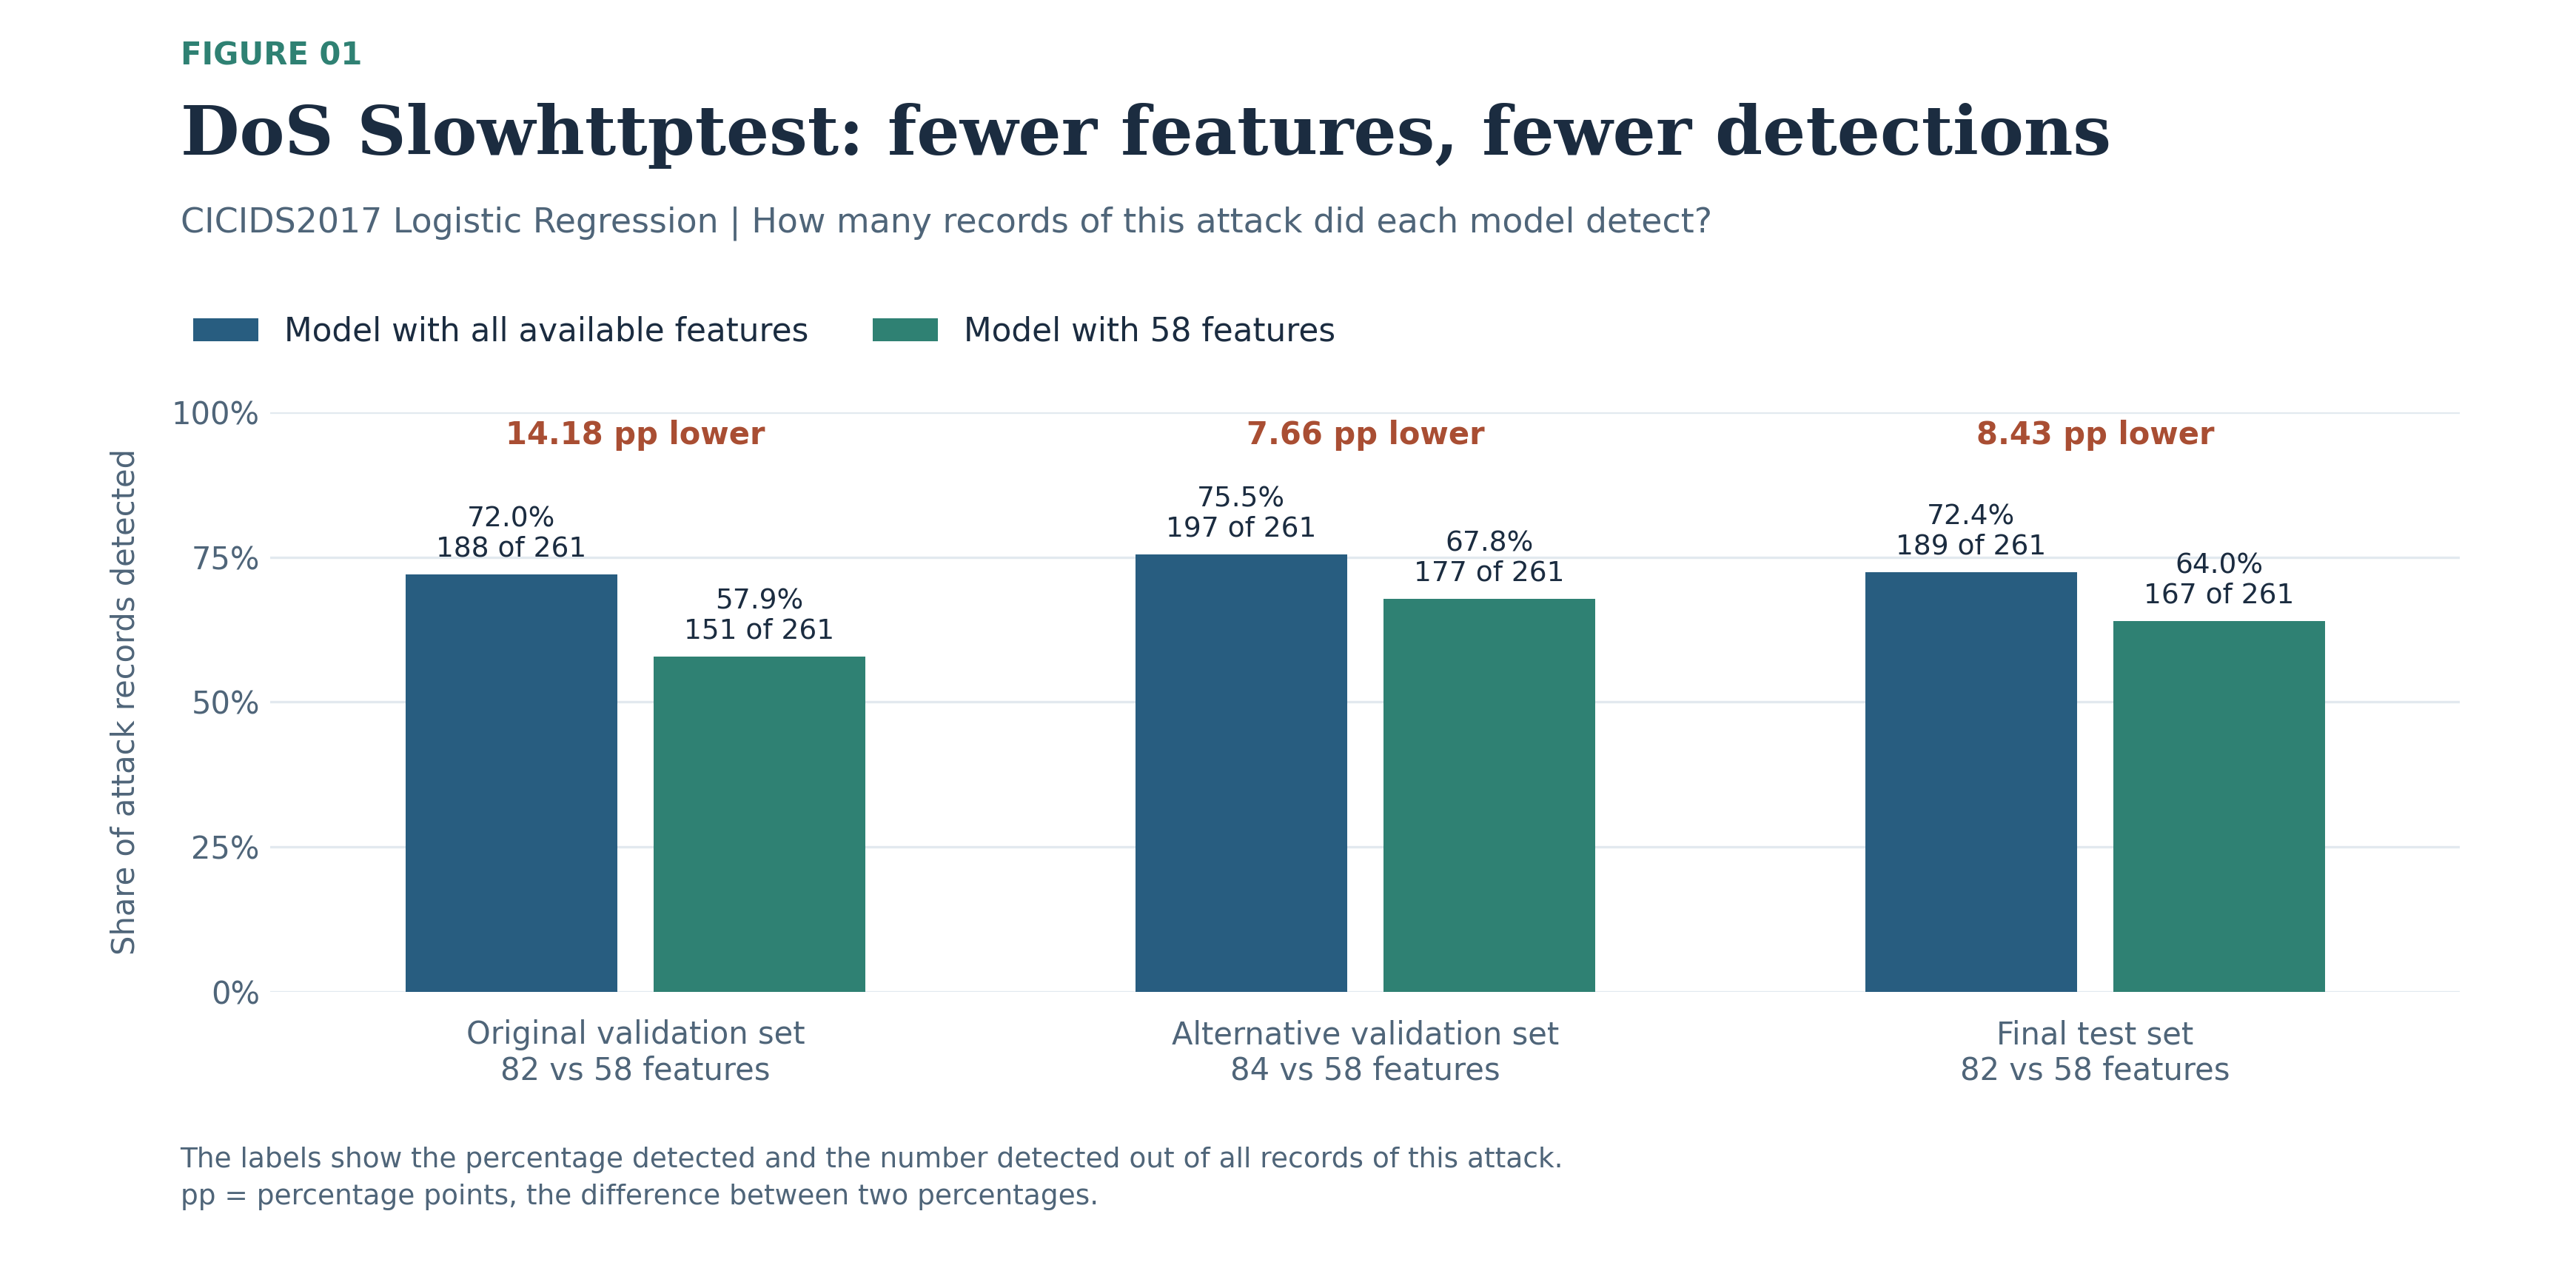

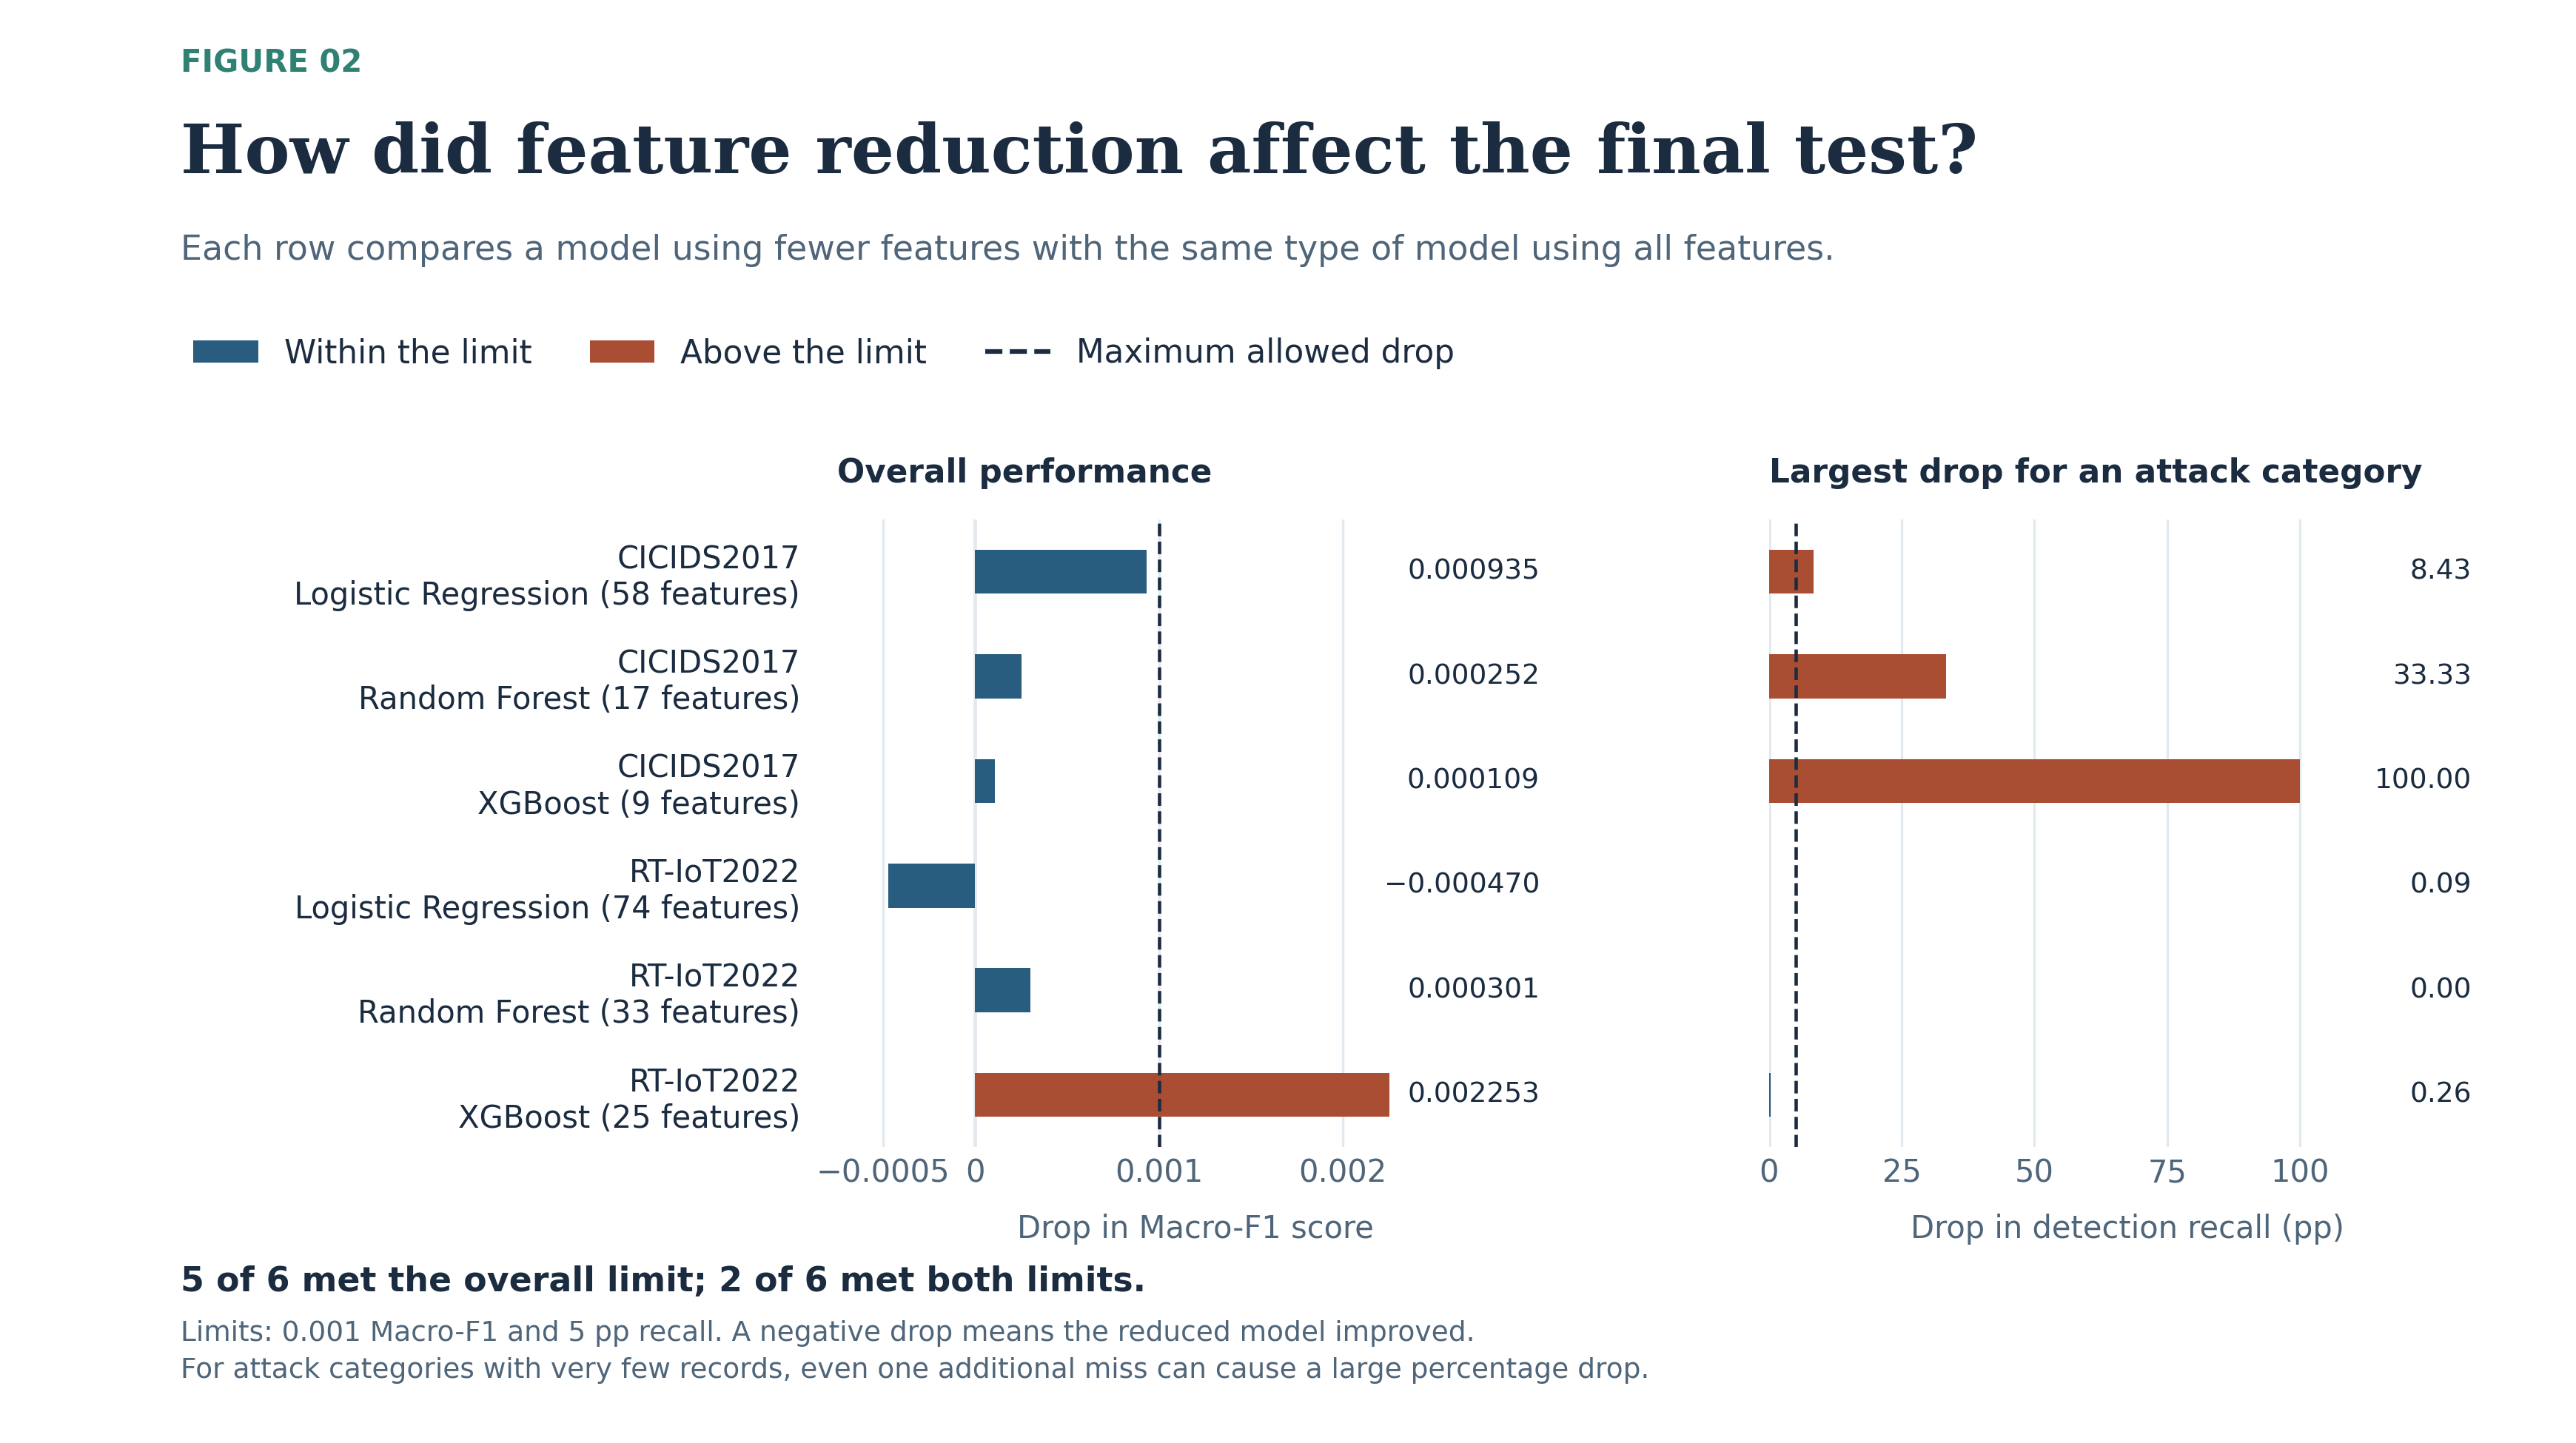

FIGURES SAVED AS PNG AND PDF: /content/thesis_drive_kbrjfmmn/MyDrive/Thesis_feature_reduction_results/figures_final


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from IPython.display import HTML, Image, display
import numpy as np
import pandas as pd

figure_dir = RESULTS_DIR / "figures_final"
figure_dir.mkdir(exist_ok=True)

INK = "#1B2C40"
MUTED = "#4F6579"
BLUE = "#285D80"
TEAL = "#2F8173"
RUST = "#A94E33"
GRID = "#E2E9EF"
TITLE_FONT = "DejaVu Serif"
BODY_FONT = "DejaVu Sans"

def figure_header(fig, number, title, subtitle):
    fig.text(0.07, 0.95, f"FIGURE {number:02d}",
             fontfamily=BODY_FONT, fontsize=10, fontweight="bold", color=TEAL)
    fig.text(0.07, 0.88, title,
             fontfamily=TITLE_FONT, fontsize=22, fontweight="bold", color=INK)
    fig.text(0.07, 0.82, subtitle,
             fontfamily=BODY_FONT, fontsize=11, color=MUTED)

def style_axes(ax, grid_axis):
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0, labelcolor=MUTED, labelsize=10)
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)

def export_figure(fig, name):
    png = figure_dir / f"{name}.png"
    fig.savefig(png, dpi=300, facecolor="white")
    fig.savefig(figure_dir / f"{name}.pdf", facecolor="white")
    plt.close(fig)
    return png

# Figure 1: detection recall across three evaluation splits
pair = ("CICIDS2017", "Logistic Regression")
category = "DoS Slowhttptest"

primary_full = reference_attack_reports[pair].loc[category]
primary_reduced = reduction_reports[(*pair, 58)].loc[category]
alternative = pd.read_csv(
    RESULTS_DIR / "cicids_lr58_alternative_split_recall.csv").set_index("Category").loc[category]

test_rows = final_test_attack_comparison.loc[
    final_test_attack_comparison["Dataset"].eq(pair[0])
    & final_test_attack_comparison["Model"].eq(pair[1])
    & final_test_attack_comparison["Category"].eq(category)
    & final_test_attack_comparison["Predictors"].eq(58)]
assert len(test_rows) == 1
assert primary_full["Support"] == primary_reduced["Support"]
test = test_rows.iloc[0]

support = np.array([
    primary_full["Support"], alternative["Support"], test["Support"]], dtype=int)
full = np.array([
    primary_full["Detected"], alternative["Full_detected"], test["Full detected"]], dtype=int)
reduced = np.array([
    primary_reduced["Detected"], alternative["Reduced_detected"], test["Reduced detected"]], dtype=int)

with plt.rc_context({"font.family": BODY_FONT, "pdf.fonttype": 42}):
    fig = plt.figure(figsize=(11.6, 5.8), facecolor="white")
    figure_header(
        fig, 1, "DoS Slowhttptest: fewer features, fewer detections",
        "CICIDS2017 Logistic Regression | How many records of this attack did each model detect?",)
    fig.legend(
        handles=[
            Patch(facecolor=BLUE, label="Model with all available features"),
            Patch(facecolor=TEAL, label="Model with 58 features"),
        ],
        loc="lower left", bbox_to_anchor=(0.07, 0.72),
        ncol=2, frameon=False, borderaxespad=0,
        fontsize=10.5, labelcolor=INK, columnspacing=2,)

    ax = fig.add_axes([0.105, 0.23, 0.85, 0.45])
    style_axes(ax, "y")
    x = np.arange(3)

    for counts, shift, color in [(full, -0.17, BLUE), (reduced, 0.17, TEAL)]:
        rates = 100 * counts / support
        bars = ax.bar(x + shift, rates, width=0.29, color=color, zorder=3)
        ax.bar_label(
            bars,
            labels=[f"{rate:.1f}%\n{n} of {total}"
                    for rate, n, total in zip(rates, counts, support)],
            padding=4, fontsize=9, color=INK, linespacing=1.12,)

    for i, loss in enumerate(100 * (full - reduced) / support):
        ax.text(i, 96, f"{loss:.2f} pp lower", ha="center", va="center",
                fontsize=10, fontweight="bold", color=RUST)

    ax.set(ylim=(0, 100), xlim=(-0.5, 2.5))
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.set_ylabel("Share of attack records detected", color=MUTED, labelpad=10)
    ax.set_xticks(x, [
        "Original validation set\n82 vs 58 features",
        "Alternative validation set\n84 vs 58 features",
        "Final test set\n82 vs 58 features",])
    ax.tick_params(axis="x", pad=9)
    fig.text(
        0.07, 0.065,
        "The labels show the percentage detected and the number detected out of all records of this attack.\n"
        "pp = percentage points, the difference between two percentages.",
        fontsize=9, color=MUTED, linespacing=1.5,)
    figure_1 = export_figure(fig, "slowhttptest_recall_across_splits")

    # Figure 2: overall performance versus the worst category result
    comparison = final_test_comparison
    f1_loss = comparison["Macro-F1 loss"].to_numpy()
    recall_loss = comparison["Worst recall loss (pp)"].to_numpy()
    f1_limit = frozen["macro_f1_tolerance"]
    recall_limit = 100 * frozen["attack_recall_tolerance"]
    n_models = len(comparison)
    n_f1 = int(comparison["Within Macro-F1 limit"].sum())
    n_both = int(comparison["Within both limits"].sum())

    fig = plt.figure(figsize=(11.6, 6.5), facecolor="white")
    figure_header(
        fig, 2, "How did feature reduction affect the final test?",
        "Each row compares a model using fewer features with the same type of model using all features.",)
    fig.legend(
        handles=[
            Patch(facecolor=BLUE, label="Within the limit"),
            Patch(facecolor=RUST, label="Above the limit"),
            Line2D([0], [0], color=INK, linestyle="--", label="Maximum allowed drop"),
        ],
        loc="lower left", bbox_to_anchor=(0.07, 0.735),
        ncol=3, frameon=False, borderaxespad=0,
        fontsize=10.5, labelcolor=INK, columnspacing=1.8,)

    panels = fig.add_gridspec(
        1, 2, left=0.325, right=0.965, bottom=0.205, top=0.64, wspace=0.30)
    left = fig.add_subplot(panels[0, 0])
    right = fig.add_subplot(panels[0, 1], sharey=left)

    for ax, values, limit, title, axis_label, decimals in [
        (left, f1_loss, f1_limit, "Overall performance",
         "Drop in Macro-F1 score", 6),
        (right, recall_loss, recall_limit, "Largest drop for an attack category",
         "Drop in detection recall (pp)", 2),]:
        style_axes(ax, "x")
        ax.set_title(title, loc="left", pad=12, fontsize=10.5,
                     fontweight="bold", color=INK)
        ax.axvline(0, color=GRID, linewidth=1.1)
        ax.axvline(limit, color=INK, linestyle="--", linewidth=1.1, zorder=4)
        ax.set_xlabel(axis_label, color=MUTED, labelpad=8)

        for i, value in enumerate(values):
            color = RUST if value > limit + 1e-10 else BLUE
            ax.barh(i, value, height=0.42, color=color, zorder=3)
            ax.text(
                0.98, i, f"{value:.{decimals}f}".replace("-", "−"),
                transform=ax.get_yaxis_transform(),
                ha="right", va="center", fontsize=9, color=INK,)

    row_labels = [
        f"{dataset}\n{model} ({k} features)"
        for dataset, model, k in zip(
            comparison["Dataset"], comparison["Model"], comparison["Reduced predictors"])]
    left.set_yticks(np.arange(n_models), row_labels, color=INK)
    left.set_ylim(n_models - 0.5, -0.5)
    left.tick_params(axis="y", pad=12)
    right.tick_params(axis="y", labelleft=False)

    left.set_xlim(min(-0.00075, f1_loss.min() - 0.00015),
                  max(0.00315, f1_loss.max() + 0.00085))
    left.set_xticks([-0.0005, 0, 0.001, 0.002], ["−0.0005", "0", "0.001", "0.002"])
    right.set_xlim(0, max(135, recall_loss.max() + 35))
    right.set_xticks([0, 25, 50, 75, 100])

    fig.text(
        0.07, 0.105,
        f"{n_f1} of {n_models} met the overall limit; {n_both} of {n_models} met both limits.",
        fontsize=11, fontweight="bold", color=INK,)
    fig.text(
        0.07, 0.045,
        f"Limits: {f1_limit:g} Macro-F1 and {recall_limit:g} pp recall. "
        "A negative drop means the reduced model improved.\n"
        "For attack categories with very few records, even one additional miss can cause a large percentage drop.",
        fontsize=9, color=MUTED, linespacing=1.5,)
    figure_2 = export_figure(fig, "held_out_test_losses")

display(Image(filename=str(figure_1), width=1040))
display(HTML('<div style="height: 28px;" aria-hidden="true"></div>'))
display(Image(filename=str(figure_2), width=1040))
print("FIGURES SAVED AS PNG AND PDF:", figure_dir)

### Final output check

This check verifies that all 12 held-out test evaluations, the six paired model comparisons, and both figures were saved. It also confirms that the six reduced models reproduced their original validation decisions at the fixed classification threshold.

In [ ]:
import pandas as pd

root = RESULTS_DIR
figures = root / "figures_final"

reference = pd.read_csv(root / "final_test_reference_metrics.csv")
reduced = pd.read_csv(root / "final_test_reduced_metrics.csv")
paired = pd.read_csv(root / "final_test_paired_metrics.csv")
attack_recall = pd.read_csv(root / "final_test_paired_attack_recall.csv")

assert len(reference) == len(reduced) == len(paired) == 6
assert reduced["Validation decision disagreements"].eq(0).all()

test_keys = ["Dataset", "Model", "Predictors"]
assert len(pd.concat([reference, reduced])[test_keys].drop_duplicates()) == 12
assert attack_recall[["Dataset", "Model", "Predictors"]].drop_duplicates().shape[0] == 6

for figure in ("slowhttptest_recall_across_splits", "held_out_test_losses"):
    for extension in ("png", "pdf"):
        path = figures / f"{figure}.{extension}"
        assert path.is_file() and path.stat().st_size > 0, f"Missing or empty: {path.name}"

print("Test evaluations: 12")
print("Paired comparisons: 6")
print("Validation decision disagreements: 0")
print("Figures: 2 PNG + 2 PDF")
print("FINAL OUTPUT CHECK PASSED")

Test evaluations: 12
Paired comparisons: 6
Validation decision disagreements: 0
Figures: 2 PNG + 2 PDF
FINAL OUTPUT CHECK PASSED
